# PN-Junction Phase Shifter Design

## Objective

Design and simulate a carrier-depletion silicon PN-junction phase shifter for a 1550 nm Mach–Zehnder modulator.

This notebook extends the passive strip-waveguide design into an active rib-waveguide structure containing a lateral PN junction. The design will be used to investigate the relationship between applied reverse bias, carrier distribution, plasma-dispersion-induced refractive-index change, optical effective index, phase shift, loss, and modulation efficiency.

### Design workflow

1. Construct and verify the passive rib-waveguide geometry.
2. Define the lateral PN-junction geometry and doping.
3. Model carrier distributions versus reverse-bias voltage.
4. Convert carrier-density changes into refractive-index and absorption changes using the plasma-dispersion effect.
5. Calculate the voltage-dependent optical effective index.
6. Calculate phase shift and $V_\pi L$.
7. Evaluate optical-loss and electrical-bandwidth tradeoffs.

### Initial reference geometry

- Wavelength: 1550 nm
- Silicon thickness: 220 nm
- Rib width: 500 nm
- Slab thickness: 90 nm
- Cladding/BOX: SiO₂

The initial rib geometry follows the reference PN-junction phase-shifter geometry from Chapter 6 and will be evaluated before the active junction is added.

In [1]:
# Import the numerical, plotting, and Tidy3D tools used throughout the phase-shifter notebook.

import numpy as np
import matplotlib.pyplot as plt
import tidy3d as td

from tidy3d.plugins.mode import ModeSolver

print(f"Tidy3D version: {td.__version__}")

Tidy3D version: 2.12.0


In [2]:
# Define the wavelength, material indices, and initial rib-waveguide geometry.

wavelength = 1.55  # Operating wavelength [um]

n_si = 3.47        # Approximate silicon refractive index at 1550 nm
n_sio2 = 1.44      # Approximate SiO2 refractive index at 1550 nm

rib_width = 0.50   # Rib width [um]
si_height = 0.22   # Total silicon thickness [um]
slab_height = 0.09 # Remaining silicon slab thickness [um]

etch_depth = si_height - slab_height

print(f"Wavelength: {wavelength:.2f} um")
print(f"Rib width: {rib_width * 1000:.0f} nm")
print(f"Silicon height: {si_height * 1000:.0f} nm")
print(f"Slab height: {slab_height * 1000:.0f} nm")
print(f"Etch depth: {etch_depth * 1000:.0f} nm")

Wavelength: 1.55 um
Rib width: 500 nm
Silicon height: 220 nm
Slab height: 90 nm
Etch depth: 130 nm


In [3]:
# Create the silicon and SiO2 materials and construct the initial rib-waveguide geometry.

silicon = td.Medium(permittivity=n_si**2)
silica = td.Medium(permittivity=n_sio2**2)

slab = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, td.inf, slab_height),
    ),
    medium=silicon,
)

rib = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + etch_depth / 2),
        size=(td.inf, rib_width, etch_depth),
    ),
    medium=silicon,
)

print("Rib-waveguide geometry created.")

Rib-waveguide geometry created.


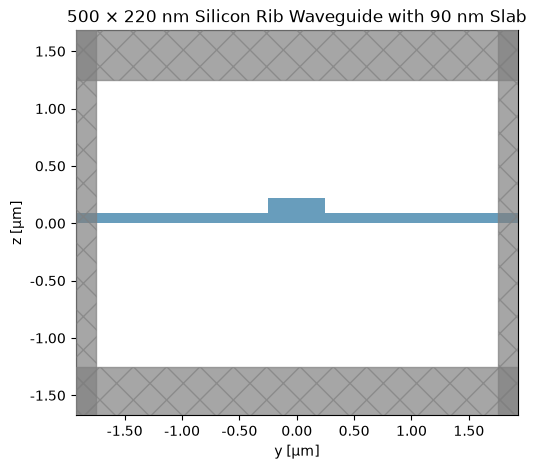

In [4]:
# Create the optical simulation domain and visualize the rib-waveguide cross-section.

domain_y = 3.5  # Lateral simulation width [um]
domain_z = 2.5  # Vertical simulation height [um]

sim = td.Simulation(
    size=(1.0, domain_y, domain_z),
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=30,
        wavelength=wavelength,
    ),
    structures=[slab, rib],
    medium=silica,
    run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
)

fig, ax = plt.subplots(figsize=(8, 5))
sim.plot(x=0, ax=ax)

ax.set_title("500 × 220 nm Silicon Rib Waveguide with 90 nm Slab")
ax.set_xlabel("y [µm]")
ax.set_ylabel("z [µm]")

plt.show()

In [5]:
# Solve for the optical modes of the passive rib-waveguide cross-section at 1550 nm.

freq0 = td.C_0 / wavelength

mode_plane = td.Box(
    center=(0, 0, si_height / 2),
    size=(0, domain_y, domain_z),
)

mode_solver = ModeSolver(
    simulation=sim,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=4,
        target_neff=n_si,
    ),
    freqs=[freq0],
)

mode_data = mode_solver.solve()

mode_data.to_dataframe()

18:11:48 Central Daylight Time WARNING: Use the remote mode solver with subpixel
                               averaging for better accuracy through            
                               'tidy3d.web.run(...)' or the deprecated          
                               'tidy3d.plugins.mode.web.run(...)'.              
                               Alternatively, you can install the package       
                               'tidy3d-extras' using 'pip install "tidy3d"' and 
                               set 'config.simulation.use_local_subpixel=True'. 

18:11:50 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
1.934145e+14 0                 1.55  2.571373    0.0           0.0   
             1                 1.55  2.121374    0.0           0.0   
             2                 1.55  2.094141    0.0           0.0   
             3                 1.55  2.069267    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.989196        0.873134        0.802868   
             1                   0.964136        0.948560        0.755730   
             2                   0.999940        0.985464        0.730081   
             3                   0.966535        0.917745        0.758875   

                         mode area  
f            mode_index             
1.934145e+14 0            0.202303  
             1            0.919951  
             2            0.741617  
             3            0.779215

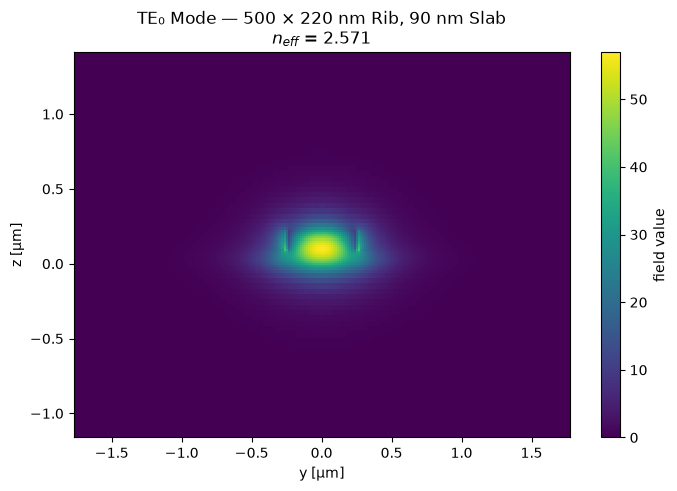

In [6]:
# Visualize the fundamental TE-like mode of the passive rib-waveguide cross-section.

fig, ax = plt.subplots(figsize=(8, 5))

mode_data.Ey.isel(f=0, mode_index=0).real.plot(
    x="y",
    y="z",
    ax=ax,
)

ax.set_title(
    f"TE₀ Mode — 500 × 220 nm Rib, 90 nm Slab\n"
    f"$n_{{eff}}$ = {2.571373:.3f}"
)
ax.set_xlabel("y [µm]")
ax.set_ylabel("z [µm]")

plt.show()

In [7]:
# Define the initial lateral PN-junction doping, position, and reverse-bias operating range.

NA = 1e17  # P-type acceptor concentration [cm^-3]
ND = 1e17  # N-type donor concentration [cm^-3]

junction_offset = 0.05  # PN junction offset from waveguide center [um]

voltages = np.array([0, -1, -2, -3, -4])  # Applied junction voltages [V]

print(f"P-type doping (NA): {NA:.2e} cm^-3")
print(f"N-type doping (ND): {ND:.2e} cm^-3")
print(f"Junction offset: {junction_offset * 1000:.0f} nm")
print(f"Voltages: {voltages} V")

P-type doping (NA): 1.00e+17 cm^-3
N-type doping (ND): 1.00e+17 cm^-3
Junction offset: 50 nm
Voltages: [ 0 -1 -2 -3 -4] V


In [8]:
# Calculate the PN-junction built-in voltage and depletion width versus reverse-bias voltage.

q = 1.602e-19          # Elementary charge [C]
eps0 = 8.854e-14       # Vacuum permittivity [F/cm]
eps_si_rel = 11.7      # Relative permittivity of silicon
eps_si = eps0 * eps_si_rel

k_B = 1.381e-23        # Boltzmann constant [J/K]
T = 300                 # Temperature [K]
ni = 1.0e10             # Approximate intrinsic carrier concentration of Si [cm^-3]

V_T = k_B * T / q

V_bi = V_T * np.log((NA * ND) / ni**2)

W_cm = np.sqrt(
    (2 * eps_si / q)
    * ((NA + ND) / (NA * ND))
    * (V_bi - voltages)
)

W_um = W_cm * 1e4

# Depletion extension into each side of the junction
xp_um = W_um * ND / (NA + ND)
xn_um = W_um * NA / (NA + ND)

print(f"Built-in voltage: {V_bi:.3f} V")
print("\nVoltage [V]   Total Wd [um]   P-side [um]   N-side [um]")

for V, W, xp, xn in zip(voltages, W_um, xp_um, xn_um):
    print(f"{V:>6.1f}        {W:>8.3f}        {xp:>8.3f}      {xn:>8.3f}")

Built-in voltage: 0.834 V

Voltage [V]   Total Wd [um]   P-side [um]   N-side [um]
   0.0           0.147           0.073         0.073
  -1.0           0.218           0.109         0.109
  -2.0           0.271           0.135         0.135
  -3.0           0.315           0.157         0.157
  -4.0           0.354           0.177         0.177


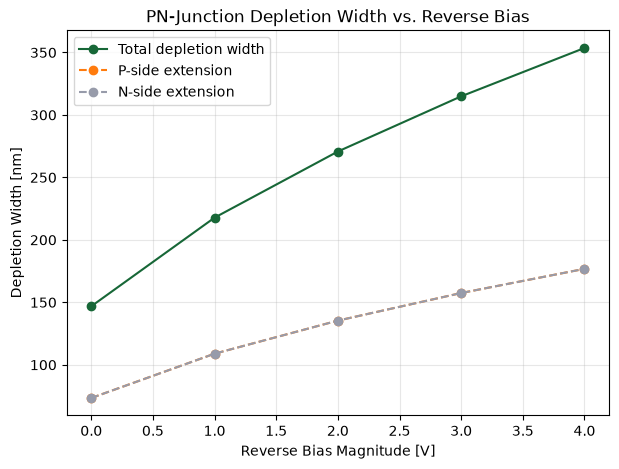

In [9]:
# Plot the total depletion width and its extension into the P and N sides versus applied voltage.

fig, ax = plt.subplots(figsize=(7, 5))

reverse_bias = -voltages

ax.plot(reverse_bias, W_um * 1000, "o-", label="Total depletion width")
ax.plot(reverse_bias, xp_um * 1000, "o--", label="P-side extension")
ax.plot(reverse_bias, xn_um * 1000, "o--", label="N-side extension")

ax.set_xlabel("Reverse Bias Magnitude [V]")
ax.set_ylabel("Depletion Width [nm]")
ax.set_title("PN-Junction Depletion Width vs. Reverse Bias")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

In [10]:
# Construct 2D electron and hole concentration maps across the rib waveguide for each applied voltage.

y = np.linspace(-1.0, 1.0, 801)   # Lateral coordinate [um]
z = np.linspace(0.0, si_height, 221)  # Vertical coordinate [um]

Y, Z = np.meshgrid(y, z)

# Define which points belong to the silicon rib/slab.
silicon_mask = (
    (Z <= slab_height) |
    ((np.abs(Y) <= rib_width / 2) & (Z <= si_height))
)

carrier_maps = {}

for V, xp, xn in zip(voltages, xp_um, xn_um):

    # Position of the depletion-region boundaries.
    y_left = junction_offset - xp
    y_right = junction_offset + xn

    # Initialize carrier concentrations.
    N = np.zeros_like(Y)
    P = np.zeros_like(Y)

    # Neutral P-type and N-type regions.
    p_region = silicon_mask & (Y < y_left)
    n_region = silicon_mask & (Y > y_right)

    P[p_region] = NA
    N[n_region] = ND

    carrier_maps[V] = {
        "N": N,
        "P": P,
        "y_left": y_left,
        "y_right": y_right,
    }

print("Carrier-density maps created for:", list(carrier_maps.keys()), "V")

Carrier-density maps created for: [np.int64(0), np.int64(-1), np.int64(-2), np.int64(-3), np.int64(-4)] V


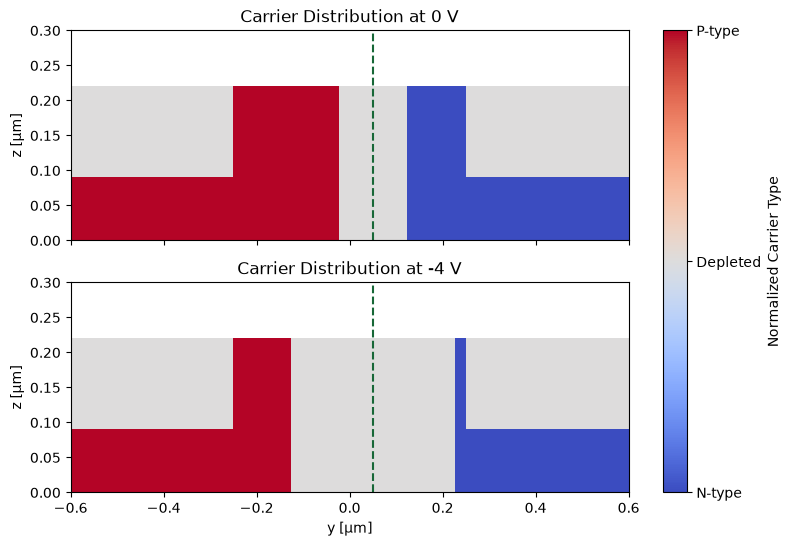

In [11]:
# Visualize the carrier-density distribution at 0 V and -4 V to show depletion-region expansion.

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

for ax, V in zip(axes, [0, -4]):
    N = carrier_maps[V]["N"]
    P = carrier_maps[V]["P"]

    # Positive values represent holes; negative values represent electrons.
    signed_carriers = (P - N) / 1e17

    im = ax.pcolormesh(
        Y,
        Z,
        signed_carriers,
        shading="auto",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
    )

    ax.axvline(
        junction_offset,
        linestyle="--",
        linewidth=1.5,
        label="PN junction",
    )

    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(0, 0.30)
    ax.set_ylabel("z [µm]")
    ax.set_title(f"Carrier Distribution at {V} V")

axes[-1].set_xlabel("y [µm]")

cbar = fig.colorbar(im, ax=axes, label="Normalized Carrier Type")
cbar.set_ticks([-1, 0, 1])
cbar.set_ticklabels(["N-type", "Depleted", "P-type"])

plt.show()

In [12]:
# Convert voltage-dependent carrier changes into refractive-index and absorption changes using the plasma-dispersion model.

N0 = carrier_maps[0]["N"]
P0 = carrier_maps[0]["P"]

plasma_maps = {}

for V in voltages:
    N = carrier_maps[V]["N"]
    P = carrier_maps[V]["P"]

    # Carrier-density changes relative to the 0 V state [cm^-3].
    delta_N = N - N0
    delta_P = P - P0

    # Soref-Bennett plasma-dispersion relations near 1550 nm.
    delta_n = -(8.8e-22 * delta_N + 8.5e-18 * np.sign(delta_P) * np.abs(delta_P)**0.8)
    delta_alpha = 8.5e-18 * delta_N + 6.0e-18 * delta_P

    # Only silicon contributes to the carrier-induced optical change.
    delta_n[~silicon_mask] = 0
    delta_alpha[~silicon_mask] = 0

    plasma_maps[V] = {
        "delta_N": delta_N,
        "delta_P": delta_P,
        "delta_n": delta_n,
        "delta_alpha": delta_alpha,
    }

print("Plasma-dispersion maps created for:", list(plasma_maps.keys()), "V")

Plasma-dispersion maps created for: [np.int64(0), np.int64(-1), np.int64(-2), np.int64(-3), np.int64(-4)] V


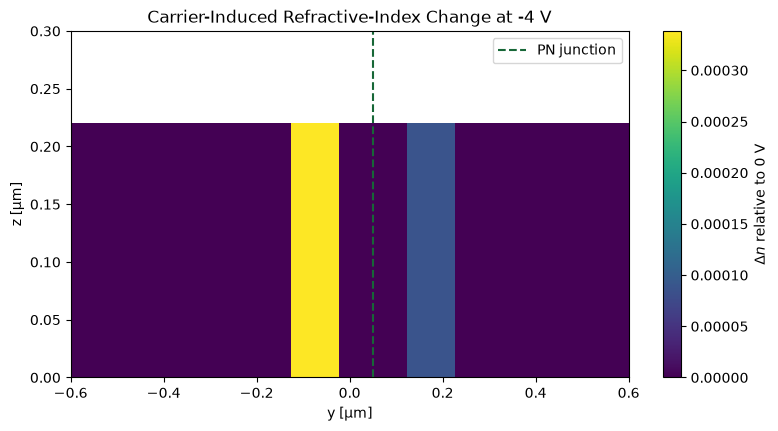

Maximum Δn at -4 V: 3.384e-04
Minimum Δn at -4 V: 0.000e+00


In [13]:
# Visualize the carrier-induced refractive-index change at -4 V relative to the 0 V state.

V_plot = -4

delta_n_plot = plasma_maps[V_plot]["delta_n"]

fig, ax = plt.subplots(figsize=(9, 4.5))

im = ax.pcolormesh(
    Y,
    Z,
    delta_n_plot,
    shading="auto",
    cmap="viridis",
)

ax.axvline(
    junction_offset,
    linestyle="--",
    linewidth=1.5,
    label="PN junction",
)

ax.set_xlim(-0.6, 0.6)
ax.set_ylim(0, 0.30)
ax.set_xlabel("y [µm]")
ax.set_ylabel("z [µm]")
ax.set_title("Carrier-Induced Refractive-Index Change at -4 V")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta n$ relative to 0 V")

ax.legend()

plt.show()

print(f"Maximum Δn at {V_plot} V: {np.max(delta_n_plot):.3e}")
print(f"Minimum Δn at {V_plot} V: {np.min(delta_n_plot):.3e}")

In [14]:
# Convert the -4 V carrier-induced index map into a spatially varying silicon permittivity dataset for Tidy3D.

V_test = -4

# Local refractive index of silicon after applying the carrier-induced change.
n_map = n_si + plasma_maps[V_test]["delta_n"]

# Convert refractive index to relative permittivity: epsilon_r = n^2.
eps_map = n_map**2

# Tidy3D expects spatial data with explicit x, y, and z dimensions.
eps_dataset = td.SpatialDataArray(
    eps_map.T[np.newaxis, :, :],
    coords={
        "x": [0.0],
        "y": y,
        "z": z,
    },
)

print(f"Voltage: {V_test} V")
print(f"Base silicon index: {n_si:.6f}")
print(f"Maximum local silicon index: {np.max(n_map):.6f}")
print(f"Maximum local Δn: {np.max(plasma_maps[V_test]['delta_n']):.3e}")

Voltage: -4 V
Base silicon index: 3.470000
Maximum local silicon index: 3.470338
Maximum local Δn: 3.384e-04


In [15]:
# Create a spatially varying silicon medium containing the -4 V refractive-index distribution.

eps_field = td.SpatialDataArray(
    eps_map.T[np.newaxis, :, :],
    coords={
        "x": [0.0],
        "y": y,
        "z": z,
    },
)

silicon_V_test = td.CustomMedium(
    permittivity=eps_field,
    interp_method="linear",
)

print(f"Spatial silicon medium created for {V_test} V.")
print(f"Dataset dimensions: {eps_field.dims}")
print(f"Dataset shape: {eps_field.shape}")

Spatial silicon medium created for -4 V.
Dataset dimensions: ('x', 'y', 'z')
Dataset shape: (1, 801, 221)


In [16]:
# Rebuild the biased rib using finite silicon structures fully covered by the custom permittivity dataset.

mapped_width = y[-1] - y[0]

slab_V_test = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, mapped_width, slab_height),
    ),
    medium=silicon_V_test,
)

rib_V_test = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + etch_depth / 2),
        size=(td.inf, rib_width, etch_depth),
    ),
    medium=silicon_V_test,
)

sim_V_test = td.Simulation(
    size=(1.0, domain_y, domain_z),
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=30,
        wavelength=wavelength,
    ),
    structures=[slab_V_test, rib_V_test],
    medium=silica,
    run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
)

mode_solver_V_test = ModeSolver(
    simulation=sim_V_test,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=1,
        target_neff=2.57,
    ),
    freqs=[freq0],
)

mode_data_V_test = mode_solver_V_test.solve()

mode_data_V_test.to_dataframe()

,,wavelength,n eff,k eff,loss (dB/cm),TE (Ey) fraction,wg TE fraction,wg TM fraction,mode area
f,mode_index,,,,,,,,
1.934145e+14,0,1.55,2.522457,0.0,0.0,0.986709,0.874229,0.793021,0.207033


In [17]:
# Solve the 0 V reference using exactly the same finite geometry and spatial-material method as the -4 V model.

n_map_0V = n_si + plasma_maps[0]["delta_n"]
eps_map_0V = n_map_0V**2

eps_field_0V = td.SpatialDataArray(
    eps_map_0V.T[np.newaxis, :, :],
    coords={
        "x": [0.0],
        "y": y,
        "z": z,
    },
)

silicon_0V = td.CustomMedium(
    permittivity=eps_field_0V,
    interp_method="linear",
)

slab_0V = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, mapped_width, slab_height),
    ),
    medium=silicon_0V,
)

rib_0V = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + etch_depth / 2),
        size=(td.inf, rib_width, etch_depth),
    ),
    medium=silicon_0V,
)

sim_0V = sim_V_test.updated_copy(
    structures=[slab_0V, rib_0V]
)

mode_solver_0V = ModeSolver(
    simulation=sim_0V,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=1,
        target_neff=2.57,
    ),
    freqs=[freq0],
)

mode_data_0V = mode_solver_0V.solve()

neff_0V = float(mode_data_0V.n_eff.isel(f=0, mode_index=0))
neff_m4V = float(mode_data_V_test.n_eff.isel(f=0, mode_index=0))
delta_neff_m4V = neff_m4V - neff_0V

print(f"n_eff(0 V)  = {neff_0V:.8f}")
print(f"n_eff(-4 V) = {neff_m4V:.8f}")
print(f"Δn_eff      = {delta_neff_m4V:.3e}")

n_eff(0 V)  = 2.56413414
n_eff(-4 V) = 2.52245664
Δn_eff      = -4.168e-02


In [18]:
# Verify the actual refractive index that Tidy3D assigns at representative points in the 0 V and -4 V custom media.

test_y = np.array([-0.15, 0.00, 0.05, 0.15, 0.30])
test_z = np.array([0.15])

test_coords = td.Coords(
    x=np.array([0.0]),
    y=test_y,
    z=test_z,
)

eps_0_check = silicon_0V.eps_diagonal_on_grid(freq0, test_coords)[0]
eps_m4_check = silicon_V_test.eps_diagonal_on_grid(freq0, test_coords)[0]

n_0_check = np.sqrt(np.real(eps_0_check)).squeeze()
n_m4_check = np.sqrt(np.real(eps_m4_check)).squeeze()

print("      y (µm)      n(0 V)       n(-4 V)       Δn")
print("---------------------------------------------------")

for yi, n0i, n4i in zip(test_y, n_0_check, n_m4_check):
    print(f"     {yi:+.3f}       {n0i:.6f}      {n4i:.6f}     {n4i-n0i:+.3e}")

      y (µm)      n(0 V)       n(-4 V)       Δn
---------------------------------------------------
     -0.150       3.470000      3.470000     +0.000e+00
     +0.000       3.470000      3.470000     +0.000e+00
     +0.050       3.470000      3.470000     +0.000e+00
     +0.150       3.470000      3.470088     +8.800e-05
     +0.300       3.470000      3.470000     +0.000e+00


In [19]:
# Compare the raw plasma-dispersion map with Tidy3D's interpreted refractive index along the waveguide center height.

z_test = 0.15
z_idx = np.argmin(np.abs(z - z_test))

print(f"Using z = {z[z_idx]:.4f} µm")
print()
print("      y        raw Δn map       expected n(-4V)")
print("------------------------------------------------")

for yi in test_y:
    y_idx = np.argmin(np.abs(y - yi))
    raw_dn = plasma_maps[-4]["delta_n"][z_idx, y_idx]
    expected_n = n_si + raw_dn

    print(
        f"   {y[y_idx]:+.3f}       "
        f"{raw_dn:+.3e}          "
        f"{expected_n:.6f}"
    )

Using z = 0.1500 µm

      y        raw Δn map       expected n(-4V)
------------------------------------------------
   -0.150       -0.000e+00          3.470000
   +0.000       -0.000e+00          3.470000
   +0.050       -0.000e+00          3.470000
   +0.150       +8.800e-05          3.470088
   +0.300       +0.000e+00          3.470000


In [20]:
# Test whether the mode solver responds correctly to a small uniform increase in the silicon refractive index.

delta_n_test = 1e-4

silicon_test_uniform = td.Medium(
    permittivity=(n_si + delta_n_test)**2
)

slab_test_uniform = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, mapped_width, slab_height),
    ),
    medium=silicon_test_uniform,
)

rib_test_uniform = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + etch_depth / 2),
        size=(td.inf, rib_width, etch_depth),
    ),
    medium=silicon_test_uniform,
)

sim_test_uniform = sim_V_test.updated_copy(
    structures=[slab_test_uniform, rib_test_uniform]
)

mode_solver_test_uniform = ModeSolver(
    simulation=sim_test_uniform,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=1,
        target_neff=2.57,
    ),
    freqs=[freq0],
)

mode_data_test_uniform = mode_solver_test_uniform.solve()

neff_uniform = float(
    mode_data_test_uniform.n_eff.isel(f=0, mode_index=0)
)

print(f"Custom-medium 0 V n_eff = {neff_0V:.8f}")
print(f"Uniform +1e-4 n_eff      = {neff_uniform:.8f}")
print(f"Δn_eff                   = {neff_uniform - neff_0V:+.3e}")

Custom-medium 0 V n_eff = 2.56413414
Uniform +1e-4 n_eff      = 2.49795563
Δn_eff                   = -6.618e-02


In [21]:
# Compare identical n=3.47 silicon represented by ordinary Medium and CustomMedium using the same geometry.

silicon_uniform_exact = td.Medium(
    permittivity=n_si**2
)

slab_uniform_exact = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, mapped_width, slab_height),
    ),
    medium=silicon_uniform_exact,
)

rib_uniform_exact = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + etch_depth / 2),
        size=(td.inf, rib_width, etch_depth),
    ),
    medium=silicon_uniform_exact,
)

sim_uniform_exact = sim_V_test.updated_copy(
    structures=[slab_uniform_exact, rib_uniform_exact]
)

solver_uniform_exact = ModeSolver(
    simulation=sim_uniform_exact,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=1,
        target_neff=2.57,
    ),
    freqs=[freq0],
)

data_uniform_exact = solver_uniform_exact.solve()

neff_uniform_exact = float(
    data_uniform_exact.n_eff.isel(f=0, mode_index=0)
)

print(f"Ordinary Medium n_eff = {neff_uniform_exact:.8f}")
print(f"CustomMedium 0 V n_eff = {neff_0V:.8f}")
print(f"Difference = {neff_0V - neff_uniform_exact:+.3e}")

Ordinary Medium n_eff = 2.56413414
CustomMedium 0 V n_eff = 2.56413414
Difference = +4.441e-16


Maximum input n:       3.47033839
Minimum input n:       3.47000000
Maximum Tidy3D n:      3.47033839
Minimum Tidy3D n:      3.47000000
Maximum |difference|:  0.000e+00


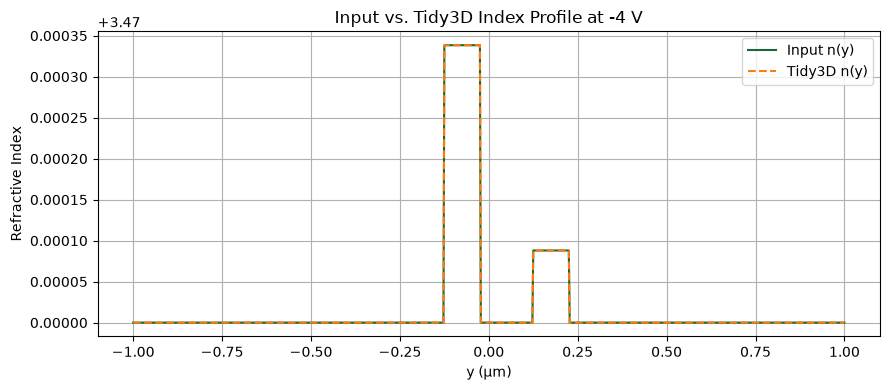

In [22]:
# Compare the complete input refractive-index profile with the profile interpreted by Tidy3D at the rib center height.

z_check = 0.15

check_coords = td.Coords(
    x=np.array([0.0]),
    y=y,
    z=np.array([z_check]),
)

eps_tidy = silicon_V_test.eps_diagonal_on_grid(
    freq0,
    check_coords,
)[0]

n_tidy = np.sqrt(np.real(eps_tidy)).squeeze()

z_idx = np.argmin(np.abs(z - z_check))
n_input = n_si + plasma_maps[-4]["delta_n"][z_idx, :]

difference = n_tidy - n_input

print(f"Maximum input n:       {np.max(n_input):.8f}")
print(f"Minimum input n:       {np.min(n_input):.8f}")
print(f"Maximum Tidy3D n:      {np.max(n_tidy):.8f}")
print(f"Minimum Tidy3D n:      {np.min(n_tidy):.8f}")
print(f"Maximum |difference|:  {np.max(np.abs(difference)):.3e}")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(y, n_input, label="Input n(y)")
ax.plot(y, n_tidy, "--", label="Tidy3D n(y)")

ax.set_xlabel("y (µm)")
ax.set_ylabel("Refractive Index")
ax.set_title("Input vs. Tidy3D Index Profile at -4 V")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

In [23]:
# Compare several eigenmodes at 0 V and -4 V to determine whether the solver is tracking the same TE0 mode.

solver_0V_multi = ModeSolver(
    simulation=sim_0V,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=4,
        target_neff=2.57,
    ),
    freqs=[freq0],
)

solver_m4V_multi = ModeSolver(
    simulation=sim_V_test,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=4,
        target_neff=2.57,
    ),
    freqs=[freq0],
)

data_0V_multi = solver_0V_multi.solve()
data_m4V_multi = solver_m4V_multi.solve()

df_0V = data_0V_multi.to_dataframe()
df_m4V = data_m4V_multi.to_dataframe()

print("0 V modes:")
display(df_0V)

print("\n-4 V modes:")
display(df_m4V)

0 V modes:


wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
1.934145e+14 0                 1.55  2.564134    0.0           0.0   
             1                 1.55  2.095606    0.0           0.0   
             2                 1.55  1.929673    0.0           0.0   
             3                 1.55  1.821966    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.986984        0.869841        0.802120   
             1                   0.920893        0.877655        0.784063   
             2                   0.993086        0.841457        0.779113   
             3                   0.235820        0.689180        0.881983   

                         mode area  
f            mode_index             
1.934145e+14 0            0.204190  
             1            0.469464  
             2            0.597170  
             3            0.524160


-4 V modes:


wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
1.934145e+14 0                 1.55  2.522457    0.0           0.0   
             1                 1.55  2.079696    0.0           0.0   
             2                 1.55  1.920559    0.0           0.0   
             3                 1.55  1.770446    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.986709        0.874229        0.793021   
             1                   0.942789        0.884932        0.780706   
             2                   0.992874        0.834155        0.780856   
             3                   0.311611        0.698193        0.870167   

                         mode area  
f            mode_index             
1.934145e+14 0            0.207033  
             1            0.483252  
             2            0.602021  
             3            0.654086

In [24]:
# Rebuild the biased rib using finite silicon structures fully covered by the custom permittivity dataset.

mapped_width = y[-1] - y[0]

slab_V_test = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, mapped_width, slab_height),
    ),
    medium=silicon_V_test,
)

rib_V_test = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + etch_depth / 2),
        size=(td.inf, rib_width, etch_depth),
    ),
    medium=silicon_V_test,
)

sim_V_test = td.Simulation(
    size=(1.0, domain_y, domain_z),
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=30,
        wavelength=wavelength,
    ),
    structures=[slab_V_test, rib_V_test],
    medium=silica,
    run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
)

mode_solver_V_test = ModeSolver(
    simulation=sim_V_test,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=1,
        target_neff=2.57,
    ),
    freqs=[freq0],
)

mode_data_V_test = mode_solver_V_test.solve()

mode_data_V_test.to_dataframe()

,,wavelength,n eff,k eff,loss (dB/cm),TE (Ey) fraction,wg TE fraction,wg TM fraction,mode area
f,mode_index,,,,,,,,
1.934145e+14,0,1.55,2.522457,0.0,0.0,0.986709,0.874229,0.793021,0.207033


In [25]:
# Run the existing 0 V and -4 V mode solvers on Flexcompute's server and compare their effective indices.

from tidy3d.plugins.mode.web import run as run_mode_solver

mode_data_0V_remote = run_mode_solver(
    mode_solver_0V,
    task_name="PN_phase_shifter_0V",
)

mode_data_m4V_remote = run_mode_solver(
    mode_solver_V_test,
    task_name="PN_phase_shifter_m4V",
)

neff_0V_remote = float(
    mode_data_0V_remote.n_eff.isel(f=0, mode_index=0)
)

neff_m4V_remote = float(
    mode_data_m4V_remote.n_eff.isel(f=0, mode_index=0)
)

delta_neff_remote = neff_m4V_remote - neff_0V_remote

print(f"Remote n_eff(0 V)  = {neff_0V_remote:.8f}")
print(f"Remote n_eff(-4 V) = {neff_m4V_remote:.8f}")
print(f"Remote Δn_eff      = {delta_neff_remote:+.3e}")

18:11:59 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

18:12:00 Central Daylight Time Mode solver created with                         
                               task_id='fdve-08c63b4a-eaf9-4f07-bcc9-9de7386e3e7
                               c',                                              
                               solver_id='mo-79b1a212-7bdf-41fe-9e15-d323bcfa921
                               3'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:12:05 Central Daylight Time Mode solver status: success

18:12:06 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

18:12:07 Central Daylight Time Mode solver created with                         
                               task_id='fdve-85b1ac36-6f5f-4d52-b6da-efda0dba66b
                               1',                                              
                               solver_id='mo-92ded587-648a-4336-9057-1d8271ede9c
                               4'.

18:12:08 Central Daylight Time Mode solver status: success

Remote n_eff(0 V)  = 2.63153495
Remote n_eff(-4 V) = 2.63161968
Remote Δn_eff      = +8.474e-05


In [26]:
# Remotely solve the fundamental TE mode at each reverse-bias voltage to obtain n_eff(V) and Δn_eff(V).

from tidy3d.plugins.mode.web import run as run_mode_solver

neff_vs_voltage = []

for V in voltages:

    # Build the voltage-dependent refractive-index map.
    n_map_V = n_si + plasma_maps[V]["delta_n"]
    eps_map_V = n_map_V**2

    # Convert the permittivity map into a Tidy3D spatial dataset.
    eps_field_V = td.SpatialDataArray(
        eps_map_V.T[np.newaxis, :, :],
        coords={
            "x": [0.0],
            "y": y,
            "z": z,
        },
    )

    silicon_V = td.CustomMedium(
        permittivity=eps_field_V,
        interp_method="linear",
    )

    # Construct the finite rib-waveguide geometry.
    slab_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height / 2),
            size=(td.inf, mapped_width, slab_height),
        ),
        medium=silicon_V,
    )

    rib_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height + etch_depth / 2),
            size=(td.inf, rib_width, etch_depth),
        ),
        medium=silicon_V,
    )

    # Use the same optical simulation setup at every voltage.
    sim_V = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=30,
            wavelength=wavelength,
        ),
        structures=[slab_V, rib_V],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
    )

    solver_V = ModeSolver(
        simulation=sim_V,
        plane=mode_plane,
        mode_spec=td.ModeSpec(
            num_modes=1,
            target_neff=2.63,
        ),
        freqs=[freq0],
    )

    # Run the mode calculation using Flexcompute's server-side solver.
    mode_data_V = run_mode_solver(
        solver_V,
        task_name=f"PN_phase_shifter_{abs(int(V))}V",
    )

    neff_V = float(
        mode_data_V.n_eff.isel(f=0, mode_index=0)
    )

    neff_vs_voltage.append(neff_V)

    print(f"V = {V:>2.0f} V  |  n_eff = {neff_V:.8f}")


neff_vs_voltage = np.array(neff_vs_voltage)

# Reference all effective-index changes to the 0 V state.
delta_neff_vs_voltage = neff_vs_voltage - neff_vs_voltage[0]

print("\nVoltage-dependent effective-index change:")
for V, neff_V, dneff_V in zip(
    voltages,
    neff_vs_voltage,
    delta_neff_vs_voltage,
):
    print(
        f"V = {V:>2.0f} V  |  "
        f"n_eff = {neff_V:.8f}  |  "
        f"Δn_eff = {dneff_V:+.3e}"
    )

18:12:10 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-fe77fa93-ca17-48cd-9678-dfb67aad313
                               f',                                              
                               solver_id='mo-c0f03325-180b-423a-91c5-ed4ad92529f
                               2'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:12:12 Central Daylight Time Mode solver status: success

V =  0 V  |  n_eff = 2.63153495


...

18:12:25 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

18:12:26 Central Daylight Time Mode solver created with                         
                               task_id='fdve-cd2268c9-084f-4007-a323-1abe4d5d2f5
                               9',                                              
                               solver_id='mo-ed557500-3daa-4b1d-9cbb-1a9dc1dd6b7
                               6'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:12:28 Central Daylight Time Mode solver status: success

V = -4 V  |  n_eff = 2.63161968

Voltage-dependent effective-index change:
V =  0 V  |  n_eff = 2.63153495  |  Δn_eff = +0.000e+00
V = -1 V  |  n_eff = 2.63156054  |  Δn_eff = +2.559e-05
V = -2 V  |  n_eff = 2.63158658  |  Δn_eff = +5.164e-05
V = -3 V  |  n_eff = 2.63159947  |  Δn_eff = +6.452e-05
V = -4 V  |  n_eff = 2.63161968  |  Δn_eff = +8.474e-05


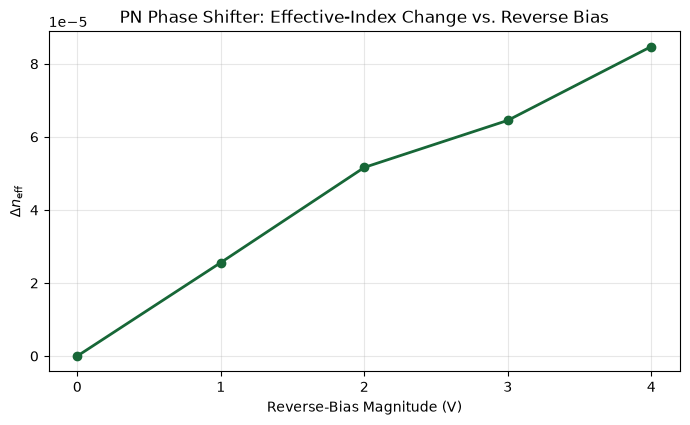

In [27]:
# Plot the simulated effective-index change versus reverse-bias voltage for the PN phase shifter.

reverse_bias = -voltages

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    reverse_bias,
    delta_neff_vs_voltage,
    marker="o",
    linewidth=2,
)

ax.set_xlabel("Reverse-Bias Magnitude (V)")
ax.set_ylabel(r"$\Delta n_{\mathrm{eff}}$")
ax.set_title("PN Phase Shifter: Effective-Index Change vs. Reverse Bias")

ax.grid(True, alpha=0.3)
ax.set_xticks(reverse_bias)

fig.tight_layout()

plt.savefig(
    "../Figures/PN_phase_shifter_delta_neff_vs_voltage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [28]:
# Calculate phase-shifter efficiency, pi-phase-shift length, and effective VpiL from the simulated Δn_eff(V).

phase_shift_per_mm = (
    (2 * np.pi / wavelength)
    * delta_neff_vs_voltage
    * 1000
)

Lpi_um = np.full_like(delta_neff_vs_voltage, np.nan, dtype=float)
VpiL_Vcm = np.full_like(delta_neff_vs_voltage, np.nan, dtype=float)

for i in range(1, len(voltages)):
    Lpi_um[i] = wavelength / (2 * abs(delta_neff_vs_voltage[i]))

    # Convert V·µm to V·cm using 1 µm = 1e-4 cm.
    VpiL_Vcm[i] = (
        abs(voltages[i])
        * Lpi_um[i]
        * 1e-4
    )

print("Phase-shifter efficiency:")
for V, dneff, phase_mm, Lpi, vpil in zip(
    voltages,
    delta_neff_vs_voltage,
    phase_shift_per_mm,
    Lpi_um,
    VpiL_Vcm,
):
    if V == 0:
        print(
            f"V = {V:>2.0f} V | "
            f"Δn_eff = {dneff:.3e} | reference state"
        )
    else:
        print(
            f"V = {V:>2.0f} V | "
            f"Δn_eff = {dneff:.3e} | "
            f"Δφ/L = {phase_mm:.3f} rad/mm | "
            f"Lπ = {Lpi:.1f} µm | "
            f"VπL = {vpil:.3f} V·cm"
        )

Phase-shifter efficiency:
V =  0 V | Δn_eff = 0.000e+00 | reference state
V = -1 V | Δn_eff = 2.559e-05 | Δφ/L = 0.104 rad/mm | Lπ = 30284.2 µm | VπL = 3.028 V·cm
V = -2 V | Δn_eff = 5.164e-05 | Δφ/L = 0.209 rad/mm | Lπ = 15009.0 µm | VπL = 3.002 V·cm
V = -3 V | Δn_eff = 6.452e-05 | Δφ/L = 0.262 rad/mm | Lπ = 12011.4 µm | VπL = 3.603 V·cm
V = -4 V | Δn_eff = 8.474e-05 | Δφ/L = 0.343 rad/mm | Lπ = 9146.1 µm | VπL = 3.658 V·cm


In [29]:
# Summarize the carrier-induced absorption change across the silicon phase shifter at each reverse-bias voltage.

delta_alpha_stats = []

for V in voltages:
    delta_alpha = plasma_maps[V]["delta_alpha"]

    # Only examine values inside the silicon waveguide.
    alpha_si = delta_alpha[silicon_mask]

    delta_alpha_stats.append([
        V,
        np.min(alpha_si),
        np.max(alpha_si),
    ])

print("Carrier-induced absorption change relative to 0 V:")
print("Voltage     Min Δα (cm^-1)     Max Δα (cm^-1)")

for V, alpha_min, alpha_max in delta_alpha_stats:
    print(
        f"{V:>4.0f} V       "
        f"{alpha_min:>12.3e}       "
        f"{alpha_max:>12.3e}"
    )

Carrier-induced absorption change relative to 0 V:
Voltage     Min Δα (cm^-1)     Max Δα (cm^-1)
   0 V          0.000e+00          0.000e+00
  -1 V         -8.500e-01          0.000e+00
  -2 V         -8.500e-01          0.000e+00
  -3 V         -8.500e-01          0.000e+00
  -4 V         -8.500e-01          0.000e+00


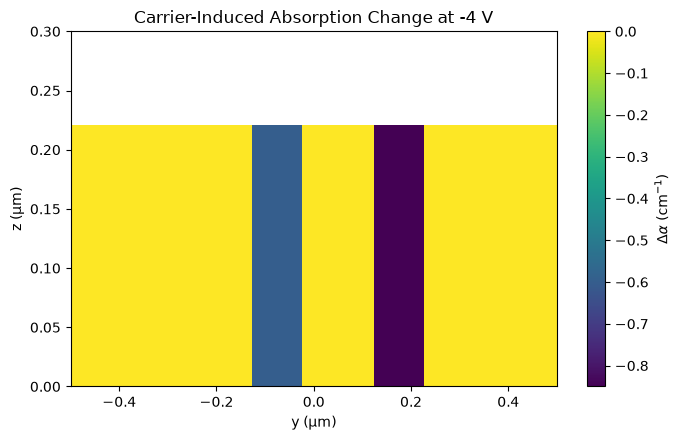

In [30]:
# Visualize the carrier-induced absorption change at -4 V relative to the 0 V state.

V_plot = -4
delta_alpha_plot = plasma_maps[V_plot]["delta_alpha"]

fig, ax = plt.subplots(figsize=(7, 4.5))

im = ax.pcolormesh(
    y,
    z,
    delta_alpha_plot,
    shading="auto",
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta \alpha$ (cm$^{-1}$)")

ax.set_xlabel("y (µm)")
ax.set_ylabel("z (µm)")
ax.set_title("Carrier-Induced Absorption Change at -4 V")

ax.set_xlim(-0.5, 0.5)
ax.set_ylim(0, 0.30)

fig.tight_layout()

plt.show()

In [31]:
# Convert the -4 V refractive-index and absorption changes into a complex refractive-index map.

V_loss_test = -4

# Real refractive-index distribution.
n_real_loss = n_si + plasma_maps[V_loss_test]["delta_n"]

# Convert wavelength from µm to cm because Δα is expressed in cm^-1.
wavelength_cm = wavelength * 1e-4

# Convert the absorption change Δα into a change in extinction coefficient κ.
delta_alpha_loss = plasma_maps[V_loss_test]["delta_alpha"]
delta_kappa_loss = (
    delta_alpha_loss * wavelength_cm / (4 * np.pi)
)

# Construct the differential complex refractive-index map.
n_complex_loss = n_real_loss + 1j * delta_kappa_loss

print(f"Voltage: {V_loss_test} V")
print(f"Real n range: {np.min(n_real_loss):.8f} to {np.max(n_real_loss):.8f}")
print(
    f"Δα range: {np.min(delta_alpha_loss):.3e} "
    f"to {np.max(delta_alpha_loss):.3e} cm^-1"
)
print(
    f"Δκ range: {np.min(delta_kappa_loss):.3e} "
    f"to {np.max(delta_kappa_loss):.3e}"
)

Voltage: -4 V
Real n range: 3.47000000 to 3.47033839
Δα range: -8.500e-01 to 0.000e+00 cm^-1
Δκ range: -1.048e-05 to 0.000e+00


In [32]:
# Calculate the absolute free-carrier absorption and extinction-coefficient maps at every bias voltage.

absolute_loss_maps = {}

for V in voltages:
    N = carrier_maps[V]["N"]
    P = carrier_maps[V]["P"]

    # Free-carrier absorption coefficient at 1550 nm in cm^-1.
    alpha_fca = (
        8.5e-18 * N
        + 6.0e-18 * P
    )

    # Convert absorption coefficient to extinction coefficient.
    kappa_fca = alpha_fca * wavelength_cm / (4 * np.pi)

    alpha_fca[~silicon_mask] = 0.0
    kappa_fca[~silicon_mask] = 0.0

    absolute_loss_maps[V] = {
        "alpha_fca": alpha_fca,
        "kappa_fca": kappa_fca,
    }

print("Absolute free-carrier absorption:")
print("Voltage     Max α_FCA (cm^-1)     Max κ")

for V in voltages:
    alpha_max = np.max(absolute_loss_maps[V]["alpha_fca"])
    kappa_max = np.max(absolute_loss_maps[V]["kappa_fca"])

    print(
        f"{V:>4.0f} V       "
        f"{alpha_max:>12.3e}       "
        f"{kappa_max:>12.3e}"
    )

Absolute free-carrier absorption:
Voltage     Max α_FCA (cm^-1)     Max κ
   0 V          8.500e-01          1.048e-05
  -1 V          8.500e-01          1.048e-05
  -2 V          8.500e-01          1.048e-05
  -3 V          8.500e-01          1.048e-05
  -4 V          8.500e-01          1.048e-05


In [33]:
# Build the lossy -4 V CustomMedium from spatially varying n and k using Tidy3D's supported lossy-material constructor.

V_loss_test = -4

n_real = n_si + plasma_maps[V_loss_test]["delta_n"]
kappa = absolute_loss_maps[V_loss_test]["kappa_fca"]

n_field_loss = td.SpatialDataArray(
    n_real.T[np.newaxis, :, :],
    coords={
        "x": [0.0],
        "y": y,
        "z": z,
    },
)

k_field_loss = td.SpatialDataArray(
    kappa.T[np.newaxis, :, :],
    coords={
        "x": [0.0],
        "y": y,
        "z": z,
    },
)

silicon_loss = td.CustomMedium.from_nk(
    n=n_field_loss,
    k=k_field_loss,
    freq=freq0,
    interp_method="linear",
)

print(f"Voltage: {V_loss_test} V")
print(
    f"Real(n): {np.min(n_real):.8f} to "
    f"{np.max(n_real):.8f}"
)
print(
    f"kappa:   {np.min(kappa):.3e} to "
    f"{np.max(kappa):.3e}"
)
print("Lossy CustomMedium created successfully.")

Voltage: -4 V
Real(n): 3.47000000 to 3.47033839
kappa:   0.000e+00 to 1.048e-05
Lossy CustomMedium created successfully.


In [34]:
# Remotely solve the lossy -4 V TE0 mode to obtain its effective index and free-carrier modal loss.

slab_loss = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, mapped_width, slab_height),
    ),
    medium=silicon_loss,
)

rib_loss = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + etch_depth / 2),
        size=(td.inf, rib_width, etch_depth),
    ),
    medium=silicon_loss,
)

sim_loss = td.Simulation(
    size=(1.0, domain_y, domain_z),
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=30,
        wavelength=wavelength,
    ),
    structures=[slab_loss, rib_loss],
    medium=silica,
    run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
)

solver_loss = ModeSolver(
    simulation=sim_loss,
    plane=mode_plane,
    mode_spec=td.ModeSpec(
        num_modes=1,
        target_neff=2.63,
    ),
    freqs=[freq0],
)

mode_data_loss = run_mode_solver(
    solver_loss,
    task_name="PN_phase_shifter_loss_m4V",
)

neff_loss_m4V = float(
    mode_data_loss.n_eff.isel(f=0, mode_index=0)
)

print(f"Lossy n_eff(-4 V) = {neff_loss_m4V:.8f}")
print()
print(mode_data_loss.to_dataframe())

18:12:29 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

18:12:30 Central Daylight Time Mode solver created with                         
                               task_id='fdve-545b1a87-7dd3-41af-9171-39303d1e2a7
                               c',                                              
                               solver_id='mo-ffcfd849-36d6-4d94-b9d5-8f460464bb4
                               5'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:12:32 Central Daylight Time Mode solver status: success

Lossy n_eff(-4 V) = 2.63161968

                         wavelength    n eff     k eff  loss (dB/cm)  \
f            mode_index                                                
1.934145e+14 0                 1.55  2.63162  0.000002      0.845788   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.989154        0.883552        0.809108   

                         mode area  
f            mode_index             
1.934145e+14 0             0.20623  


In [35]:
# Remotely solve the lossy TE0 mode at every bias voltage to obtain free-carrier modal loss versus voltage.

modal_loss_vs_voltage = []
lossy_neff_vs_voltage = []

for V in voltages:

    # Build the voltage-dependent real index and absolute FCA extinction maps.
    n_real_V = n_si + plasma_maps[V]["delta_n"]
    kappa_V = absolute_loss_maps[V]["kappa_fca"]

    n_field_V = td.SpatialDataArray(
        n_real_V.T[np.newaxis, :, :],
        coords={"x": [0.0], "y": y, "z": z},
    )

    k_field_V = td.SpatialDataArray(
        kappa_V.T[np.newaxis, :, :],
        coords={"x": [0.0], "y": y, "z": z},
    )

    silicon_loss_V = td.CustomMedium.from_nk(
        n=n_field_V,
        k=k_field_V,
        freq=freq0,
        interp_method="linear",
    )

    slab_loss_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height / 2),
            size=(td.inf, mapped_width, slab_height),
        ),
        medium=silicon_loss_V,
    )

    rib_loss_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height + etch_depth / 2),
            size=(td.inf, rib_width, etch_depth),
        ),
        medium=silicon_loss_V,
    )

    sim_loss_V = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=30,
            wavelength=wavelength,
        ),
        structures=[slab_loss_V, rib_loss_V],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
    )

    solver_loss_V = ModeSolver(
        simulation=sim_loss_V,
        plane=mode_plane,
        mode_spec=td.ModeSpec(
            num_modes=1,
            target_neff=2.63,
        ),
        freqs=[freq0],
    )

    mode_loss_V = run_mode_solver(
        solver_loss_V,
        task_name=f"PN_phase_shifter_loss_{abs(int(V))}V",
    )

    mode_df_V = mode_loss_V.to_dataframe()

    neff_V = float(
        mode_loss_V.n_eff.isel(f=0, mode_index=0)
    )

    loss_V = float(
        mode_df_V["loss (dB/cm)"].iloc[0]
    )

    lossy_neff_vs_voltage.append(neff_V)
    modal_loss_vs_voltage.append(loss_V)

    print(
        f"V = {V:>2.0f} V | "
        f"n_eff = {neff_V:.8f} | "
        f"loss = {loss_V:.6f} dB/cm"
    )

lossy_neff_vs_voltage = np.array(lossy_neff_vs_voltage)
modal_loss_vs_voltage = np.array(modal_loss_vs_voltage)

18:12:34 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-ff658e24-60d7-4cd6-b86f-5685f01b075
                               b',                                              
                               solver_id='mo-e8571ad2-3b36-45a9-a3d7-9106504d152
                               3'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:12:36 Central Daylight Time Mode solver status: success

V =  0 V | n_eff = 2.63153495 | loss = 2.000485 dB/cm


...

18:12:51 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-f01560ad-edf5-4a93-8015-e0b1d70224a
                               9',                                              
                               solver_id='mo-236bbebd-ff38-4a99-ace7-738aed3b086
                               c'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:12:54 Central Daylight Time Mode solver status: success

V = -4 V | n_eff = 2.63161968 | loss = 0.845788 dB/cm


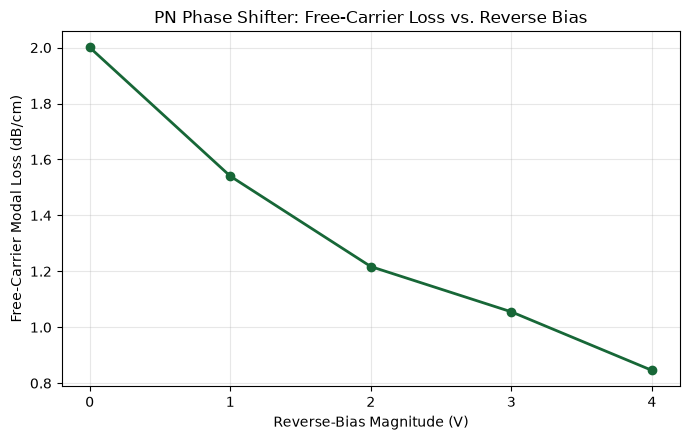

In [36]:
# Plot the simulated free-carrier modal loss versus reverse-bias voltage.

reverse_bias = -voltages

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    reverse_bias,
    modal_loss_vs_voltage,
    marker="o",
    linewidth=2,
)

ax.set_xlabel("Reverse-Bias Magnitude (V)")
ax.set_ylabel("Free-Carrier Modal Loss (dB/cm)")
ax.set_title("PN Phase Shifter: Free-Carrier Loss vs. Reverse Bias")

ax.set_xticks(reverse_bias)
ax.grid(True, alpha=0.3)

fig.tight_layout()

plt.savefig(
    "../Figures/PN_phase_shifter_FCA_loss_vs_voltage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [37]:
# Calculate the free-carrier absorption loss accumulated over the pi-phase-shift length at each bias voltage.

Lpi_cm = Lpi_um * 1e-4

FCA_loss_at_Lpi_dB = modal_loss_vs_voltage * Lpi_cm

print("Free-carrier loss for a π phase shift:")
print("Voltage     Lπ (mm)     Modal Loss (dB/cm)     FCA Loss over Lπ (dB)")

for i in range(1, len(voltages)):
    print(
        f"{voltages[i]:>4.0f} V       "
        f"{Lpi_um[i] / 1000:>7.3f}       "
        f"{modal_loss_vs_voltage[i]:>10.4f}             "
        f"{FCA_loss_at_Lpi_dB[i]:>8.3f}"
    )

Free-carrier loss for a π phase shift:
Voltage     Lπ (mm)     Modal Loss (dB/cm)     FCA Loss over Lπ (dB)
  -1 V        30.284           1.5403                4.665
  -2 V        15.009           1.2170                1.827
  -3 V        12.011           1.0551                1.267
  -4 V         9.146           0.8458                0.774


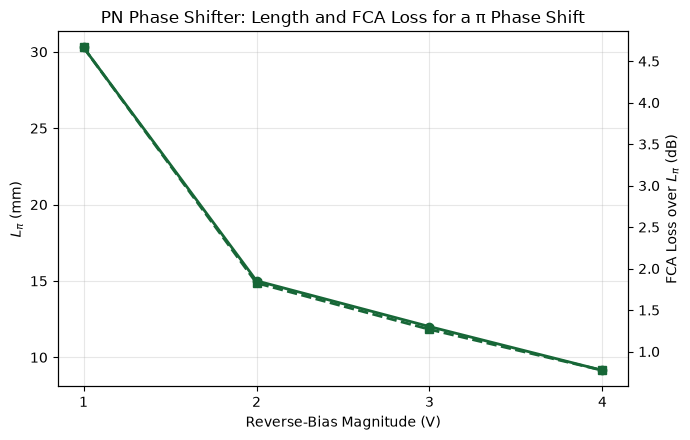

In [38]:
# Plot the pi-phase-shift length and corresponding free-carrier loss versus reverse-bias voltage.

reverse_bias_nonzero = -voltages[1:]

fig, ax1 = plt.subplots(figsize=(7, 4.5))

ax1.plot(
    reverse_bias_nonzero,
    Lpi_um[1:] / 1000,
    marker="o",
    linewidth=2,
)

ax1.set_xlabel("Reverse-Bias Magnitude (V)")
ax1.set_ylabel(r"$L_\pi$ (mm)")
ax1.set_xticks(reverse_bias_nonzero)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    reverse_bias_nonzero,
    FCA_loss_at_Lpi_dB[1:],
    marker="s",
    linestyle="--",
    linewidth=2,
)

ax2.set_ylabel(r"FCA Loss over $L_\pi$ (dB)")

ax1.set_title("PN Phase Shifter: Length and FCA Loss for a π Phase Shift")

fig.tight_layout()

plt.savefig(
    "../Figures/PN_phase_shifter_Lpi_FCA_tradeoff.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

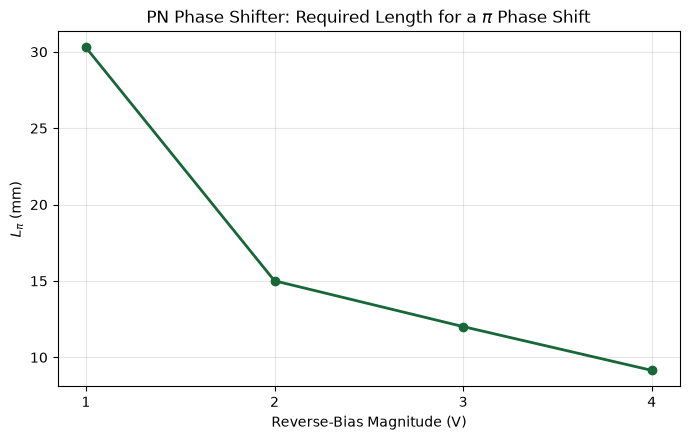

In [39]:
# Plot the required pi-phase-shifter length versus reverse-bias voltage as a standalone design figure.

valid = voltages != 0
reverse_bias_nonzero = -voltages[valid]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    reverse_bias_nonzero,
    Lpi_um[valid] / 1000,
    marker="o",
    linewidth=2,
)

ax.set_xlabel("Reverse-Bias Magnitude (V)")
ax.set_ylabel(r"$L_{\pi}$ (mm)")
ax.set_title(r"PN Phase Shifter: Required Length for a $\pi$ Phase Shift")

ax.set_xticks(reverse_bias_nonzero)
ax.grid(True, alpha=0.3)

fig.tight_layout()

plt.savefig(
    "../Figures/PN_phase_shifter_Lpi_vs_voltage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

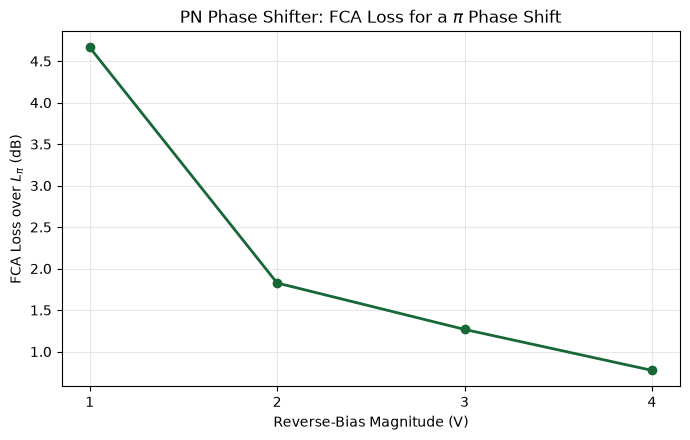

In [40]:
# Plot the free-carrier-absorption loss accumulated over the required pi-phase-shifter length.

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    reverse_bias_nonzero,
    FCA_loss_at_Lpi_dB[1:],
    marker="o",
    linewidth=2,
)

ax.set_xlabel("Reverse-Bias Magnitude (V)")
ax.set_ylabel(r"FCA Loss over $L_\pi$ (dB)")
ax.set_title(r"PN Phase Shifter: FCA Loss for a $\pi$ Phase Shift")

ax.set_xticks(reverse_bias_nonzero)
ax.grid(True, alpha=0.3)

fig.tight_layout()

plt.savefig(
    "../Figures/PN_phase_shifter_FCA_loss_vs_voltage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

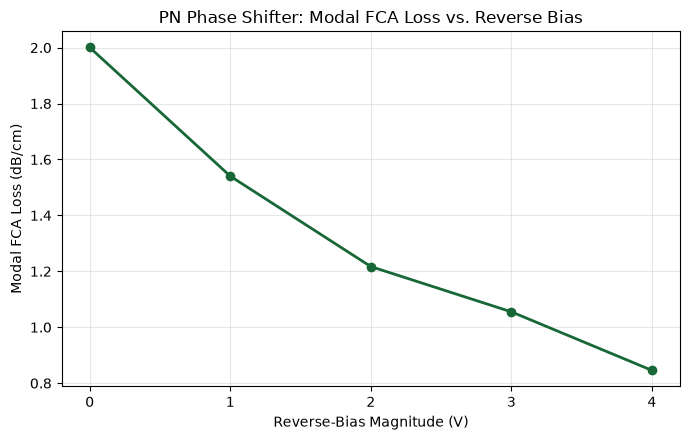

In [41]:
# Plot the voltage-dependent modal free-carrier absorption loss independently of the required phase-shifter length.

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    -voltages,
    modal_loss_vs_voltage,
    marker="o",
    linewidth=2,
)

ax.set_xlabel("Reverse-Bias Magnitude (V)")
ax.set_ylabel("Modal FCA Loss (dB/cm)")
ax.set_title("PN Phase Shifter: Modal FCA Loss vs. Reverse Bias")

ax.set_xticks(-voltages)
ax.grid(True, alpha=0.3)

fig.tight_layout()

plt.savefig(
    "../Figures/PN_phase_shifter_modal_FCA_vs_voltage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [42]:
# Calculate the PN-junction capacitance per unit phase-shifter length versus reverse-bias voltage.

W_cm = W_um * 1e-4
si_height_cm = si_height * 1e-4

Cj_per_cm = eps_si * si_height_cm / W_cm
Cj_per_mm_pF = Cj_per_cm * 1e11

print("Junction capacitance per unit length:")
print("Voltage     Wd (µm)     Cj/L (pF/mm)")

for V, W, C_per_mm in zip(
    voltages,
    W_um,
    Cj_per_mm_pF,
):
    print(
        f"{V:>4.0f} V       "
        f"{W:>7.3f}       "
        f"{C_per_mm:>8.4f}"
    )

Junction capacitance per unit length:
Voltage     Wd (µm)     Cj/L (pF/mm)
   0 V         0.147         0.1552
  -1 V         0.218         0.1046
  -2 V         0.271         0.0842
  -3 V         0.315         0.0724
  -4 V         0.354         0.0645


## Electrical Contact and Doping Design

The active phase shifter uses a lateral carrier-depletion PN junction embedded in the silicon rib waveguide. Moderate P- and N-type doping forms the active junction and overlaps the optical mode, while heavily doped P++ and N++ access regions provide lower-resistance electrical paths to the metal contacts.

### Initial Active Geometry

- Wavelength: 1550 nm
- Rib width: 500 nm
- Total silicon height: 220 nm
- Slab height: 90 nm
- Junction offset: +50 nm from waveguide center
- Active P doping: 1e17 cm⁻³
- Active N doping: 1e17 cm⁻³
- Reverse-bias range: 0 to -4 V

### Electrical Design Goals

1. Maintain strong carrier-induced optical phase modulation.
2. Reduce electrical resistance using heavily doped contact regions.
3. Keep heavily doped regions sufficiently far from the optical mode to limit free-carrier absorption.
4. Determine junction capacitance and resistance for estimating RC bandwidth.
5. Evaluate the tradeoff between modulation efficiency, optical loss, and electrical bandwidth.

### Next Step

Extend the cross-section with P++/N++ access regions and electrical contacts, then evaluate whether Tidy3D Charge can provide a more realistic voltage-dependent electrical model.

In [43]:
# Verify that the installed Tidy3D version contains the Charge-solver components needed for the PN-junction model.

charge_components = [
    "HeatChargeSimulation",
    "SemiconductorMedium",
    "ConstantDoping",
    "VoltageBC",
    "DCVoltageSource",
    "SteadyFreeCarrierMonitor",
    "UniformUnstructuredGrid",
    "IsothermalSteadyChargeDCAnalysis",
]

print(f"Tidy3D version: {td.__version__}\n")

for component in charge_components:
    print(f"{component:<35} {'✓' if hasattr(td, component) else '✗'}")

Tidy3D version: 2.12.0

HeatChargeSimulation                ✓
SemiconductorMedium                 ✓
ConstantDoping                      ✓
VoltageBC                           ✓
DCVoltageSource                     ✓
SteadyFreeCarrierMonitor            ✓
UniformUnstructuredGrid             ✓
IsothermalSteadyChargeDCAnalysis    ✓


In [44]:
# Inspect the available semiconductor material definitions before constructing the Charge model.

import inspect

print("SemiconductorMedium signature:")
print(inspect.signature(td.SemiconductorMedium))

print("\nConstantDoping signature:")
print(inspect.signature(td.ConstantDoping))

print("\nAvailable semiconductor-related Tidy3D names:")
for name in dir(td):
    if any(term in name.lower() for term in ["silicon", "mobility", "recombination"]):
        print(name)

SemiconductorMedium signature:
(*, attrs: dict = <factory>, name: str | None = None, frequency_range: tuple[float, float] | None = None, allow_gain: bool = False, nonlinear_spec: Annotated[tidy3d.components.nonlinear.NonlinearSpec | tidy3d.components.nonlinear.NonlinearSusceptibility, FieldInfo(annotation=NoneType, required=True, discriminator='type')] | None = None, modulation_spec: tidy3d.components.time_modulation.ModulationSpec | None = None, viz_spec: tidy3d.components.viz.visualization_spec.VisualizationSpec | None = None, heat_spec: tidy3d.components.material.tcad.heat.FluidSpec | tidy3d.components.material.tcad.heat.SolidSpec | tidy3d.components.material.tcad.heat.SolidMedium | tidy3d.components.material.tcad.heat.FluidMedium | None = None, type: Literal['SemiconductorMedium'] = 'SemiconductorMedium', permittivity: Annotated[float, Ge(ge=1.0)] = 1.0, N_c: tidy3d.components.tcad.effective_DOS.ConstantEffectiveDOS | tidy3d.components.tcad.effective_DOS.IsotropicEffectiveDOS | tid

In [45]:
# Define the initial P/N active doping and P++/N++ access-region doping for the Charge model.

si_charge_base = (
    td.material_library["cSi"]
    .variants["Si_MultiPhysics"]
    .medium.charge
)

NA_active = 1e17
ND_active = 1e17

NA_heavy = 1e19
ND_heavy = 1e19

access_offset = 0.60      # µm from waveguide center
access_width = 0.40       # µm
doping_span_z = si_height

p_active = td.ConstantDoping(
    center=(0, -0.25, si_height / 2),
    size=(td.inf, 0.60, doping_span_z),
    concentration=NA_active,
)

n_active = td.ConstantDoping(
    center=(0, 0.35, si_height / 2),
    size=(td.inf, 0.60, doping_span_z),
    concentration=ND_active,
)

p_heavy = td.ConstantDoping(
    center=(0, -access_offset, slab_height / 2),
    size=(td.inf, access_width, slab_height),
    concentration=NA_heavy,
)

n_heavy = td.ConstantDoping(
    center=(0, access_offset, slab_height / 2),
    size=(td.inf, access_width, slab_height),
    concentration=ND_heavy,
)

si_charge = si_charge_base.updated_copy(
    N_a=[p_active, p_heavy],
    N_d=[n_active, n_heavy],
    name="Si_PN_phase_shifter",
)

print("Charge silicon model created successfully.")
print(f"Active P doping:  {NA_active:.1e} cm^-3")
print(f"Active N doping:  {ND_active:.1e} cm^-3")
print(f"Heavy P++ doping: {NA_heavy:.1e} cm^-3")
print(f"Heavy N++ doping: {ND_heavy:.1e} cm^-3")

Charge silicon model created successfully.
Active P doping:  1.0e+17 cm^-3
Active N doping:  1.0e+17 cm^-3
Heavy P++ doping: 1.0e+19 cm^-3
Heavy N++ doping: 1.0e+19 cm^-3


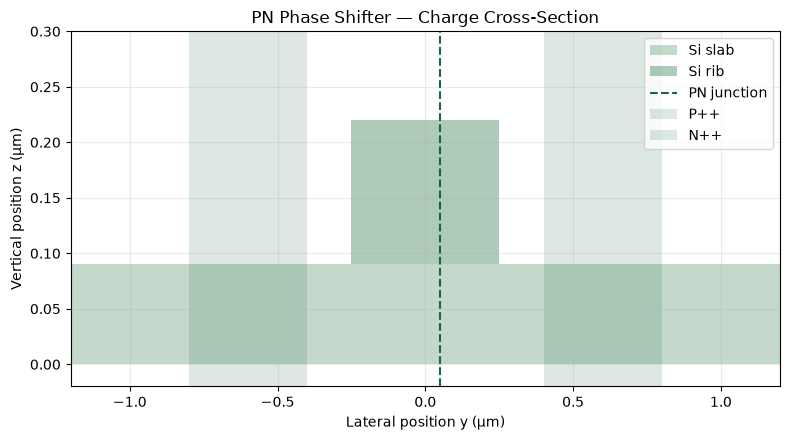

Charge structures created:
Structure(
    geometry=Box(center=(0.0, 0.0, 0.155), size=(inf, 0.5, 0.13)),
    name='Si_rib',
    background_permittivity=None,
    background_medium=None,
    priority=None,
    medium=SemiconductorMedium(
        name='Si_PN_phase_shifter',
        frequency_range=None,
        allow_gain=False,
        nonlinear_spec=None,
        modulation_spec=None,
        viz_spec=None,
        heat_spec=None,
        permittivity=11.7,
        N_c=ConstantEffectiveDOS(N=2.86e+19),
        N_v=ConstantEffectiveDOS(N=3.1e+19),
        E_g=ConstantEnergyBandGap(eg=1.11),
        electron_affinity=None,
        richardson_electron=None,
        richardson_hole=None,
        mobility_n=CaugheyThomasMobility(
            mu_min=52.2,
            mu=1471.0,
            exp_2=-2.33,
            exp_N=0.68,
            ref_N=9.68e+16,
            exp_1=-0.57,
            exp_3=2.4,
            exp_4=-0.146
        ),
        mobility_p=CaugheyThomasMobility(
            mu

In [46]:
# Build and visualize the semiconductor rib-waveguide cross-section for the Charge simulation.

charge_rib = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height + (si_height - slab_height) / 2),
        size=(td.inf, rib_width, si_height - slab_height),
    ),
    medium=si_charge,
    name="Si_rib",
)

charge_slab = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_height / 2),
        size=(td.inf, 3.0, slab_height),
    ),
    medium=si_charge,
    name="Si_slab",
)

fig, ax = plt.subplots(figsize=(8, 4.5))

# Draw the silicon slab.
ax.add_patch(
    plt.Rectangle(
        (-1.5, 0),
        3.0,
        slab_height,
        alpha=0.25,
        label="Si slab",
    )
)

# Draw the silicon rib.
ax.add_patch(
    plt.Rectangle(
        (-rib_width / 2, slab_height),
        rib_width,
        si_height - slab_height,
        alpha=0.35,
        label="Si rib",
    )
)

# Mark the PN junction position.
ax.axvline(
    junction_offset,
    linestyle="--",
    linewidth=1.5,
    label="PN junction",
)

# Mark the approximate heavy-doping regions.
ax.axvspan(
    -access_offset - access_width / 2,
    -access_offset + access_width / 2,
    alpha=0.15,
    label="P++",
)

ax.axvspan(
    access_offset - access_width / 2,
    access_offset + access_width / 2,
    alpha=0.15,
    label="N++",
)

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-0.02, 0.30)

ax.set_xlabel("Lateral position y (µm)")
ax.set_ylabel("Vertical position z (µm)")
ax.set_title("PN Phase Shifter — Charge Cross-Section")

ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print("Charge structures created:")
print(charge_rib)
print(charge_slab)

In [47]:
# Define the P-side and N-side ohmic electrical contact regions for the Charge simulation.

contact_width = 0.20      # µm
contact_height = 0.05     # µm
contact_offset = 0.60     # µm from waveguide center

p_contact = td.Structure(
    geometry=td.Box(
        center=(0, -contact_offset, slab_height + contact_height / 2),
        size=(td.inf, contact_width, contact_height),
    ),
    medium=td.ChargeConductorMedium(conductivity=1e5),
    name="P_contact",
)

n_contact = td.Structure(
    geometry=td.Box(
        center=(0, contact_offset, slab_height + contact_height / 2),
        size=(td.inf, contact_width, contact_height),
    ),
    medium=td.ChargeConductorMedium(conductivity=1e5),
    name="N_contact",
)

print("Electrical contacts created successfully.")
print(f"P contact center: y = {-contact_offset:.2f} µm")
print(f"N contact center: y = {contact_offset:.2f} µm")
print(f"Contact width:     {contact_width:.2f} µm")
print(f"Contact height:    {contact_height:.2f} µm")

Electrical contacts created successfully.
P contact center: y = -0.60 µm
N contact center: y = 0.60 µm
Contact width:     0.20 µm
Contact height:    0.05 µm


In [48]:
# Inspect the actual fields of the Charge voltage-source and boundary-condition objects.

for cls in [td.VoltageBC, td.DCVoltageSource, td.StructureBoundary]:
    print(f"\n{cls.__name__}")
    print("-" * 50)

    for name, field in cls.model_fields.items():
        print(f"{name:<20} default = {field.default}")


VoltageBC
--------------------------------------------------
attrs                default = PydanticUndefined
type                 default = VoltageBC
source               default = PydanticUndefined
model                default = ohmic

DCVoltageSource
--------------------------------------------------
attrs                default = PydanticUndefined
name                 default = None
voltage              default = PydanticUndefined
units                default = V
type                 default = DCVoltageSource

StructureBoundary
--------------------------------------------------
attrs                default = PydanticUndefined
type                 default = StructureBoundary
structure            default = PydanticUndefined


In [49]:
# Define ohmic contact boundary conditions for a 0 to -4 V reverse-bias sweep.

charge_voltages = [0, -1, -2, -3, -4]

p_voltage_bc = td.VoltageBC(
    source=td.DCVoltageSource(
        voltage=charge_voltages,
    ),
)

n_voltage_bc = td.VoltageBC(
    source=td.DCVoltageSource(
        voltage=0,
    ),
)

p_boundary = td.StructureBoundary(
    structure="P_contact",
)

n_boundary = td.StructureBoundary(
    structure="N_contact",
)

print("Electrical boundary conditions defined.")
print(f"P-side sweep: {charge_voltages} V")
print("N-side voltage: 0 V")
print(f"Contact model: {p_voltage_bc.model}")

Electrical boundary conditions defined.
P-side sweep: [0, -1, -2, -3, -4] V
N-side voltage: 0 V
Contact model: ohmic


In [50]:
# Inspect the available fields for the steady-state free-carrier monitor before adding it to the Charge simulation.

print("SteadyFreeCarrierMonitor")
print("-" * 50)

for name, field in td.SteadyFreeCarrierMonitor.model_fields.items():
    print(f"{name:<25} default = {field.default}")

SteadyFreeCarrierMonitor
--------------------------------------------------
attrs                     default = PydanticUndefined
type                      default = SteadyFreeCarrierMonitor
center                    default = (0.0, 0.0, 0.0)
size                      default = PydanticUndefined
name                      default = PydanticUndefined
unstructured              default = True


In [51]:
# Define a free-carrier monitor covering the complete PN phase-shifter cross-section.

carrier_monitor = td.SteadyFreeCarrierMonitor(
    center=(0, 0, si_height / 2),
    size=(0, 3.0, si_height),
    name="carrier_distribution",
)

print("Free-carrier monitor created successfully.")
print(f"Monitor lateral span: 3.00 µm")
print(f"Monitor vertical span: {si_height:.2f} µm")
print(f"Monitor name: {carrier_monitor.name}")

Free-carrier monitor created successfully.
Monitor lateral span: 3.00 µm
Monitor vertical span: 0.22 µm
Monitor name: carrier_distribution


In [52]:
# Define the numerical mesh and steady-state DC analysis settings for the Charge simulation.

charge_grid = td.UniformUnstructuredGrid(
    dl=0.01,
)

charge_analysis = td.IsothermalSteadyChargeDCAnalysis(
    temperature=300,
)

print("Charge numerical settings created successfully.")
print("Mesh spacing: 10 nm")
print("Temperature: 300 K")

18:12:57 Central Daylight Time WARNING: Field(s) ['min_edges_per_circumference',
                               'min_edges_per_side'] on                         
                               'UniformUnstructuredGrid' are using the current  
                               defaults; these defaults will change to 0 in the 
                               next release, which disables curvature- and      
                               side-length-based local mesh refinement. Set them
                               explicitly to preserve the current behavior.     

Charge numerical settings created successfully.
Mesh spacing: 10 nm
Temperature: 300 K


In [53]:
# Inspect the HeatChargeSimulation fields before assembling the complete PN-junction Charge model.

print("HeatChargeSimulation")
print("-" * 60)

for name, field in td.HeatChargeSimulation.model_fields.items():
    print(f"{name:<30} default = {field.default}")

HeatChargeSimulation
------------------------------------------------------------
attrs                          default = PydanticUndefined
type                           default = HeatChargeSimulation
center                         default = (0.0, 0.0, 0.0)
size                           default = PydanticUndefined
medium                         default = PydanticUndefined
structures                     default = ()
symmetry                       default = (0, 0, 0)
sources                        default = ()
boundary_spec                  default = ()
monitors                       default = ()
grid_spec                      default = PydanticUndefined
version                        default = 2.12.0
plot_length_units              default = μm
structure_priority_mode        default = equal
analysis_spec                  default = None
use_accelerated_solver         default = True


In [54]:
# Find the available Charge boundary-condition specification classes before assembling the simulation.

for name in dir(td):
    if "Boundary" in name and ("Condition" in name or "Spec" in name):
        print(name)

BoundarySpec
HeatBoundarySpec
HeatChargeBoundarySpec


In [55]:
# Inspect the HeatChargeBoundarySpec fields needed to connect each contact boundary to its voltage condition.

print("HeatChargeBoundarySpec")
print("-" * 50)

for name, field in td.HeatChargeBoundarySpec.model_fields.items():
    print(f"{name:<20} default = {field.default}")

HeatChargeBoundarySpec
--------------------------------------------------
attrs                default = PydanticUndefined
placement            default = PydanticUndefined
condition            default = PydanticUndefined
type                 default = HeatChargeBoundarySpec


In [56]:
# Assemble the contact boundary specifications and complete 2D PN-junction Charge simulation.

p_bc_spec = td.HeatChargeBoundarySpec(
    placement=p_boundary,
    condition=p_voltage_bc,
)

n_bc_spec = td.HeatChargeBoundarySpec(
    placement=n_boundary,
    condition=n_voltage_bc,
)

charge_sim = td.HeatChargeSimulation(
    center=(0, 0, si_height / 2),
    size=(0, 3.0, si_height),

    medium=td.Medium(permittivity=3.9),

    structures=[
        charge_slab,
        charge_rib,
        p_contact,
        n_contact,
    ],

    boundary_spec=[
        p_bc_spec,
        n_bc_spec,
    ],

    monitors=[
        carrier_monitor,
    ],

    grid_spec=charge_grid,
    analysis_spec=charge_analysis,
)

print("Complete Charge simulation created successfully.")
print(f"Simulation size: {charge_sim.size}")
print(f"Structures:      {len(charge_sim.structures)}")
print(f"Boundary specs:  {len(charge_sim.boundary_spec)}")
print(f"Monitors:        {len(charge_sim.monitors)}")

18:12:58 Central Daylight Time WARNING: Field(s) ['min_edges_per_circumference',
                               'min_edges_per_side'] on                         
                               'UniformUnstructuredGrid' are using the current  
                               defaults; these defaults will change to 0 in the 
                               next release, which disables curvature- and      
                               side-length-based local mesh refinement. Set them
                               explicitly to preserve the current behavior.     

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 3 WARNING messages.          

Complete Charge simulation created successfully.
Simulation size: (0.0, 3.0, 0.22)
Structures:      4
Boundary specs:  2
Monitors:        1


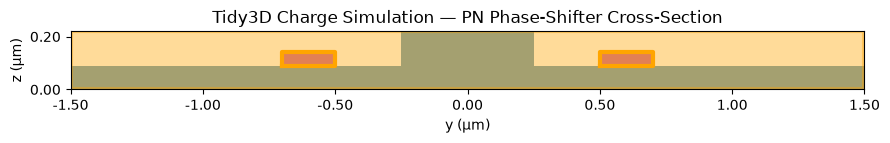

In [57]:
# Visualize the actual Tidy3D Charge simulation geometry and electrical boundary conditions before the remote solve.

fig, ax = plt.subplots(figsize=(9, 5))

charge_sim.plot(
    x=0,
    ax=ax,
)

ax.set_title("Tidy3D Charge Simulation — PN Phase-Shifter Cross-Section")
ax.set_xlabel("y (µm)")
ax.set_ylabel("z (µm)")

plt.tight_layout()
plt.show()

In [58]:
# Inspect the capacitance-monitor fields before adding TCAD capacitance extraction to the Charge simulation.

print("SteadyCapacitanceMonitor")
print("-" * 50)

for name, field in td.SteadyCapacitanceMonitor.model_fields.items():
    print(f"{name:<25} default = {field.default}")

SteadyCapacitanceMonitor
--------------------------------------------------
attrs                     default = PydanticUndefined
type                      default = SteadyCapacitanceMonitor
center                    default = (0.0, 0.0, 0.0)
size                      default = PydanticUndefined
name                      default = PydanticUndefined
unstructured              default = True


In [59]:
# Add a capacitance monitor to extract junction capacitance from the TCAD voltage sweep.

capacitance_monitor = td.SteadyCapacitanceMonitor(
    center=(0, 0, si_height / 2),
    size=(0, 3.0, si_height),
    name="junction_capacitance",
)

charge_sim = charge_sim.updated_copy(
    monitors=[
        carrier_monitor,
        capacitance_monitor,
    ]
)

print("Capacitance monitor added successfully.")
print(f"Monitors: {[monitor.name for monitor in charge_sim.monitors]}")

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 3 WARNING messages.          

Capacitance monitor added successfully.
Monitors: ['carrier_distribution', 'junction_capacitance']


In [60]:
# Compare every Charge structure's actual bounds against the simulation domain to locate the edge-touching geometry.

sim_min, sim_max = charge_sim.bounds
axes = ["x", "y", "z"]
tol = 1e-12

print("Simulation domain bounds (um):")
for i, ax in enumerate(axes):
    print(f"   {ax}: [{sim_min[i]:+.4f}, {sim_max[i]:+.4f}]")
print()

for idx, structure in enumerate(charge_sim.structures):
    s_min, s_max = structure.geometry.bounds
    label = structure.name if structure.name is not None else "(unnamed)"
    print(f"structures[{idx}]   name = {label}")
    for i, ax in enumerate(axes):
        lo, hi = s_min[i], s_max[i]
        flags = []
        if not (np.isfinite(lo) and np.isfinite(hi)):
            flags.append("infinite extent")
        if np.isfinite(lo) and abs(lo - sim_min[i]) <= tol:
            flags.append(f"{ax}_min touches domain edge")
        if np.isfinite(hi) and abs(hi - sim_max[i]) <= tol:
            flags.append(f"{ax}_max touches domain edge")
        note = "   <-- " + "; ".join(flags) if flags else ""
        print(f"   {ax}: [{lo:+.4f}, {hi:+.4f}]{note}")
    print()

Simulation domain bounds (um):
   x: [+0.0000, +0.0000]
   y: [-1.5000, +1.5000]
   z: [+0.0000, +0.2200]

structures[0]   name = Si_slab
   x: [-inf, +inf]   <-- infinite extent
   y: [-1.5000, +1.5000]   <-- y_min touches domain edge; y_max touches domain edge
   z: [+0.0000, +0.0900]   <-- z_min touches domain edge

structures[1]   name = Si_rib
   x: [-inf, +inf]   <-- infinite extent
   y: [-0.2500, +0.2500]
   z: [+0.0900, +0.2200]   <-- z_max touches domain edge

structures[2]   name = P_contact
   x: [-inf, +inf]   <-- infinite extent
   y: [-0.7000, -0.5000]
   z: [+0.0900, +0.1400]

structures[3]   name = N_contact
   x: [-inf, +inf]   <-- infinite extent
   y: [+0.5000, +0.7000]
   z: [+0.0900, +0.1400]



In [61]:
# Determine how Tidy3D combines overlapping doping boxes by reading the SemiconductorMedium field documentation.

import inspect

def field_description(model, field_name):
    field = type(model).model_fields[field_name]
    desc = getattr(field, "description", None)
    if desc is None:
        info = getattr(field, "field_info", None)
        desc = getattr(info, "description", None)
    return desc

for field_name in ["N_a", "N_d"]:
    print(f"--- SemiconductorMedium.{field_name} ---")
    print(f"description: {field_description(si_charge, field_name)}")
    print()

print("--- ConstantDoping docstring ---")
print(inspect.getdoc(td.ConstantDoping))
print()

print("--- Configured acceptor boxes ---")
for box in si_charge.N_a:
    print(f"   center={box.center}  size={box.size}  concentration={box.concentration:.3e}")
print("--- Configured donor boxes ---")
for box in si_charge.N_d:
    print(f"   center={box.center}  size={box.size}  concentration={box.concentration:.3e}")

--- SemiconductorMedium.N_a ---
description: Concentration of acceptor impurities, which create mobile holes, resulting in p-type material. Can be specified as a single float for uniform doping, a :class:`SpatialDataArray` for a custom profile, or a tuple/list of geometric shapes to define specific doped regions.

--- SemiconductorMedium.N_d ---
description: Concentration of donor impurities, which create mobile electrons, resulting in n-type material. Can be specified as a single float for uniform doping, a :class:`SpatialDataArray` for a custom profile, or a tuple/list of geometric shapes to define specific doped regions.

--- ConstantDoping docstring ---
Sets constant doping :math:`N` in the specified box with a :py:attr:`~.Box.size` and :py:attr:`concentration`. For translationally invariant behavior in one dimension, the box must have infinite size in the
homogenous (invariant) direction.

    Parameters
    ----------
    center : tuple[Union[float, autograd.tracer.Box], Union[fl

In [62]:
# Find the Tidy3D API that evaluates a doping distribution so overlapping boxes can be tested empirically.

# Two deliberately overlapping acceptor boxes:
#   low  = 1e17 over y in [-0.5, +0.5]
#   high = 1e19 over y in [ 0.0, +1.0]   -> overlap region is y in [0.0, +0.5]
test_box_low = td.ConstantDoping(
    center=(0, 0.0, si_height / 2), size=(td.inf, 1.0, si_height), concentration=1e17
)
test_box_high = td.ConstantDoping(
    center=(0, 0.5, si_height / 2), size=(td.inf, 1.0, si_height), concentration=1e19
)

test_medium = si_charge.updated_copy(N_a=[test_box_low, test_box_high])

def members_matching(obj, keywords):
    return [
        name for name in dir(obj)
        if not name.startswith("__")
        and any(k in name.lower() for k in keywords)
    ]

print("ConstantDoping members:")
print(members_matching(test_box_low, ["doping", "contrib", "eval", "value", "sample", "field"]))
print()
print("SemiconductorMedium members:")
print(members_matching(test_medium, ["doping", "contrib", "eval", "acceptor", "donor", "n_a", "n_d"]))
print()
print("Test medium acceptor boxes:")
for box in test_medium.N_a:
    print(f"   center={box.center}  size={box.size}  concentration={box.concentration:.3e}")

ConstantDoping members:
['_copy_and_set_values', '_evaluate_inf', '_get_cached_value_by_key', '_get_contrib', '_get_type_value', '_get_value', '_insert_traced_fields', '_normalize_empty_optional_discriminated_fields', '_preprocess_update_values', '_serialized_traced_field_keys', '_strip_traced_fields', 'car_2_sph_field', 'evaluate_inf_shape', 'model_computed_fields', 'model_fields', 'model_fields_set', 'sph_2_car_field']

SemiconductorMedium members:
['N_a', 'N_d', '_run_after_validators', 'electron_affinity']

Test medium acceptor boxes:
   center=(0.0, 0.0, 0.11)  size=(inf, 1.0, 0.22)  concentration=1.000e+17
   center=(0.0, 0.5, 0.11)  size=(inf, 1.0, 0.22)  concentration=1.000e+19


In [63]:
# Inspect and exercise ConstantDoping._get_contrib to determine how overlapping doping boxes combine.

import inspect

print("signature:", inspect.signature(test_box_low._get_contrib))
print()
print("docstring:")
print(inspect.getdoc(test_box_low._get_contrib))
print()

# Sample points across y at fixed x and z, chosen to straddle the overlap:
#   y < 0.0        -> low box only
#   0.0 < y < 0.5  -> BOTH boxes (the overlap)
#   y > 0.5        -> high box only
y_test = np.array([-0.40, -0.10, 0.10, 0.25, 0.40, 0.70, 0.90])
coords = {"x": np.array([0.0]), "y": y_test, "z": np.array([si_height / 2])}

try:
    contrib_low = np.ravel(test_box_low._get_contrib(coords))
    contrib_high = np.ravel(test_box_high._get_contrib(coords))
    print(f"{'y (um)':>10} {'low box':>14} {'high box':>14} {'sum':>14}")
    for y_val, c_low, c_high in zip(y_test, contrib_low, contrib_high):
        print(f"{y_val:>10.2f} {c_low:>14.3e} {c_high:>14.3e} {c_low + c_high:>14.3e}")
except Exception as exc:
    print(f"call with dict coords failed: {type(exc).__name__}: {exc}")

signature: (coords: 'dict', meshgrid: 'bool' = True) -> 'NDArray'

docstring:
Returns the contribution to the doping a the locations specified in coords

    y (um)        low box       high box            sum
     -0.40      1.000e+17      0.000e+00      1.000e+17
     -0.10      1.000e+17      0.000e+00      1.000e+17
      0.10      1.000e+17      1.000e+19      1.010e+19
      0.25      1.000e+17      1.000e+19      1.010e+19
      0.40      1.000e+17      1.000e+19      1.010e+19
      0.70      0.000e+00      1.000e+19      1.000e+19
      0.90      0.000e+00      1.000e+19      1.000e+19


In [64]:
# Truncate the Charge slab to the doped region and widen the domain so no silicon touches a lateral boundary.

charge_domain_y = 1.8   # um, Charge domain lateral extent (+/- 0.9)
slab_span_y = 1.6       # um, silicon slab lateral extent (+/- 0.8), matching the doped access regions

charge_slab = charge_slab.updated_copy(
    geometry=td.Box(center=(0, 0, slab_height / 2), size=(td.inf, slab_span_y, slab_height))
)

carrier_monitor = carrier_monitor.updated_copy(size=(0, charge_domain_y, si_height))
capacitance_monitor = capacitance_monitor.updated_copy(size=(0, charge_domain_y, si_height))

charge_sim = charge_sim.updated_copy(
    size=(0, charge_domain_y, si_height),
    structures=[charge_slab, charge_rib, p_contact, n_contact],
    monitors=[carrier_monitor, capacitance_monitor],
)

print(f"Domain size (x, y, z): {charge_sim.size}")
print(f"Slab y-span: {charge_slab.geometry.bounds[0][1]:+.4f} to {charge_slab.geometry.bounds[1][1]:+.4f} um")
print(f"Structures: {[s.name for s in charge_sim.structures]}")
print(f"Monitors:   {[m.name for m in charge_sim.monitors]}")

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

Domain size (x, y, z): (0.0, 1.8, 0.22)
Slab y-span: -0.8000 to +0.8000 um
Structures: ['Si_slab', 'Si_rib', 'P_contact', 'N_contact']
Monitors:   ['carrier_distribution', 'junction_capacitance']


In [65]:
# Pin the unstructured-grid refinement settings to their current values so the mesh is reproducible across Tidy3D releases.

print("Current grid_spec fields:")
for name in type(charge_grid).model_fields:
    print(f"   {name:<34} = {getattr(charge_grid, name)}")
print()

charge_grid = td.UniformUnstructuredGrid(
    dl=charge_grid.dl,
    min_edges_per_circumference=charge_grid.min_edges_per_circumference,
    min_edges_per_side=charge_grid.min_edges_per_side,
)

charge_sim = charge_sim.updated_copy(grid_spec=charge_grid)

print("Pinned grid_spec fields:")
for name in type(charge_grid).model_fields:
    print(f"   {name:<34} = {getattr(charge_grid, name)}")
print()
print(f"Domain size: {charge_sim.size}")
print(f"Monitors:    {[m.name for m in charge_sim.monitors]}")

Current grid_spec fields:
   attrs                              = {}
   relative_min_dl                    = 0.001
   geometry_tolerance                 = 1e-06
   remove_fragments                   = False
   type                               = UniformUnstructuredGrid
   dl                                 = 0.01
   min_edges_per_circumference        = 15.0
   min_edges_per_side                 = 2.0
   non_refined_structures             = ()



                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

Pinned grid_spec fields:
   attrs                              = {}
   relative_min_dl                    = 0.001
   geometry_tolerance                 = 1e-06
   remove_fragments                   = False
   type                               = UniformUnstructuredGrid
   dl                                 = 0.01
   min_edges_per_circumference        = 15.0
   min_edges_per_side                 = 2.0
   non_refined_structures             = ()

Domain size: (0.0, 1.8, 0.22)
Monitors:    ['carrier_distribution', 'junction_capacitance']


In [66]:
# Validate the Charge simulation locally and identify the available Tidy3D web API before submitting.

import tidy3d.web as web

try:
    charge_sim.validate_pre_upload()
    print("validate_pre_upload(): PASSED")
except AttributeError:
    print("validate_pre_upload(): not available on this object")
except Exception as exc:
    print(f"validate_pre_upload(): RAISED {type(exc).__name__}: {exc}")

print()
candidates = ["run", "Job", "Batch", "upload", "estimate_cost", "start", "monitor", "load", "download"]
print("web entry points present:", [n for n in candidates if hasattr(web, n)])

print()
print(f"Bias sweep:  {charge_voltages}")
print(f"Monitors:    {[m.name for m in charge_sim.monitors]}")
print(f"Domain size: {charge_sim.size}")
print(f"Mesh dl:     {charge_sim.grid_spec.dl} um")

validate_pre_upload(): PASSED

web entry points present: ['run', 'Job', 'Batch', 'upload', 'estimate_cost', 'start', 'monitor', 'load', 'download']

Bias sweep:  [0, -1, -2, -3, -4]
Monitors:    ['carrier_distribution', 'junction_capacitance']
Domain size: (0.0, 1.8, 0.22)
Mesh dl:     0.01 um


In [67]:
# Create the remote Charge job for the multi-step DC bias sweep.

charge_task_name = "PN_phase_shifter_charge_sweep_v1"

charge_job = web.Job(
    simulation=charge_sim,
    task_name=charge_task_name,
    folder_name="MZI_Modulator",
    verbose=True,
)

print(f"Task name: {charge_task_name}")
print(f"Multi-step job: {charge_job.is_multi_step}")

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

Task name: PN_phase_shifter_charge_sweep_v1
Multi-step job: True


In [68]:
# Run the multi-step Charge DC sweep on the Flexcompute remote solver and load the results.

import os

os.makedirs("../Results", exist_ok=True)
charge_data = charge_job.run(path="../Results/PN_charge_sweep_v1.hdf5")

print("\nSolve complete.")
print(f"Result type: {type(charge_data).__name__}")

try:
    print(f"Actual cost: {charge_job.real_cost()} FlexCredits")
except Exception as exc:
    print(f"real_cost() unavailable: {type(exc).__name__}: {exc}")

print("\nMonitor data:")
for name in ["carrier_distribution", "junction_capacitance"]:
    try:
        entry = charge_data[name]
        print(f"   {name}: available -> {type(entry).__name__}")
    except Exception as exc:
        print(f"   {name}: {type(exc).__name__}: {exc}")

18:12:59 Central Daylight Time Created task                                     
                               'PN_phase_shifter_charge_sweep_v1_mesh' with     
                               resource_id                                      
                               'vom-2c52c80e-96b2-4388-9267-04215d8f573a' and   
                               task_type 'VOLUME_MESH'.

                               Tidy3D's VolumeMesher solver is currently in the 
                               beta stage. Cost of VolumeMesher simulations is  
                               subject to change in the future.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:13:00 Central Daylight Time Estimated FlexCredit cost: 0.025. Use            
                               'web.real_cost(task_id)' to get the billed       
                               FlexCredit cost after a simulation run.

18:13:01 Central Daylight Time status = success

...

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Warning messages were found in the      
                               solver log. For more information, check          
                               'SimulationData.log' or use                      
                               'web.download_log(task_id)'.                     


Solve complete.
Result type: HeatChargeSimulationData


18:13:02 Central Daylight Time Total billed flex credit cost: 0.025.

Actual cost: 0.025 FlexCredits

Monitor data:
   carrier_distribution: available -> SteadyFreeCarrierData
   junction_capacitance: available -> SteadyCapacitanceData


In [69]:
# Inspect the remote solver log for convergence warnings before trusting the Charge results.

print(charge_data.log)

[05:56:41] WARNING: Structure at 'structures[0]' has bounds that extend exactly 
           to simulation edges. This can cause unexpected behavior. If intending
           to extend the structure to infinity along one dimension, use td.inf  
           as a size variable instead to make this explicit.                    
[05:56:42] USER: Mesh type:                                             3D      
           USER: Mesh nodes:                                            5980    
           USER: Mesh prisms:                                           5614    
           USER: Mesh triangles:                                        11228   
           USER: Mesh quadrangles:                                      414     
           USER: Mesh volume zones:                                     1       
           USER: Mesh min element quality (SICN, sampled):              0.7109  
           USER: Voltage sweep: 5 points on 'zone_1/bc_2'                       
[05:56:47] USER: Mesh partit

In [70]:
# Verify which contact carries the swept bias, then read out the TCAD junction capacitance.

print("Boundary conditions as configured:")
for i, bc in enumerate(charge_sim.boundary_spec, start=1):
    structure = bc.placement.structure
    voltage = bc.condition.source.voltage
    print(f"   bc_{i}: structure = {structure:<12} voltage = {voltage}")
print()

cap_data = charge_data["junction_capacitance"]
print(f"Capacitance data type: {type(cap_data).__name__}")
print(f"Fields: {list(type(cap_data).model_fields)}")
print()
print(cap_data)

Boundary conditions as configured:
   bc_1: structure = P_contact    voltage = [ 0. -1. -2. -3. -4.]
   bc_2: structure = N_contact    voltage = [0.]

Capacitance data type: SteadyCapacitanceData
Fields: ['attrs', 'type', 'monitor', 'symmetry', 'symmetry_center', 'hole_capacitance', 'electron_capacitance']

SteadyCapacitanceData(
    monitor=SteadyCapacitanceMonitor(
        center=(0.0, 0.0, 0.11),
        size=(0.0, 1.8, 0.22),
        name='junction_capacitance',
        unstructured=True
    ),
    symmetry=(0, 0, 0),
    symmetry_center=(0.0, 0.0, 0.11),
    hole_capacitance=<xarray.SteadyVoltageDataArray (v: 5)> Size: 40B
array([0.06884395, 0.07389139, 0.08709544, 0.11242722, 0.12960239])
Coordinates:
  * v        (v) float64 40B -4.0 -3.0 -2.0 -1.0 0.0,
    electron_capacitance=<xarray.SteadyVoltageDataArray (v: 5)> Size: 40B
array([0.06882921, 0.07388758, 0.08709708, 0.11242407, 0.12959993])
Coordinates:
  * v        (v) float64 40B -4.0 -3.0 -2.0 -1.0 0.0
)


In [71]:
# Confirm the capacitance units from the Tidy3D API and compare TCAD C(V) against the analytical depletion model.

import inspect

print("--- SteadyCapacitanceMonitor docstring ---")
print(inspect.getdoc(td.SteadyCapacitanceMonitor))
print()

print("--- SteadyCapacitanceData field descriptions ---")
for field_name in ["hole_capacitance", "electron_capacitance"]:
    field = type(cap_data).model_fields[field_name]
    print(f"{field_name}: {getattr(field, 'description', None)}")
print()

# Analytical values transcribed from this notebook's own earlier output (pF/mm).
# If they are stored in a live variable, substitute it here instead.
analytical_Cj_per_L = np.array([0.1552, 0.1046, 0.0842, 0.0724, 0.0645])

# Select by coordinate rather than array order (the v coordinate runs -4 -> 0).
tcad_hole = np.array([float(cap_data.hole_capacitance.sel(v=float(V))) for V in voltages])
tcad_elec = np.array([float(cap_data.electron_capacitance.sel(v=float(V))) for V in voltages])

print(f"{'V':>5} {'analytical':>12} {'TCAD hole':>12} {'TCAD elec':>12} {'ratio':>8}")
for i, V in enumerate(voltages):
    ratio = tcad_hole[i] / analytical_Cj_per_L[i]
    print(f"{V:>5.0f} {analytical_Cj_per_L[i]:>12.4f} {tcad_hole[i]:>12.4f} {tcad_elec[i]:>12.4f} {ratio:>8.3f}")

--- SteadyCapacitanceMonitor docstring ---
Capacitance monitor associated with a charge simulation.

    Parameters
    ----------
    center : tuple[Union[float, autograd.tracer.Box], Union[float, autograd.tracer.Box], Union[float, autograd.tracer.Box]] = (0.0, 0.0, 0.0)
        [units = um].  Center of object in x, y, and z.
    size : tuple[Union[NonNegativeFloat, autograd.tracer.Box], Union[NonNegativeFloat, autograd.tracer.Box], Union[NonNegativeFloat, autograd.tracer.Box]]
        [units = um].  Size in x, y, and z directions.
    name : str
        Unique name for monitor.
    unstructured : Literal[True] = True
        Return data on the original unstructured grid.

Example
-------
>>> import tidy3d as td
>>> capacitance_global_mnt = td.SteadyCapacitanceMonitor(
... center=(0, 0.14, 0), size=(td.inf, td.inf, 0), name="capacitance_global_mnt",
... )

--- SteadyCapacitanceData field descriptions ---
hole_capacitance: Small signal capacitance :math:`(\frac{dQ_p}{dV})` associated t

In [72]:
# Inspect the TCAD free-carrier data structure before extracting carrier distributions.

carrier_result = charge_data["carrier_distribution"]

print(f"type: {type(carrier_result).__name__}")
print(f"fields: {list(type(carrier_result).model_fields)}")
print()

for name in list(type(carrier_result).model_fields):
    value = getattr(carrier_result, name)
    desc = getattr(type(carrier_result).model_fields[name], "description", None)
    print(f"--- {name} ---")
    print(f"    python type: {type(value).__name__}")
    if desc:
        print(f"    description: {desc}")

type: SteadyFreeCarrierData
fields: ['attrs', 'type', 'monitor', 'symmetry', 'symmetry_center', 'electrons', 'holes']

--- attrs ---
    python type: dict
    description: Dictionary storing arbitrary metadata for a Tidy3D object. This dictionary can be freely used by the user for storing data without affecting the operation of Tidy3D as it is not used internally. Note that, unlike regular Tidy3D fields, ``attrs`` are mutable. For example, the following is allowed for setting an ``attr`` ``obj.attrs['foo'] = bar``. Also note that Tidy3D will raise a ``TypeError`` if ``attrs`` contain objects that can not be serialized. One can check if ``attrs`` are serializable by calling ``obj.model_dump_json()``.
--- type ---
    python type: str
--- monitor ---
    python type: SteadyFreeCarrierMonitor
    description: Free carrier data associated with a Charge simulation.
--- symmetry ---
    python type: tuple
    description: Symmetry of the original simulation in x, y, and z.
--- symmetry_cente

In [73]:
# Inspect the carrier TriangularGridDataset: mesh orientation, coordinates, and available sampling methods.

electrons = carrier_result.electrons
holes = carrier_result.holes

print(f"type: {type(electrons).__name__}")
for attr in ["normal_axis", "normal_pos", "name"]:
    if hasattr(electrons, attr):
        print(f"   {attr}: {getattr(electrons, attr)}")
print()

vals = electrons.values
print(f"values type: {type(vals).__name__}")
print(f"   dims:  {getattr(vals, 'dims', None)}")
print(f"   shape: {getattr(vals, 'shape', None)}")
coords = getattr(vals, "coords", None)
if coords is not None:
    for cname, c in coords.items():
        arr = np.asarray(c)
        print(f"   coord '{cname}': shape {arr.shape}, range {arr.flat[0]} .. {arr.flat[-1]}")
print()

print("sampling-related methods:")
print([
    n for n in dir(electrons)
    if not n.startswith("_")
    and any(k in n.lower() for k in ["interp", "sel", "plot", "point", "cell", "bounds"])
])
print()

print(f"electrons min/max: {float(np.nanmin(vals)):.3e} / {float(np.nanmax(vals)):.3e}  cm^-3")
print(f"holes     min/max: {float(np.nanmin(holes.values)):.3e} / {float(np.nanmax(holes.values)):.3e}  cm^-3")

type: TriangularGridDataset
   normal_axis: 0
   normal_pos: 0.0
   name: None

values type: IndexedVoltageDataArray
   dims:  ('index', 'voltage')
   shape: (2990, 5)
   coord 'index': shape (2990,), range 0 .. 2989
   coord 'voltage': shape (5,), range -4.0 .. 0.0

sampling-related methods:
['bounds', 'cells', 'cells_right_type', 'check_cell_vertex_range', 'get_cell_values', 'get_cell_volumes', 'interp', 'isel', 'match_cells_to_vtk_type', 'number_of_values_matches_points', 'plot', 'points', 'points_right_dims', 'points_right_indexing', 'sel', 'sel_inside', 'warn_degenerate_cells']

electrons min/max: 2.173e-01 / 1.010e+19  cm^-3
holes     min/max: 1.238e-02 / 1.010e+19  cm^-3


In [74]:
# Probe the TriangularGridDataset selection and interpolation API before building carrier plots.

import inspect

for method_name in ["sel", "interp", "plot"]:
    method = getattr(electrons, method_name)
    print(f"{method_name:>7} signature: {inspect.signature(method)}")
print()

e_0V = electrons.sel(voltage=0.0)
print(f"sel(voltage=0.0) -> type = {type(e_0V).__name__}")
print(f"   values dims:  {e_0V.values.dims}")
print(f"   values shape: {e_0V.values.shape}")
print(f"   bounds:       {e_0V.bounds}")

    sel signature: (x: 'float | ArrayLike' = None, y: 'float | ArrayLike' = None, z: 'float | ArrayLike' = None, method: "Literal['None', 'nearest', 'pad', 'ffill', 'backfill', 'bfill'] | None" = None, **sel_kwargs: 'Any') -> 'XrDataArray'
 interp signature: (x: 'float | ArrayLike' = None, y: 'float | ArrayLike' = None, z: 'float | ArrayLike' = None, fill_value: "float | Literal['extrapolate'] | None" = 'extrapolate', use_vtk: 'bool' = False, method: "Literal['linear', 'nearest']" = 'linear', max_samples_per_step: 'int' = 10000, max_cells_per_step: 'int' = 10000, rel_tol: 'float' = 1e-06, **coords_kwargs: 'Any') -> 'XrDataArray'
   plot signature: (ax: 'Ax' = None, field: 'bool' = True, grid: 'bool' = True, cbar: 'bool' = True, cmap: 'str' = 'viridis', vmin: 'float | None' = None, vmax: 'float | None' = None, shading: "Literal['gourand', 'flat']" = 'gouraud', cbar_kwargs: 'dict | None' = None, pcolor_kwargs: 'dict | None' = None, max_cells: 'int | None' = None) -> 'Ax'

sel(voltage=0.0

In [75]:
# Install the vtk dependency that Tidy3D requires for unstructured triangular-grid operations.

%pip install vtk

Note: you may need to restart the kernel to use updated packages.


In [76]:
import vtk
print(vtk.VTK_VERSION)

9.7.0


In [77]:
# Probe the TriangularGridDataset selection and interpolation API before building carrier plots.

import inspect

for method_name in ["sel", "interp", "plot"]:
    method = getattr(electrons, method_name)
    print(f"{method_name:>7} signature: {inspect.signature(method)}")
print()

e_0V = electrons.sel(voltage=0.0)
print(f"sel(voltage=0.0) -> type = {type(e_0V).__name__}")
print(f"   values dims:  {e_0V.values.dims}")
print(f"   values shape: {e_0V.values.shape}")
print(f"   bounds:       {e_0V.bounds}")

    sel signature: (x: 'float | ArrayLike' = None, y: 'float | ArrayLike' = None, z: 'float | ArrayLike' = None, method: "Literal['None', 'nearest', 'pad', 'ffill', 'backfill', 'bfill'] | None" = None, **sel_kwargs: 'Any') -> 'XrDataArray'
 interp signature: (x: 'float | ArrayLike' = None, y: 'float | ArrayLike' = None, z: 'float | ArrayLike' = None, fill_value: "float | Literal['extrapolate'] | None" = 'extrapolate', use_vtk: 'bool' = False, method: "Literal['linear', 'nearest']" = 'linear', max_samples_per_step: 'int' = 10000, max_cells_per_step: 'int' = 10000, rel_tol: 'float' = 1e-06, **coords_kwargs: 'Any') -> 'XrDataArray'
   plot signature: (ax: 'Ax' = None, field: 'bool' = True, grid: 'bool' = True, cbar: 'bool' = True, cmap: 'str' = 'viridis', vmin: 'float | None' = None, vmax: 'float | None' = None, shading: "Literal['gourand', 'flat']" = 'gouraud', cbar_kwargs: 'dict | None' = None, pcolor_kwargs: 'dict | None' = None, max_cells: 'int | None' = None) -> 'Ax'

sel(voltage=0.0

Building carrier maps:
   interp dims ('y', 'z') shape (321, 45)
   interp dims ('y', 'z') shape (321, 45)
   interp dims ('y', 'z') shape (321, 45)
   interp dims ('y', 'z') shape (321, 45)


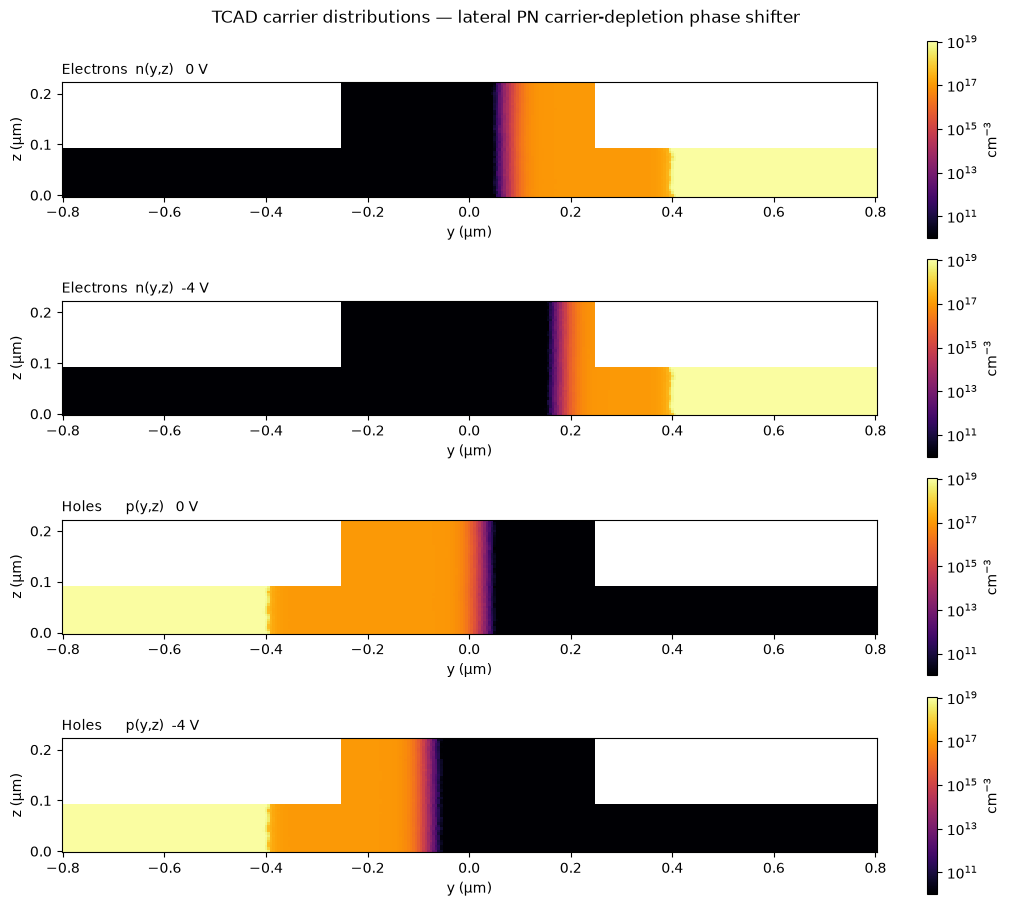

In [78]:
# Interpolate the TCAD carrier distributions onto a regular y-z grid and plot electrons and holes at 0 V and -4 V.

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

y_grid = np.linspace(-0.80, 0.80, 321)   # um, 5 nm steps laterally
z_grid = np.linspace(0.00, 0.22, 45)     # um, 5 nm steps vertically

def carrier_map(dataset, voltage):
    da = dataset.sel(voltage=voltage).interp(
        x=0.0, y=y_grid, z=z_grid, fill_value=np.nan
    ).squeeze(drop=True)
    print(f"   interp dims {da.dims} shape {da.shape}")
    return da.transpose("z", "y").values

print("Building carrier maps:")
panels = [
    ("Electrons  n(y,z)   0 V",  carrier_map(electrons, 0.0)),
    ("Electrons  n(y,z)  -4 V",  carrier_map(electrons, -4.0)),
    ("Holes      p(y,z)   0 V",  carrier_map(holes, 0.0)),
    ("Holes      p(y,z)  -4 V",  carrier_map(holes, -4.0)),
]

fig, axes = plt.subplots(4, 1, figsize=(10, 9), constrained_layout=True)
for ax, (title, data) in zip(axes, panels):
    mesh = ax.pcolormesh(
        y_grid, z_grid, data,
        norm=LogNorm(vmin=1e10, vmax=1.1e19),
        cmap="inferno", shading="auto",
    )
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("y (µm)")
    ax.set_ylabel("z (µm)")
    ax.set_aspect("equal")
    fig.colorbar(mesh, ax=ax, label="cm$^{-3}$")

fig.suptitle("TCAD carrier distributions — lateral PN carrier-depletion phase shifter")
plt.show()

   V    p-edge    n-edge    W_TCAD  W_analyt   ratio
   0   -0.0190    0.1185    0.1375    0.1470   0.935
  -1   -0.0540    0.1555    0.2095    0.2180   0.961
  -2   -0.0825    0.1825    0.2650    0.2710   0.978
  -3   -0.1045    0.2045    0.3090    0.3150   0.981
  -4   -0.1245    0.2250    0.3495    0.3540   0.987


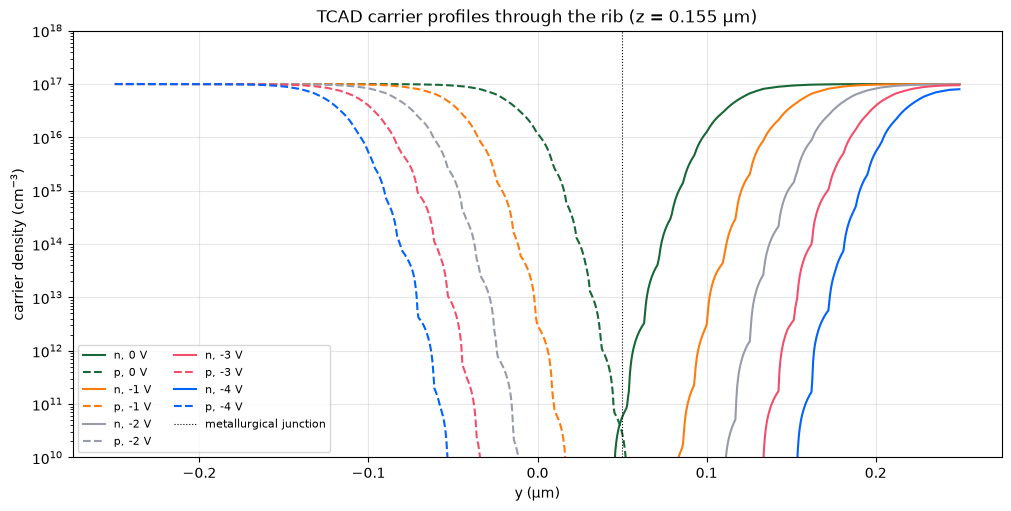

In [79]:
# Extract horizontal carrier profiles through the rib and compare TCAD depletion edges with the analytical model.

z_cut = 0.155                              # um, mid-height of the rib
y_line = np.linspace(-0.40, 0.40, 1601)    # 0.5 nm steps across the junction

def profile(dataset, voltage):
    return np.squeeze(
        dataset.sel(voltage=float(voltage))
               .interp(x=0.0, y=y_line, z=z_cut, fill_value=np.nan)
               .values
    )

n_profiles = {V: profile(electrons, V) for V in voltages}
p_profiles = {V: profile(holes, V) for V in voltages}

# Depletion edge defined where the majority carrier falls to half its doping level.
threshold = 0.5 * 1e17
W_analytical = np.array([0.147, 0.218, 0.271, 0.315, 0.354])   # from this notebook's earlier output

print(f"{'V':>4} {'p-edge':>9} {'n-edge':>9} {'W_TCAD':>9} {'W_analyt':>9} {'ratio':>7}")
for i, V in enumerate(voltages):
    p_edge = y_line[p_profiles[V] > threshold].max()
    n_edge = y_line[n_profiles[V] > threshold].min()
    W_tcad = n_edge - p_edge
    print(f"{V:>4.0f} {p_edge:>9.4f} {n_edge:>9.4f} {W_tcad:>9.4f} "
          f"{W_analytical[i]:>9.4f} {W_tcad/W_analytical[i]:>7.3f}")

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for V in voltages:
    line, = ax.semilogy(y_line, n_profiles[V], label=f"n, {V:.0f} V")
    ax.semilogy(y_line, p_profiles[V], "--", color=line.get_color(), label=f"p, {V:.0f} V")
ax.axvline(0.05, color="k", lw=0.8, ls=":", label="metallurgical junction")
ax.set_xlabel("y (µm)")
ax.set_ylabel("carrier density (cm$^{-3}$)")
ax.set_ylim(1e10, 1e18)
ax.set_title(f"TCAD carrier profiles through the rib (z = {z_cut} µm)")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)
plt.show()

In [80]:
# Re-run the Charge sweep at coarser and finer mesh spacing to test convergence of depletion width and capacitance.

convergence_data = {}

for dl_test in [0.02, 0.005]:
    grid_test = charge_grid.updated_copy(dl=dl_test)
    sim_test = charge_sim.updated_copy(grid_spec=grid_test)

    job_test = web.Job(
        simulation=sim_test,
        task_name=f"PN_charge_sweep_dl{int(dl_test * 1000)}nm",
        folder_name="MZI_Modulator",
        verbose=True,
    )
    data_test = job_test.run(
        path=f"../Results/PN_charge_sweep_dl{int(dl_test * 1000)}nm.hdf5"
    )
    convergence_data[dl_test] = data_test

    print(f"\ndl = {dl_test * 1000:.0f} nm  ->  billed {job_test.real_cost()} FlexCredits\n")

print("Completed mesh spacings:", [f"{k*1000:.0f} nm" for k in convergence_data])

18:13:13 Central Daylight Time WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

...

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Warning messages were found in the      
                               solver log. For more information, check          
                               'SimulationData.log' or use                      
                               'web.download_log(task_id)'.                     

                               Total billed flex credit cost: 0.025.


dl = 5 nm  ->  billed 0.025 FlexCredits

Completed mesh spacings: ['20 nm', '5 nm']


In [81]:
# Diagnose and robustly extract depletion width and capacitance across the three mesh spacings.

def safe_max(arr):
    return np.nanmax(arr) if np.isfinite(arr).any() else np.nan

def edge_positions(n_prof, p_prof):
    n_hits = y_line[np.nan_to_num(n_prof, nan=0.0) > threshold]
    p_hits = y_line[np.nan_to_num(p_prof, nan=0.0) > threshold]
    return (
        p_hits.max() if p_hits.size else np.nan,
        n_hits.min() if n_hits.size else np.nan,
    )

def extract_metrics(data, label):
    e = data["carrier_distribution"].electrons
    h = data["carrier_distribution"].holes
    cap = data["junction_capacitance"]

    W = []
    for V in voltages:
        n_prof = np.squeeze(
            e.sel(voltage=float(V)).interp(x=0.0, y=y_line, z=z_cut, fill_value=np.nan).values
        )
        p_prof = np.squeeze(
            h.sel(voltage=float(V)).interp(x=0.0, y=y_line, z=z_cut, fill_value=np.nan).values
        )
        p_edge, n_edge = edge_positions(n_prof, p_prof)
        print(f"   {label:>6} V={V:>3.0f}  finite={np.isfinite(n_prof).sum():>5d}/{y_line.size}"
              f"  max_n={safe_max(n_prof):.2e}  max_p={safe_max(p_prof):.2e}"
              f"  p_edge={p_edge}  n_edge={n_edge}")
        W.append(n_edge - p_edge)

    C = np.array([float(cap.hole_capacitance.sel(v=float(V))) for V in voltages])
    return np.array(W), C

mesh_sets = {
    0.020: convergence_data[0.02],
    0.010: charge_data,
    0.005: convergence_data[0.005],
}

W_by_dl, C_by_dl = {}, {}
print("Diagnostics:")
for dl_val, data in mesh_sets.items():
    W_by_dl[dl_val], C_by_dl[dl_val] = extract_metrics(data, f"{dl_val*1000:.0f}nm")

print("\nDepletion width W (um):")
print(f"{'V':>4} {'20 nm':>9} {'10 nm':>9} {'5 nm':>9} {'|10-5| nm':>11} {'analytic':>10}")
for i, V in enumerate(voltages):
    delta = abs(W_by_dl[0.010][i] - W_by_dl[0.005][i]) * 1000
    print(f"{V:>4.0f} {W_by_dl[0.020][i]:>9.4f} {W_by_dl[0.010][i]:>9.4f} "
          f"{W_by_dl[0.005][i]:>9.4f} {delta:>11.2f} {W_analytical[i]:>10.4f}")

print("\nCapacitance C (fF/um):")
print(f"{'V':>4} {'20 nm':>9} {'10 nm':>9} {'5 nm':>9} {'|10-5| %':>10} {'analytic':>10}")
for i, V in enumerate(voltages):
    rel = abs(C_by_dl[0.010][i] - C_by_dl[0.005][i]) / C_by_dl[0.005][i] * 100
    print(f"{V:>4.0f} {C_by_dl[0.020][i]:>9.4f} {C_by_dl[0.010][i]:>9.4f} "
          f"{C_by_dl[0.005][i]:>9.4f} {rel:>10.2f} {analytical_Cj_per_L[i]:>10.4f}")

Diagnostics:
     20nm V=  0  finite=    0/1601  max_n=nan  max_p=nan  p_edge=nan  n_edge=nan
     20nm V= -1  finite=    0/1601  max_n=nan  max_p=nan  p_edge=nan  n_edge=nan
     20nm V= -2  finite=    0/1601  max_n=nan  max_p=nan  p_edge=nan  n_edge=nan
     20nm V= -3  finite=    0/1601  max_n=nan  max_p=nan  p_edge=nan  n_edge=nan
     20nm V= -4  finite=    0/1601  max_n=nan  max_p=nan  p_edge=nan  n_edge=nan
     10nm V=  0  finite= 1000/1601  max_n=1.00e+17  max_p=1.00e+17  p_edge=-0.019000000000000017  n_edge=0.11849999999999994
     10nm V= -1  finite= 1000/1601  max_n=9.99e+16  max_p=1.00e+17  p_edge=-0.05399999999999999  n_edge=0.15549999999999997
     10nm V= -2  finite= 1000/1601  max_n=9.91e+16  max_p=1.00e+17  p_edge=-0.08250000000000002  n_edge=0.1825
     10nm V= -3  finite= 1000/1601  max_n=9.52e+16  max_p=1.00e+17  p_edge=-0.10450000000000004  n_edge=0.20450000000000002
     10nm V= -4  finite= 1000/1601  max_n=7.98e+16  max_p=1.00e+17  p_edge=-0.1245  n_edge=0.22499

In [82]:
# Diagnose why the 20 nm mesh dataset returns no valid carrier or capacitance values.

data20 = convergence_data[0.02]
e20 = data20["carrier_distribution"].electrons
cap20 = data20["junction_capacitance"]

print("20 nm carrier dataset:")
print(f"   bounds:        {e20.bounds}")
print(f"   points shape:  {np.asarray(e20.points).shape}")
print(f"   values shape:  {e20.values.shape}")
vals20 = np.asarray(e20.values.values)
print(f"   finite values: {np.isfinite(vals20).sum()} / {vals20.size}")
if np.isfinite(vals20).any():
    print(f"   min/max:       {np.nanmin(vals20):.3e} / {np.nanmax(vals20):.3e}")
print()

print("20 nm capacitance:")
print(f"   hole:     {np.asarray(cap20.hole_capacitance.values)}")
print(f"   electron: {np.asarray(cap20.electron_capacitance.values)}")
print()


print("Solver log (20 nm):")
print(data20.log)

20 nm carrier dataset:
   bounds:        ((np.float32(0.0), np.float32(-0.8), np.float32(0.0)), (np.float32(0.0), np.float32(0.8), np.float32(0.22)))
   points shape:  (790, 2)
   values shape:  (790, 5)
   finite values: 110 / 3950
   min/max:       2.065e+02 / 1.010e+19

20 nm capacitance:
   hole:     [nan nan nan nan nan]
   electron: [nan nan nan nan nan]

Solver log (20 nm):
[06:20:04] WARNING: Structure at 'structures[0]' has bounds that extend exactly 
           to simulation edges. This can cause unexpected behavior. If intending
           to extend the structure to infinity along one dimension, use td.inf  
           as a size variable instead to make this explicit.                    
           USER: Mesh type:                                             3D      
           USER: Mesh nodes:                                            1580    
           USER: Mesh prisms:                                           1393    
           USER: Mesh triangles:                 

In [83]:
# Compute the extrinsic Debye length at the active doping to explain the Charge mesh convergence threshold.

eps_0 = 8.8541878128e-12      # F/m, vacuum permittivity
eps_si = 11.7                 # relative permittivity of silicon
q = 1.602176634e-19           # C, elementary charge
kB = 1.380649e-23             # J/K, Boltzmann constant
T_K = 300.0                   # K, isothermal analysis temperature
N_active_m3 = 1e17 * 1e6      # cm^-3 -> m^-3

L_D = np.sqrt(eps_si * eps_0 * kB * T_K / (q**2 * N_active_m3))
print(f"Extrinsic Debye length at 1e17 cm^-3, 300 K: {L_D * 1e9:.2f} nm\n")

print(f"{'mesh dl (nm)':>13} {'dl / L_D':>10}   Newton convergence")
for dl_nm, status in [(20, "failed, 5/5 bias points"), (10, "converged"), (5, "converged")]:
    print(f"{dl_nm:>13} {dl_nm * 1e-9 / L_D:>10.2f}   {status}")

Extrinsic Debye length at 1e17 cm^-3, 300 K: 12.93 nm

 mesh dl (nm)   dl / L_D   Newton convergence
           20       1.55   failed, 5/5 bias points
           10       0.77   converged
            5       0.39   converged


In [84]:
# Check which key variables survive in the kernel before continuing into Phase B.

import numpy as np
import tidy3d as td

required = [
    "charge_data", "electrons", "holes", "cap_data",
    "voltages", "si_height", "slab_height", "rib_width",
    "wavelength", "freq0", "n_si", "n_sio2",
    "y_line", "z_cut", "threshold",
]

present = [name for name in required if name in globals()]
missing = [name for name in required if name not in globals()]

print(f"present ({len(present)}): {present}")
print(f"missing ({len(missing)}): {missing}")

if "charge_data" in globals():
    print(f"\ncharge_data type: {type(charge_data).__name__}")
    print(f"capacitance (fF/um): {np.asarray(charge_data['junction_capacitance'].hole_capacitance.values)}")

present (15): ['charge_data', 'electrons', 'holes', 'cap_data', 'voltages', 'si_height', 'slab_height', 'rib_width', 'wavelength', 'freq0', 'n_si', 'n_sio2', 'y_line', 'z_cut', 'threshold']
missing (0): []

charge_data type: HeatChargeSimulationData
capacitance (fF/um): [0.06884395 0.07389139 0.08709544 0.11242722 0.12960239]


In [85]:
# Interpolate TCAD carrier distributions onto the optical grid used by the analytical plasma-dispersion workflow.

# Optical grid — same convention as the analytical carrier maps already in this notebook
y_opt = np.linspace(-1.0, 1.0, 801)        # um, 2.5 nm steps
z_opt = np.linspace(0.0, si_height, 221)   # um, 1 nm steps
Y_opt, Z_opt = np.meshgrid(y_opt, z_opt, indexing="ij")

# Silicon mask: slab everywhere, rib only within +/- rib_width/2
silicon_mask_opt = (Z_opt <= slab_height) | ((np.abs(Y_opt) <= rib_width / 2) & (Z_opt <= si_height))

if "silicon_mask" in globals():
    same = (silicon_mask.shape == silicon_mask_opt.shape) and np.array_equal(silicon_mask, silicon_mask_opt)
    print(f"analytical mask {silicon_mask.shape} vs TCAD-side mask {silicon_mask_opt.shape} -> identical: {same}")

def tcad_on_optical_grid(dataset, voltage):
    da = (dataset.sel(voltage=float(voltage))
                 .interp(x=0.0, y=y_opt, z=z_opt, fill_value=np.nan)
                 .squeeze(drop=True)
                 .transpose("y", "z"))
    arr = np.asarray(da.values)
    arr = np.nan_to_num(arr, nan=0.0)   # outside the TCAD mesh (|y| > 0.8)
    arr[~silicon_mask_opt] = 0.0        # outside silicon (oxide)
    return arr

N_tcad = {int(V): tcad_on_optical_grid(electrons, V) for V in voltages}
P_tcad = {int(V): tcad_on_optical_grid(holes, V) for V in voltages}

print(f"\ngrid shape: {N_tcad[0].shape}")
for V in voltages:
    V = int(V)
    print(f"V={V:>3d}   N max={N_tcad[V].max():.3e}   P max={P_tcad[V].max():.3e}   "
          f"N mean in Si={N_tcad[V][silicon_mask_opt].mean():.3e}")

analytical mask (221, 801) vs TCAD-side mask (801, 221) -> identical: False

grid shape: (801, 221)
V=  0   N max=1.010e+19   P max=1.010e+19   N mean in Si=1.505e+18
V= -1   N max=1.010e+19   P max=1.010e+19   N mean in Si=1.502e+18
V= -2   N max=1.010e+19   P max=1.010e+19   N mean in Si=1.499e+18
V= -3   N max=1.010e+19   P max=1.010e+19   N mean in Si=1.497e+18
V= -4   N max=1.010e+19   P max=1.010e+19   N mean in Si=1.495e+18


In [86]:
# Verify the (y,z) TCAD/mask grid is a consistent transpose of the (z,y) analytical grid before building optical media.

import numpy as np

print("shapes")
print(f"  silicon_mask      (z,y) : {silicon_mask.shape}")
print(f"  silicon_mask_opt  (y,z) : {silicon_mask_opt.shape}")
print(f"  N_tcad[0.0]       (y,z) : {N_tcad[0.0].shape}")
print(f"  y_opt / z_opt           : {y_opt.shape} / {z_opt.shape}")

same = np.array_equal(silicon_mask.T, silicon_mask_opt)
print(f"\nnp.array_equal(silicon_mask.T, silicon_mask_opt) : {same}")

frac_an  = silicon_mask.mean()
frac_opt = silicon_mask_opt.mean()
print(f"silicon fraction, analytical (z,y) : {frac_an:.6f}  ({silicon_mask.sum()} pts)")
print(f"silicon fraction, optical    (y,z) : {frac_opt:.6f}  ({silicon_mask_opt.sum()} pts)")
print(f"difference                          : {abs(frac_an - frac_opt):.3e}")

# Geometric cross-check: mask area vs the intended rib+slab cross-section.
dy = y_opt[1] - y_opt[0]
dz = z_opt[1] - z_opt[0]
area_mask = silicon_mask_opt.sum() * dy * dz
area_geom = 3.0 * 0.090 + 0.500 * (0.220 - 0.090)   # slab clipped to the ±1.0 µm optical window below
area_geom = (y_opt[-1] - y_opt[0]) * 0.090 + 0.500 * (0.220 - 0.090)
print(f"\nmask area   : {area_mask:.6f} µm²")
print(f"geometry    : {area_geom:.6f} µm²  (slab over the ±1 µm window + rib)")

# Carrier-array health: NaNs must be confined to non-silicon, and silicon must be fully populated.
for V in sorted(N_tcad):
    n, p = N_tcad[V], P_tcad[V]
    nan_in_si = np.isnan(n[silicon_mask_opt]).sum() + np.isnan(p[silicon_mask_opt]).sum()
    print(f"  V = {V:+.1f} V : N max {np.nanmax(n):.3e}  P max {np.nanmax(p):.3e} cm^-3 | "
          f"NaNs inside silicon {nan_in_si} | NaNs total {np.isnan(n).sum()}")

shapes
  silicon_mask      (z,y) : (221, 801)
  silicon_mask_opt  (y,z) : (801, 221)
  N_tcad[0.0]       (y,z) : (801, 221)
  y_opt / z_opt           : (801,) / (221,)

np.array_equal(silicon_mask.T, silicon_mask_opt) : True
silicon fraction, analytical (z,y) : 0.559374  (99021 pts)
silicon fraction, optical    (y,z) : 0.559374  (99021 pts)
difference                          : 0.000e+00

mask area   : 0.247552 µm²
geometry    : 0.245000 µm²  (slab over the ±1 µm window + rib)
  V = -4.0 V : N max 1.010e+19  P max 1.010e+19 cm^-3 | NaNs inside silicon 0 | NaNs total 0
  V = -3.0 V : N max 1.010e+19  P max 1.010e+19 cm^-3 | NaNs inside silicon 0 | NaNs total 0
  V = -2.0 V : N max 1.010e+19  P max 1.010e+19 cm^-3 | NaNs inside silicon 0 | NaNs total 0
  V = -1.0 V : N max 1.010e+19  P max 1.010e+19 cm^-3 | NaNs inside silicon 0 | NaNs total 0
  V = +0.0 V : N max 1.010e+19  P max 1.010e+19 cm^-3 | NaNs inside silicon 0 | NaNs total 0


In [87]:
# Apply Soref-Bennett plasma dispersion to the TCAD carriers, referenced to the 0 V TCAD state.

import numpy as np

# Soref-Bennett empirical coefficients at lambda = 1.55 um, N and P in cm^-3 (literature values).
A_N, A_P, PWR_P = 8.8e-22, 8.5e-18, 0.8      # index terms
B_N, B_P        = 8.5e-18, 6.0e-18           # absorption terms, give alpha in cm^-1

def soref_bennett_dn(dN, dP):
    """Delta n from carrier CHANGE. Odd extension of the 0.8 power handles carrier removal."""
    return -(A_N * dN + A_P * np.sign(dP) * np.abs(dP) ** PWR_P)

V_list = sorted(N_tcad, reverse=True)        # 0, -1, -2, -3, -4
N_ref, P_ref = N_tcad[0.0], P_tcad[0.0]      # 0 V TCAD state is the reference

dn_tcad, dalpha_tcad, alpha_abs_tcad = {}, {}, {}

for V in V_list:
    dN = N_tcad[V] - N_ref
    dP = P_tcad[V] - P_ref
    dn_tcad[V]     = soref_bennett_dn(dN, dP)                      # dimensionless
    dalpha_tcad[V] = B_N * dN + B_P * dP                           # cm^-1, rel. to 0 V
    alpha_abs_tcad[V] = B_N * N_tcad[V] + B_P * P_tcad[V]          # cm^-1, absolute

print(f"{'V':>5} {'max dn':>11} {'min dn':>11} {'max|dN|':>11} {'max|dP|':>11} "
      f"{'d_alpha':>10} {'alpha_abs':>11}")
print(f"{'':>5} {'':>11} {'':>11} {'cm^-3':>11} {'cm^-3':>11} {'dB/cm':>10} {'dB/cm':>11}")
for V in V_list:
    dN = N_tcad[V] - N_ref
    dP = P_tcad[V] - P_ref
    print(f"{V:>+5.0f} {dn_tcad[V].max():>11.4e} {dn_tcad[V].min():>11.4e} "
          f"{np.abs(dN).max():>11.3e} {np.abs(dP).max():>11.3e} "
          f"{4.343*dalpha_tcad[V][silicon_mask_opt].mean():>10.4f} "
          f"{4.343*alpha_abs_tcad[V][silicon_mask_opt].mean():>11.4f}")

# Locate the peak index change at -4 V; it should sit on the junction at y = +0.05 um.
iy, iz = np.unravel_index(np.argmax(dn_tcad[-4.0]), dn_tcad[-4.0].shape)
print(f"\npeak dn at -4 V : {dn_tcad[-4.0].max():.4e} at y = {y_opt[iy]:+.4f} um, "
      f"z = {z_opt[iz]:.4f} um   (junction offset is +0.0500 um)")
print(f"analytical-carrier peak dn at -4 V (handoff 11C) : 3.384e-04")
print(f"sign check: dn > 0 where carriers were removed  -> {(dn_tcad[-4.0] >= 0).sum()} of "
      f"{silicon_mask_opt.sum()} silicon points non-negative")


    V      max dn      min dn     max|dN|     max|dP|    d_alpha   alpha_abs
                                    cm^-3       cm^-3      dB/cm       dB/cm
   +0 -0.0000e+00 -0.0000e+00   0.000e+00   0.000e+00     0.0000     94.9411
   -1  2.6170e-04 -0.0000e+00   7.252e+16   7.252e+16    -0.2067     94.7344
   -2  3.1842e-04 -0.0000e+00   9.261e+16   9.268e+16    -0.3586     94.5825
   -3  3.3254e-04 -0.0000e+00   9.785e+16   9.784e+16    -0.4844     94.4566
   -4  3.3650e-04 -0.0000e+00   9.931e+16   9.930e+16    -0.5939     94.3472

peak dn at -4 V : 3.3650e-04 at y = -0.0850 um, z = 0.1950 um   (junction offset is +0.0500 um)
analytical-carrier peak dn at -4 V (handoff 11C) : 3.384e-04
sign check: dn > 0 where carriers were removed  -> 177021 of 99021 silicon points non-negative


In [88]:
# Corrected sign check, plus a p-side / n-side decomposition of the -4 V index change.

dn4 = dn_tcad[-4.0]
dn4_si = dn4[silicon_mask_opt]
print(f"sign check: {(dn4_si >= 0).sum()} of {dn4_si.size} silicon points have dn >= 0")
print(f"            min dn in silicon = {dn4_si.min():.4e}")

# Split by side of the metallurgical junction; y_opt[:,None] is (801,1) and broadcasts
# correctly against the (y,z) arrays -- an analytical (z,y) array would broadcast wrong here.
Y_JUNC = 0.05
y_grid = y_opt[:, None]
p_side = silicon_mask_opt & (y_grid <  Y_JUNC)
n_side = silicon_mask_opt & (y_grid >= Y_JUNC)

dN4 = N_tcad[-4.0] - N_ref
dP4 = P_tcad[-4.0] - P_ref
term_e = -A_N * dN4                                     # electron contribution to dn
term_h = -A_P * np.sign(dP4) * np.abs(dP4) ** PWR_P     # hole contribution to dn

print(f"\n-4 V index-change decomposition")
print(f"  hole term     max : {term_h.max():.4e}  (p-side {term_h[p_side].max():.4e})")
print(f"  electron term max : {term_e.max():.4e}  (n-side {term_e[n_side].max():.4e})")
print(f"  hole/electron leverage at full 1e17 depletion : "
      f"{(A_P * 1e17**PWR_P) / (A_N * 1e17):.2f}x")
print(f"\n  mean dn over p-side silicon : {dn4[p_side].mean():.4e}")
print(f"  mean dn over n-side silicon : {dn4[n_side].mean():.4e}")


sign check: 99021 of 99021 silicon points have dn >= 0
            min dn in silicon = -0.0000e+00

-4 V index-change decomposition
  hole term     max : 3.3650e-04  (p-side 3.3650e-04)
  electron term max : 8.7391e-05  (n-side 8.7391e-05)
  hole/electron leverage at full 1e17 depletion : 3.85x

  mean dn over p-side silicon : 6.3151e-05
  mean dn over n-side silicon : 1.8170e-05


In [89]:
# Build per-voltage CustomMedia from the TCAD index maps, matching the analytical workflow's conventions.

# dn_tcad is already (y, z), so NO .T here -- unlike the analytical eps_map.T which was (z, y).
same_y = y_opt.shape == y.shape and np.allclose(y_opt, y)
same_z = z_opt.shape == z.shape and np.allclose(z_opt, z)
print(f"optical grid matches analytical grid?   y: {same_y}   z: {same_z}")

mapped_width_tcad = float(y_opt[-1] - y_opt[0])
print(f"mapped_width_tcad = {mapped_width_tcad:.4f} um   "
      f"(analytical mapped_width = {y[-1] - y[0]:.4f} um)")

silicon_tcad = {}
for V in V_list:
    n_map_V = n_si + dn_tcad[V]        # dn = 0 outside silicon, so the map is plain n_si there
    silicon_tcad[V] = td.CustomMedium(
        permittivity=td.SpatialDataArray(
            (n_map_V ** 2)[np.newaxis, :, :],
            coords={"x": [0.0], "y": y_opt, "z": z_opt},
        ),
        interp_method="linear",
    )

ex = silicon_tcad[-4.0].permittivity
print(f"\nSpatialDataArray dims {ex.dims}  shape {ex.shape}   "
      f"(want ('x','y','z') = (1, 801, 221))")

print(f"\n{'V':>5} {'n min':>11} {'n max':>11} {'n max - n_si':>14}")
for V in V_list:
    n_map_V = n_si + dn_tcad[V]
    print(f"{V:>+5.0f} {n_map_V.min():>11.6f} {n_map_V.max():>11.6f} "
          f"{n_map_V.max() - n_si:>14.4e}")

n0 = n_si + dn_tcad[0.0]
print(f"\n0 V map uniform at n_si? {np.allclose(n0, n_si, rtol=0, atol=1e-15)}"
      f"   max deviation {np.abs(n0 - n_si).max():.3e}")


optical grid matches analytical grid?   y: True   z: True
mapped_width_tcad = 2.0000 um   (analytical mapped_width = 2.0000 um)

SpatialDataArray dims ('x', 'y', 'z')  shape (1, 801, 221)   (want ('x','y','z') = (1, 801, 221))

    V       n min       n max   n max - n_si
   +0    3.470000    3.470000     0.0000e+00
   -1    3.470000    3.470262     2.6178e-04
   -2    3.470000    3.470319     3.1853e-04
   -3    3.470000    3.470333     3.3259e-04
   -4    3.470000    3.470336     3.3641e-04

0 V map uniform at n_si? True   max deviation 0.000e+00


In [90]:
# Verify the index maps are bit-consistent with dn, then construct (not yet solve) one mode solver per bias.

# (n_si + dn) - n_si must return dn to within ~1 ulp; a larger gap means a stale array, not rounding.
print(f"{'V':>5} {'dn max':>16} {'(n_map-n_si) max':>18} {'difference':>13}")
for V in V_list:
    a = dn_tcad[V].max()
    b = (n_si + dn_tcad[V]).max() - n_si
    print(f"{V:>+5.0f} {a:>16.10e} {b:>18.10e} {b - a:>13.2e}")

sim_tcad, modesolver_tcad = {}, {}
for V in V_list:
    slab_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height / 2),
            size=(td.inf, mapped_width_tcad, slab_height),
        ),
        medium=silicon_tcad[V],
    )
    rib_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height + etch_depth / 2),
            size=(td.inf, rib_width, etch_depth),
        ),
        medium=silicon_tcad[V],
    )
    sim_tcad[V] = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
        structures=[slab_V, rib_V],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
    )
    modesolver_tcad[V] = ModeSolver(
        simulation=sim_tcad[V],
        plane=mode_plane,
        mode_spec=td.ModeSpec(num_modes=1, target_neff=2.57),
        freqs=[freq0],
    )

print(f"\nbuilt {len(modesolver_tcad)} mode solvers for V = {V_list}")
print(f"domain (y, z) = ({domain_y}, {domain_z}) um, min_steps_per_wvl = 30")
print(f"structures per sim: {len(sim_tcad[-4.0].structures)}   "
      f"slab {mapped_width_tcad:.3f} um wide, rib {rib_width:.3f} um wide")


    V           dn max   (n_map-n_si) max    difference
   +0 -0.0000000000e+00   0.0000000000e+00      0.00e+00
   -1 2.6170298224e-04   2.6178359985e-04      8.06e-08
   -2 3.1841621967e-04   3.1852722168e-04      1.11e-07
   -3 3.3253550646e-04   3.3259391785e-04      5.84e-08
   -4 3.3649845864e-04   3.3640861511e-04     -8.98e-08


c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `float` - serialized value may not be as expected [field_name='dl_min', input_value=np.float32(0.007444764), input_type=float32])
  return self.__pydantic_serializer__.to_python(
c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `float` - serialized value may not be as expected [field_name='dl_min', input_value=np.float32(0.007444203), input_type=float32])
  return self.__pydantic_serializer__.to_python(
c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `float` - serialized value may not be as expected [field_name='dl_min', input_value=np.float32(0.0074440814), input_type


built 5 mode solvers for V = [0, -1, -2, -3, -4]
domain (y, z) = (3.5, 2.5) um, min_steps_per_wvl = 30
structures per sim: 2   slab 2.000 um wide, rib 0.500 um wide


c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `float` - serialized value may not be as expected [field_name='dl_min', input_value=np.float32(0.0074440422), input_type=float32])
  return self.__pydantic_serializer__.to_python(


In [93]:
# Rebuild the index maps and solvers in float64; the previous maps inherited float32 from the TCAD data.

print(f"dtypes   dn_tcad[-4]: {dn_tcad[-4.0].dtype}    N_tcad[-4]: {N_tcad[-4.0].dtype}")
print(f"         previous eps map: {np.asarray(silicon_tcad[-4.0].permittivity).dtype}")
print(f"float32 spacing near 3.47 : {np.spacing(np.float32(3.47)):.3e}   "
      f"float64: {np.spacing(3.47):.3e}\n")

silicon_tcad, sim_tcad, modesolver_tcad = {}, {}, {}
for V in V_list:
    n_map_V = n_si + dn_tcad[V].astype(np.float64)
    silicon_tcad[V] = td.CustomMedium(
        permittivity=td.SpatialDataArray(
            (n_map_V ** 2)[np.newaxis, :, :],
            coords={"x": [0.0], "y": y_opt, "z": z_opt},
        ),
        interp_method="linear",
    )
    slab_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height / 2),
            size=(td.inf, mapped_width_tcad, slab_height),
        ),
        medium=silicon_tcad[V],
    )
    rib_V = td.Structure(
        geometry=td.Box(
            center=(0, 0, slab_height + etch_depth / 2),
            size=(td.inf, rib_width, etch_depth),
        ),
        medium=silicon_tcad[V],
    )
    sim_tcad[V] = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
        structures=[slab_V, rib_V],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
    )
    modesolver_tcad[V] = ModeSolver(
        simulation=sim_tcad[V],
        plane=mode_plane,
        mode_spec=td.ModeSpec(num_modes=1, target_neff=2.57),
        freqs=[freq0],
    )

print(f"rebuilt eps map dtype: {np.asarray(silicon_tcad[-4.0].permittivity).dtype}\n")
print(f"{'V':>5} {'dn max':>16} {'(n_map-n_si) max':>18} {'difference':>13}")
for V in V_list:
    a = float(dn_tcad[V].astype(np.float64).max())
    b = float((n_si + dn_tcad[V].astype(np.float64)).max() - n_si)
    print(f"{V:>+5.0f} {a:>16.10e} {b:>18.10e} {b - a:>13.2e}")


dtypes   dn_tcad[-4]: float32    N_tcad[-4]: float32
         previous eps map: float64
float32 spacing near 3.47 : 2.384e-07   float64: 4.441e-16

rebuilt eps map dtype: float64

    V           dn max   (n_map-n_si) max    difference
   +0 -0.0000000000e+00   0.0000000000e+00      0.00e+00
   -1 2.6170298224e-04   2.6170298224e-04      0.00e+00
   -2 3.1841621967e-04   3.1841621967e-04      0.00e+00
   -3 3.3253550646e-04   3.3253550646e-04      0.00e+00
   -4 3.3649845864e-04   3.3649845864e-04      0.00e+00


In [94]:
# Remotely solve the fundamental TE mode at each bias using the TCAD-derived index maps.

from tidy3d.plugins.mode.web import run as run_mode_solver

# Touch the analytical results first so a missing variable fails before any credits are spent.
print(f"analytical reference: 0 V n_eff = {neff_vs_voltage[0]:.8f}, "
      f"{len(delta_neff_vs_voltage)} points, voltages = {list(voltages)}")
print(f"TCAD biases: {V_list}\n")

an_lookup = {float(v): float(d) for v, d in zip(voltages, delta_neff_vs_voltage)}
neff_tcad = {}

for V in V_list:
    # target_neff=2.63 matches cell 26 so the mode search is identical between the two studies.
    solver_V = ModeSolver(
        simulation=sim_tcad[V],
        plane=mode_plane,
        mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63),
        freqs=[freq0],
    )
    mode_data_V = run_mode_solver(solver_V, task_name=f"PN_TCAD_{abs(int(V))}V")
    neff_tcad[V] = float(mode_data_V.n_eff.isel(f=0, mode_index=0))
    print(f"V = {V:>3.0f} V  |  n_eff = {neff_tcad[V]:.8f}")

neff_tcad_arr = np.array([neff_tcad[V] for V in V_list])
dneff_tcad_arr = neff_tcad_arr - neff_tcad_arr[0]

print(f"\n{'V':>5} {'n_eff (TCAD)':>15} {'dn_eff TCAD':>14} {'dn_eff analytic':>17} {'ratio':>8}")
for i, V in enumerate(V_list):
    an = an_lookup[float(V)]
    ratio = dneff_tcad_arr[i] / an if an != 0 else float("nan")
    print(f"{V:>+5.0f} {neff_tcad_arr[i]:>15.8f} {dneff_tcad_arr[i]:>+14.3e} "
          f"{an:>+17.3e} {ratio:>8.3f}")

print(f"\n0 V validation: TCAD {neff_tcad_arr[0]:.8f}  vs  analytical {neff_vs_voltage[0]:.8f}"
      f"   difference {neff_tcad_arr[0] - neff_vs_voltage[0]:+.2e}")


analytical reference: 0 V n_eff = 2.63153495, 5 points, voltages = [np.int64(0), np.int64(-1), np.int64(-2), np.int64(-3), np.int64(-4)]
TCAD biases: [0, -1, -2, -3, -4]



18:51:05 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-a356e1f0-ce59-4158-b084-f99f335fa84
                               5',                                              
                               solver_id='mo-c3a42ff8-d4f6-4981-9cb5-717a7e6616b
                               3'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:51:10 Central Daylight Time Mode solver status: success

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

18:52:59 Central Daylight Time Mode solver status: queued

18:53:10 Central Daylight Time Mode solver status: running

18:53:12 Central Daylight Time Mode solver status: success

V =  -4 V  |  n_eff = 2.63162883

    V    n_eff (TCAD)    dn_eff TCAD   dn_eff analytic    ratio
   +0      2.63153495     +0.000e+00        +0.000e+00      nan
   -1      2.63157292     +3.797e-05        +2.559e-05    1.484
   -2      2.63159636     +6.141e-05        +5.164e-05    1.189
   -3      2.63161439     +7.944e-05        +6.452e-05    1.231
   -4      2.63162883     +9.388e-05        +8.474e-05    1.108

0 V validation: TCAD 2.63153495  vs  analytical 2.63153495   difference +0.00e+00


In [95]:
# Convert the TCAD-derived Dn_eff(V) into phase efficiency, Lpi, and effective VpiL, against the analytical values.

phase_per_mm_tcad = (2 * np.pi / wavelength) * dneff_tcad_arr * 1000      # rad/mm

Lpi_tcad = np.full_like(dneff_tcad_arr, np.nan)
VpiL_tcad = np.full_like(dneff_tcad_arr, np.nan)
for i, V in enumerate(V_list):
    if dneff_tcad_arr[i] != 0:
        Lpi_tcad[i] = wavelength / (2 * abs(dneff_tcad_arr[i]))          # um
        VpiL_tcad[i] = abs(V) * Lpi_tcad[i] * 1e-4                       # V.cm

vlist = list(voltages)
print(f"{'V':>5} {'dphi/L':>11} {'Lpi TCAD':>11} {'Lpi analyt':>11} "
      f"{'VpiL TCAD':>11} {'VpiL analyt':>12}")
print(f"{'':>5} {'rad/mm':>11} {'mm':>11} {'mm':>11} {'V.cm':>11} {'V.cm':>12}")
for i, V in enumerate(V_list):
    if V == 0:
        print(f"{V:>+5.0f} {'reference':>11} {'-':>11} {'-':>11} {'-':>11} {'-':>12}")
        continue
    j = vlist.index(V)
    print(f"{V:>+5.0f} {phase_per_mm_tcad[i]:>11.4f} {Lpi_tcad[i]/1000:>11.4f} "
          f"{Lpi_um[j]/1000:>11.4f} {VpiL_tcad[i]:>11.4f} {VpiL_Vcm[j]:>12.4f}")

i4, j4 = list(V_list).index(-4), vlist.index(-4)
print(f"\nAt -4 V  (TCAD vs analytical):")
print(f"  Dn_eff  {dneff_tcad_arr[i4]:.4e}  vs  {delta_neff_vs_voltage[j4]:.4e}")
print(f"  dphi/L  {phase_per_mm_tcad[i4]:.4f} rad/mm")
print(f"  Lpi     {Lpi_tcad[i4]/1000:.4f} mm  vs  {Lpi_um[j4]/1000:.4f} mm")
print(f"  VpiL    {VpiL_tcad[i4]:.4f} V.cm  vs  {VpiL_Vcm[j4]:.4f} V.cm")
print(f"  VpiL improves by {100 * (1 - VpiL_tcad[i4] / VpiL_Vcm[j4]):.1f} %")


    V      dphi/L    Lpi TCAD  Lpi analyt   VpiL TCAD  VpiL analyt
           rad/mm          mm          mm        V.cm         V.cm
   +0   reference           -           -           -            -
   -1      0.1539     20.4089     30.2842      2.0409       3.0284
   -2      0.2489     12.6202     15.0090      2.5240       3.0018
   -3      0.3220      9.7556     12.0114      2.9267       3.6034
   -4      0.3805      8.2555      9.1461      3.3022       3.6585

At -4 V  (TCAD vs analytical):
  Dn_eff  9.3877e-05  vs  8.4735e-05
  dphi/L  0.3805 rad/mm
  Lpi     8.2555 mm  vs  9.1461 mm
  VpiL    3.3022 V.cm  vs  3.6585 V.cm
  VpiL improves by 9.7 %


In [96]:
# Remotely solve the lossy TE0 mode at each bias from TCAD carriers, giving modal FCA including access regions.

modal_loss_tcad, lossy_neff_tcad = {}, {}

for V in V_list:
    n_real_V = n_si + dn_tcad[V].astype(np.float64)
    kappa_V = alpha_abs_tcad[V].astype(np.float64) * wavelength_cm / (4 * np.pi)
    kappa_V = np.where(silicon_mask_opt, kappa_V, 0.0)

    silicon_loss_V = td.CustomMedium.from_nk(
        n=td.SpatialDataArray(n_real_V[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        k=td.SpatialDataArray(kappa_V[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        freq=freq0,
        interp_method="linear",
    )

    slab_loss_V = td.Structure(
        geometry=td.Box(center=(0, 0, slab_height / 2),
                        size=(td.inf, mapped_width_tcad, slab_height)),
        medium=silicon_loss_V,
    )
    rib_loss_V = td.Structure(
        geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                        size=(td.inf, rib_width, etch_depth)),
        medium=silicon_loss_V,
    )
    sim_loss_V = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
        structures=[slab_loss_V, rib_loss_V],
        medium=silica,
        run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
    )
    solver_loss_V = ModeSolver(
        simulation=sim_loss_V,
        plane=mode_plane,
        mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63),
        freqs=[freq0],
    )
    mode_data_loss_V = run_mode_solver(
        solver_loss_V, task_name=f"PN_TCAD_loss_{abs(int(V))}V"
    )
    df_V = mode_data_loss_V.to_dataframe()

    lossy_neff_tcad[V] = float(mode_data_loss_V.n_eff.isel(f=0, mode_index=0))
    modal_loss_tcad[V] = float(df_V["loss (dB/cm)"].iloc[0])
    print(f"V = {V:>3.0f} V | n_eff = {lossy_neff_tcad[V]:.8f} | "
          f"loss = {modal_loss_tcad[V]:.6f} dB/cm")

vlist = list(voltages)
print(f"\n{'V':>5} {'loss TCAD':>12} {'loss analyt':>13} {'difference':>12}")
for V in V_list:
    a = float(modal_loss_vs_voltage[vlist.index(V)])
    t = modal_loss_tcad[V]
    print(f"{V:>+5.0f} {t:>12.4f} {a:>13.4f} {t - a:>+12.4f}")


19:09:58 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-641d85cf-c6fd-44fd-99b3-65fe926c7ec
                               6',                                              
                               solver_id='mo-07072b01-89f6-4316-a68c-0d59cc321de
                               4'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

19:10:05 Central Daylight Time Mode solver status: queued

19:10:47 Central Daylight Time Mode solver status: running

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

19:12:00 Central Daylight Time Mode solver status: queued

19:12:05 Central Daylight Time Mode solver status: running

19:12:07 Central Daylight Time Mode solver status: success

V =  -4 V | n_eff = 2.63162882 | loss = 7.383351 dB/cm

    V    loss TCAD   loss analyt   difference
   +0       8.5668        2.0005      +6.5663
   -1       8.0945        1.5403      +6.5542
   -2       7.7871        1.2170      +6.5701
   -3       7.5603        1.0551      +6.5052
   -4       7.3834        0.8458      +6.5376


In [97]:
# Attribute the constant loss pedestal by re-solving 0 V with the heavy access regions made transparent.

# Identify heavy-doped silicon from the carrier data itself rather than from assumed geometry.
heavy_mask = silicon_mask_opt & ((N_tcad[0.0] > 5e17) | (P_tcad[0.0] > 5e17))
ys = y_opt[np.any(heavy_mask, axis=1)]
zs = z_opt[np.any(heavy_mask, axis=0)]
print(f"heavy-doped points: {heavy_mask.sum()} of {silicon_mask_opt.sum()} silicon "
      f"({100 * heavy_mask.sum() / silicon_mask_opt.sum():.2f} %)")
print(f"spans y = [{ys.min():+.3f}, {ys.max():+.3f}] um,  z = [{zs.min():.3f}, {zs.max():.3f}] um")
print(f"rib edge at y = +/-{rib_width / 2:.3f} um  ->  gap to heavy doping = "
      f"{min(abs(ys.min()), abs(ys.max())) - rib_width / 2:.3f} um\n")

V_att = 0.0
n_real_att = n_si + dn_tcad[V_att].astype(np.float64)
kappa_full = np.where(silicon_mask_opt,
                      alpha_abs_tcad[V_att].astype(np.float64) * wavelength_cm / (4 * np.pi), 0.0)
kappa_noheavy = np.where(heavy_mask, 0.0, kappa_full)

med_att = td.CustomMedium.from_nk(
    n=td.SpatialDataArray(n_real_att[np.newaxis, :, :],
                          coords={"x": [0.0], "y": y_opt, "z": z_opt}),
    k=td.SpatialDataArray(kappa_noheavy[np.newaxis, :, :],
                          coords={"x": [0.0], "y": y_opt, "z": z_opt}),
    freq=freq0,
    interp_method="linear",
)
sim_att = td.Simulation(
    size=(1.0, domain_y, domain_z),
    grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
    structures=[
        td.Structure(geometry=td.Box(center=(0, 0, slab_height / 2),
                                     size=(td.inf, mapped_width_tcad, slab_height)),
                     medium=med_att),
        td.Structure(geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                                     size=(td.inf, rib_width, etch_depth)),
                     medium=med_att),
    ],
    medium=silica,
    run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
)
data_att = run_mode_solver(
    ModeSolver(simulation=sim_att, plane=mode_plane,
               mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63), freqs=[freq0]),
    task_name="PN_TCAD_loss_0V_noheavy",
)
loss_noheavy = float(data_att.to_dataframe()["loss (dB/cm)"].iloc[0])

alpha_heavy_mean = 4.343 * alpha_abs_tcad[0.0][heavy_mask].mean()
print(f"0 V modal loss, full TCAD carriers       : {modal_loss_tcad[0]:.4f} dB/cm")
print(f"0 V modal loss, heavy regions transparent: {loss_noheavy:.4f} dB/cm")
print(f"attributed to heavy access regions       : {modal_loss_tcad[0] - loss_noheavy:+.4f} dB/cm")
print(f"pedestal seen vs analytical model        : +6.55 dB/cm (bias-independent)")
print(f"\nmean local loss inside heavy regions : {alpha_heavy_mean:.1f} dB/cm")
print(f"implied mode power fraction there    : "
      f"{(modal_loss_tcad[0] - loss_noheavy) / alpha_heavy_mean:.3%}")


heavy-doped points: 29641 of 99021 silicon (29.93 %)
spans y = [-0.800, +0.800] um,  z = [0.000, 0.090] um
rib edge at y = +/-0.250 um  ->  gap to heavy doping = 0.550 um



19:20:32 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

19:20:33 Central Daylight Time Mode solver created with                         
                               task_id='fdve-9d19da9d-10fd-479b-9fd4-0b70ef956e6
                               8',                                              
                               solver_id='mo-ebda33fc-3013-43a5-a0d3-9bbb31b58e1
                               b'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

19:20:37 Central Daylight Time Mode solver status: queued

19:20:42 Central Daylight Time Mode solver status: running

19:20:45 Central Daylight Time Mode solver status: success

0 V modal loss, full TCAD carriers       : 8.5668 dB/cm
0 V modal loss, heavy regions transparent: 1.9952 dB/cm
attributed to heavy access regions       : +6.5716 dB/cm
pedestal seen vs analytical model        : +6.55 dB/cm (bias-independent)

mean local loss inside heavy regions : 312.6 dB/cm
implied mode power fraction there    : 2.102%


In [98]:
# Summarize Phase B: efficiency and loss, TCAD vs analytical, including loss accumulated over Lpi.

# Correct the earlier gap diagnostic: ys spans both access regions, so use the smallest |y|.
inner_edge = float(np.abs(y_opt[np.any(heavy_mask, axis=1)]).min())
print(f"heavy-doping inner edge |y| = {inner_edge:.3f} um, rib edge {rib_width / 2:.3f} um "
      f"-> gap = {inner_edge - rib_width / 2:.3f} um")

pedestal = modal_loss_tcad[0] - loss_noheavy      # measured at 0 V, constant to ~1% across bias
print(f"access pedestal = {pedestal:.4f} dB/cm\n")

vlist = list(voltages)
print(f"{'V':>4} {'dn_eff':>11} {'Lpi':>8} {'VpiL':>7} {'loss':>8} {'loss@Lpi':>9} {'no-access@Lpi':>14}")
print(f"{'':>4} {'':>11} {'mm':>8} {'V.cm':>7} {'dB/cm':>8} {'dB':>9} {'dB':>14}")
for i, V in enumerate(V_list):
    if V == 0:
        print(f"{V:>+4.0f} {'reference':>11} {'-':>8} {'-':>7} "
              f"{modal_loss_tcad[V]:>8.3f} {'-':>9} {'-':>14}")
        continue
    Lpi_cm = Lpi_tcad[i] * 1e-4
    print(f"{V:>+4.0f} {dneff_tcad_arr[i]:>11.3e} {Lpi_tcad[i] / 1000:>8.3f} "
          f"{VpiL_tcad[i]:>7.3f} {modal_loss_tcad[V]:>8.3f} "
          f"{modal_loss_tcad[V] * Lpi_cm:>9.3f} "
          f"{(modal_loss_tcad[V] - pedestal) * Lpi_cm:>14.3f}")

i4, j4 = list(V_list).index(-4), vlist.index(-4)
Lpi_cm4 = Lpi_tcad[i4] * 1e-4
print(f"\nloss to achieve a pi shift at -4 V:")
print(f"  analytical model (no access regions)     : "
      f"{modal_loss_vs_voltage[j4] * Lpi_um[j4] * 1e-4:>6.3f} dB")
print(f"  TCAD, access regions as designed         : "
      f"{modal_loss_tcad[-4] * Lpi_cm4:>6.3f} dB   <-- the honest device number")
print(f"  TCAD, access pedestal removed (estimate) : "
      f"{(modal_loss_tcad[-4] - pedestal) * Lpi_cm4:>6.3f} dB")


heavy-doping inner edge |y| = 0.392 um, rib edge 0.250 um -> gap = 0.142 um
access pedestal = 6.5716 dB/cm

   V      dn_eff      Lpi    VpiL     loss  loss@Lpi  no-access@Lpi
                       mm    V.cm    dB/cm        dB             dB
  +0   reference        -       -    8.567         -              -
  -1   3.797e-05   20.409   2.041    8.094    16.520          3.108
  -2   6.141e-05   12.620   2.524    7.787     9.827          1.534
  -3   7.944e-05    9.756   2.927    7.560     7.376          0.964
  -4   9.388e-05    8.255   3.302    7.383     6.095          0.670

loss to achieve a pi shift at -4 V:
  analytical model (no access regions)     :  0.774 dB
  TCAD, access regions as designed         :  6.095 dB   <-- the honest device number
  TCAD, access pedestal removed (estimate) :  0.670 dB


C:\Users\ericc\AppData\Local\Temp\ipykernel_34524\832238161.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


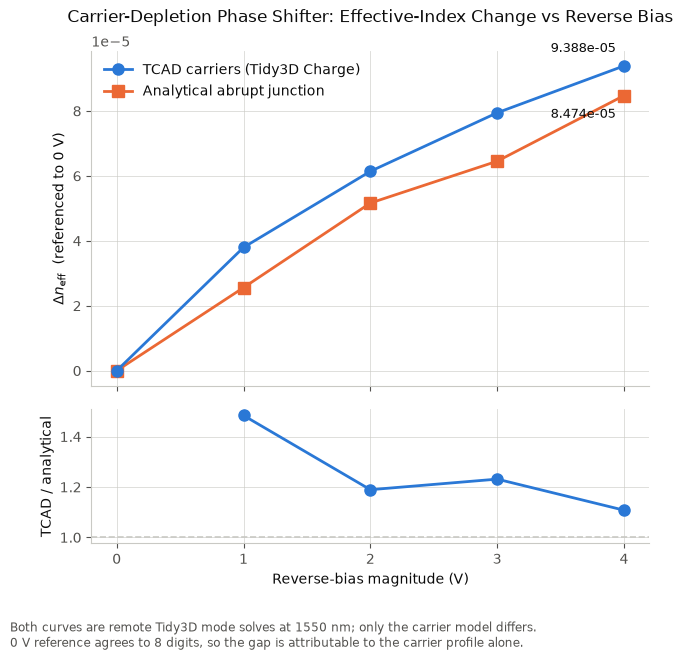

In [99]:
# Plot TCAD-derived vs analytical-carrier Delta n_eff against reverse bias, with a ratio panel.

import matplotlib.pyplot as plt

C_TCAD, C_ANA = "#2a78d6", "#eb6834"      # categorical slots 1 and 2
INK, INK2, GRID = "#0b0b0b", "#52514e", "#c9c9c4"

vl = list(voltages)
rb = np.array([abs(float(V)) for V in V_list])
ana_arr = np.array([float(delta_neff_vs_voltage[vl.index(V)]) for V in V_list])
ratio = np.where(ana_arr != 0, dneff_tcad_arr / np.where(ana_arr == 0, 1, ana_arr), np.nan)

fig, (ax, axr) = plt.subplots(
    2, 1, figsize=(7.2, 6.4), sharex=True,
    gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.10},
)

ax.plot(rb, dneff_tcad_arr, marker="o", ms=8, lw=2, color=C_TCAD,
        label="TCAD carriers (Tidy3D Charge)", zorder=3)
ax.plot(rb, ana_arr, marker="s", ms=8, lw=2, color=C_ANA,
        label="Analytical abrupt junction", zorder=2)

# Selective direct labels: endpoint only, in ink rather than series color.
ax.annotate(f"{dneff_tcad_arr[-1]:.3e}", (rb[-1], dneff_tcad_arr[-1]),
            textcoords="offset points", xytext=(-6, 10), ha="right",
            fontsize=9, color=INK)
ax.annotate(f"{ana_arr[-1]:.3e}", (rb[-1], ana_arr[-1]),
            textcoords="offset points", xytext=(-6, -16), ha="right",
            fontsize=9, color=INK)

ax.set_ylabel(r"$\Delta n_{\mathrm{eff}}$  (referenced to 0 V)", color=INK)
ax.set_title("Carrier-Depletion Phase Shifter: Effective-Index Change vs Reverse Bias",
             color=INK, fontsize=12, pad=10)
ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=INK)
ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)

axr.plot(rb, ratio, marker="o", ms=8, lw=2, color=C_TCAD, zorder=3)
axr.axhline(1.0, color=GRID, lw=1.2, ls="--", zorder=1)
axr.set_ylabel("TCAD / analytical", color=INK, fontsize=10)
axr.set_xlabel("Reverse-bias magnitude (V)", color=INK)
axr.grid(True, color=GRID, lw=0.6, alpha=0.7)
axr.set_axisbelow(True)
axr.set_xticks(rb)

for a in (ax, axr):
    a.tick_params(colors=INK2)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        a.spines[side].set_color(GRID)

fig.text(0.012, -0.01,
         "Both curves are remote Tidy3D mode solves at 1550 nm; only the carrier model differs.\n"
         "0 V reference agrees to 8 digits, so the gap is attributable to the carrier profile alone.",
         fontsize=8.5, color=INK2, va="top")

fig.tight_layout()
plt.savefig("../Figures/PhaseB_delta_neff_TCAD_vs_analytical.png",
            dpi=300, bbox_inches="tight", facecolor="white")
plt.show()


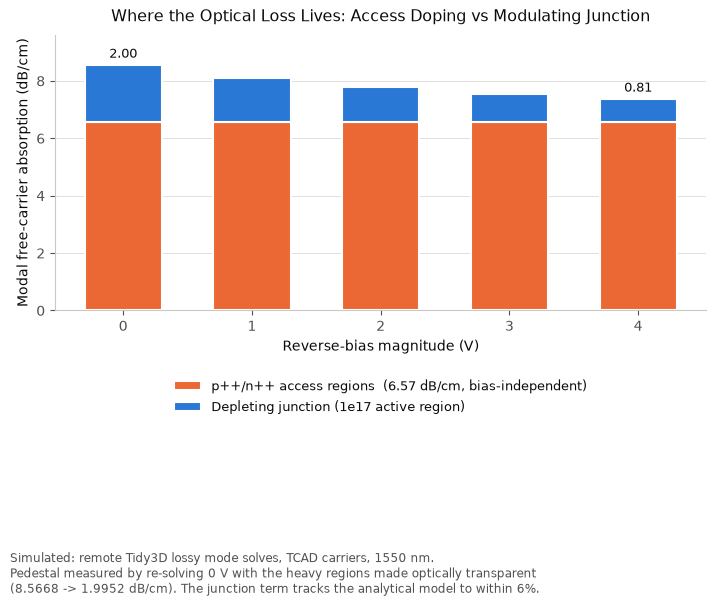

In [100]:
# Plot modal FCA as a stacked decomposition into the constant access pedestal and the depleting junction term.

C_ACCESS, C_JUNC = "#eb6834", "#2a78d6"      # categorical slots 2 and 1
INK, INK2, GRID = "#0b0b0b", "#52514e", "#c9c9c4"

rb = np.array([abs(float(V)) for V in V_list])
totals = np.array([modal_loss_tcad[V] for V in V_list])
junction = totals - pedestal

fig, ax = plt.subplots(figsize=(7.2, 4.8))

# edgecolor gives the 2 px surface gap between stacked segments.
ax.bar(rb, np.full_like(totals, pedestal), width=0.6, color=C_ACCESS,
       edgecolor="white", linewidth=1.5, zorder=3,
       label=f"p++/n++ access regions  ({pedestal:.2f} dB/cm, bias-independent)")
ax.bar(rb, junction, bottom=pedestal, width=0.6, color=C_JUNC,
       edgecolor="white", linewidth=1.5, zorder=3,
       label="Depleting junction (1e17 active region)")

# Selective direct labels: the two endpoints of the varying term only.
for i in (0, len(rb) - 1):
    ax.annotate(f"{junction[i]:.2f}", (rb[i], pedestal + junction[i]),
                textcoords="offset points", xytext=(0, 5), ha="center",
                fontsize=9, color=INK, zorder=4)

ax.set_xlabel("Reverse-bias magnitude (V)", color=INK)
ax.set_ylabel("Modal free-carrier absorption (dB/cm)", color=INK)
ax.set_title("Where the Optical Loss Lives: Access Doping vs Modulating Junction",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower center", fontsize=9.5, labelcolor=INK,
          bbox_to_anchor=(0.5, -0.42))
ax.set_xticks(rb)
ax.set_ylim(0, totals.max() * 1.12)
ax.grid(True, axis="y", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)

fig.text(0.012, -0.16,
         "Simulated: remote Tidy3D lossy mode solves, TCAD carriers, 1550 nm.\n"
         "Pedestal measured by re-solving 0 V with the heavy regions made optically transparent\n"
         "(8.5668 -> 1.9952 dB/cm). The junction term tracks the analytical model to within 6%.",
         fontsize=8.5, color=INK2, va="top")

fig.tight_layout()
plt.savefig("../Figures/PhaseB_loss_decomposition.png",
            dpi=300, bbox_inches="tight", facecolor="white")
plt.show()


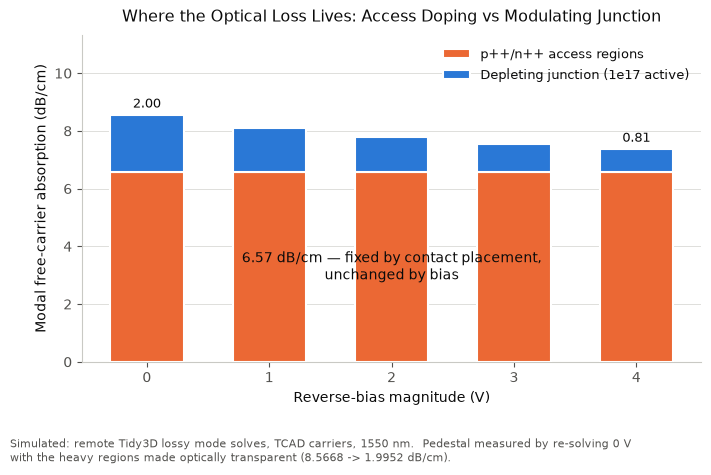

In [101]:
# Plot modal FCA as a stacked decomposition into the constant access pedestal and the depleting junction term.

C_ACCESS, C_JUNC = "#eb6834", "#2a78d6"      # categorical slots 2 and 1
INK, INK2, GRID = "#0b0b0b", "#52514e", "#c9c9c4"

rb = np.array([abs(float(V)) for V in V_list])
totals = np.array([modal_loss_tcad[V] for V in V_list])
junction = totals - pedestal

fig, ax = plt.subplots(figsize=(7.2, 4.8))

# edgecolor gives the 2 px surface gap between stacked segments.
ax.bar(rb, np.full_like(totals, pedestal), width=0.6, color=C_ACCESS,
       edgecolor="white", linewidth=1.5, zorder=3, label="p++/n++ access regions")
ax.bar(rb, junction, bottom=pedestal, width=0.6, color=C_JUNC,
       edgecolor="white", linewidth=1.5, zorder=3,
       label="Depleting junction (1e17 active)")

# Direct label on the constant floor, rather than burying the number in the legend.
ax.text(rb.mean(), pedestal / 2,
        f"{pedestal:.2f} dB/cm — fixed by contact placement,\nunchanged by bias",
        ha="center", va="center", fontsize=10, color=INK, zorder=4)

# Selective direct labels: the two endpoints of the varying term only.
for i in (0, len(rb) - 1):
    ax.annotate(f"{junction[i]:.2f}", (rb[i], pedestal + junction[i]),
                textcoords="offset points", xytext=(0, 5), ha="center",
                fontsize=9, color=INK, zorder=4)

ax.set_xlabel("Reverse-bias magnitude (V)", color=INK)
ax.set_ylabel("Modal free-carrier absorption (dB/cm)", color=INK)
ax.set_title("Where the Optical Loss Lives: Access Doping vs Modulating Junction",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="upper right", fontsize=9.5, labelcolor=INK)
ax.set_xticks(rb)
ax.set_ylim(0, totals.max() * 1.32)
ax.grid(True, axis="y", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)

fig.text(0.01, 0.005,
         "Simulated: remote Tidy3D lossy mode solves, TCAD carriers, 1550 nm.  Pedestal measured by "
         "re-solving 0 V\nwith the heavy regions made optically transparent (8.5668 -> 1.9952 dB/cm).",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.22)
plt.savefig("../Figures/PhaseB_loss_decomposition.png", dpi=300, facecolor="white")
plt.show()


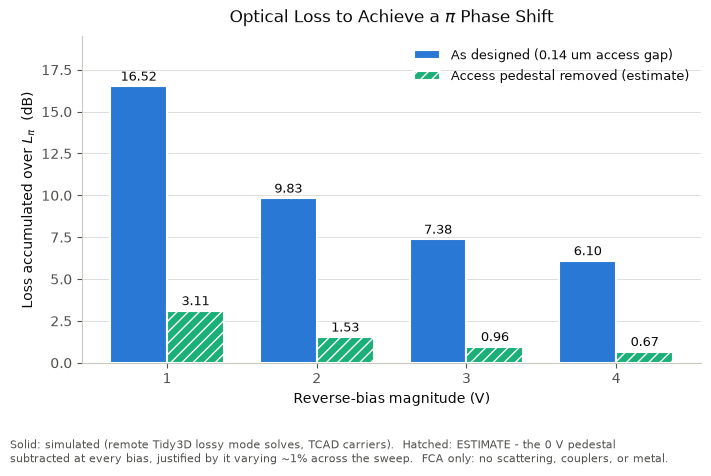

In [102]:
# Plot optical loss accumulated over Lpi, as designed versus with the access pedestal removed.

C_ASBUILT, C_EST = "#2a78d6", "#1baf7a"      # categorical slots 1 and 3
INK, INK2, GRID = "#0b0b0b", "#52514e", "#c9c9c4"

Vb = [V for V in V_list if V != 0]
idx = [list(V_list).index(V) for V in Vb]
rb_b = np.array([abs(float(V)) for V in Vb])
Lpi_cm = np.array([Lpi_tcad[i] * 1e-4 for i in idx])
loss_built = np.array([modal_loss_tcad[V] for V in Vb]) * Lpi_cm
loss_est = (np.array([modal_loss_tcad[V] for V in Vb]) - pedestal) * Lpi_cm

x = np.arange(len(Vb))
w = 0.38
fig, ax = plt.subplots(figsize=(7.2, 4.8))

b1 = ax.bar(x - w / 2, loss_built, width=w, color=C_ASBUILT, edgecolor="white",
            linewidth=1.5, zorder=3, label="As designed (0.14 um access gap)")
b2 = ax.bar(x + w / 2, loss_est, width=w, color=C_EST, edgecolor="white",
            linewidth=1.5, hatch="///", zorder=3,
            label="Access pedestal removed (estimate)")

# Relief rule: the aqua slot sits below 3:1 on a light surface, so every bar is labeled.
for bars, vals in ((b1, loss_built), (b2, loss_est)):
    for bar, v in zip(bars, vals):
        ax.annotate(f"{v:.2f}", (bar.get_x() + bar.get_width() / 2, v),
                    textcoords="offset points", xytext=(0, 4), ha="center",
                    fontsize=9, color=INK, zorder=4)

ax.set_xticks(x, [f"{int(v)}" for v in rb_b])
ax.set_xlabel("Reverse-bias magnitude (V)", color=INK)
ax.set_ylabel(r"Loss accumulated over $L_\pi$  (dB)", color=INK)
ax.set_title(r"Optical Loss to Achieve a $\pi$ Phase Shift", color=INK, fontsize=12, pad=10)
ax.legend(frameon=False, loc="upper right", fontsize=9.5, labelcolor=INK)
ax.set_ylim(0, loss_built.max() * 1.18)
ax.grid(True, axis="y", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)

fig.text(0.01, 0.005,
         "Solid: simulated (remote Tidy3D lossy mode solves, TCAD carriers).  Hatched: ESTIMATE - the "
         "0 V pedestal\nsubtracted at every bias, justified by it varying ~1% across the sweep.  "
         "FCA only: no scattering, couplers, or metal.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.22)
plt.savefig("../Figures/PhaseB_loss_over_Lpi.png", dpi=300, facecolor="white")
plt.show()


In [103]:
# Inspect the transport models Tidy3D actually uses in si_charge before building any resistance model.

def show(obj, indent=1, maxdepth=3):
    pad = "  " * indent
    names = list(getattr(obj, "model_fields", None) or getattr(obj, "__fields__", {}) or {})
    if not names:
        print(f"{pad}(no introspectable fields; repr = {repr(obj)[:80]})")
        return
    for n in names:
        try:
            v = getattr(obj, n)
        except Exception as e:
            print(f"{pad}{n:<26} <unreadable: {e}>")
            continue
        if hasattr(v, "model_fields") or hasattr(v, "__fields__"):
            print(f"{pad}{n:<26} {type(v).__name__}")
            if indent < maxdepth:
                show(v, indent + 1, maxdepth)
        else:
            print(f"{pad}{n:<26} {repr(v)[:88]}")

print(f"si_charge : {type(si_charge).__name__}")
show(si_charge)

print(f"\nq  = {td.constants.ELEMENTARY_CHARGE if hasattr(td.constants,'ELEMENTARY_CHARGE') else 'check name'}")
print(f"doping regions on si_charge: N_a={len(si_charge.N_a)}, N_d={len(si_charge.N_d)}")


si_charge : SemiconductorMedium
  attrs                      {}
  name                       'Si_PN_phase_shifter'
  frequency_range            None
  allow_gain                 False
  nonlinear_spec             None
  modulation_spec            None
  viz_spec                   None
  heat_spec                  None
  type                       'SemiconductorMedium'
  permittivity               11.7
  N_c                        ConstantEffectiveDOS
    attrs                      {}
    type                       'ConstantEffectiveDOS'
    N                          2.86e+19
  N_v                        ConstantEffectiveDOS
    attrs                      {}
    type                       'ConstantEffectiveDOS'
    N                          3.1e+19
  E_g                        ConstantEnergyBandGap
    attrs                      {}
    eg                         1.11
    type                       'ConstantEnergyBandGap'
  electron_affinity          None
  richardson_electron        N

C:\Users\ericc\AppData\Local\Temp\ipykernel_34524\75475685.py:5: PydanticDeprecatedSince211: Accessing the 'model_fields' attribute on the instance is deprecated. Instead, you should access this attribute from the model class. Deprecated in Pydantic V2.11 to be removed in V3.0.
  names = list(getattr(obj, "model_fields", None) or getattr(obj, "__fields__", {}) or {})
C:\Users\ericc\AppData\Local\Temp\ipykernel_34524\75475685.py:15: PydanticDeprecatedSince211: Accessing the 'model_fields' attribute on the instance is deprecated. Instead, you should access this attribute from the model class. Deprecated in Pydantic V2.11 to be removed in V3.0.
  if hasattr(v, "model_fields") or hasattr(v, "__fields__"):


mobility check (cm^2/V/s), against published silicon values
  N = 1e+17:  mu_n =   753.8   mu_p =   317.4
  N = 1e+19:  mu_n =   110.3   mu_p =    70.8

V = +0 V:  min G near junction = 1.342e-10 S at y = +0.048 um
           G in heavy region (|y|=0.6) = 1.619e-03 S

V = -4 V:  min G near junction = 6.189e-19 S at y = +0.050 um
           G in heavy region (|y|=0.6) = 1.619e-03 S


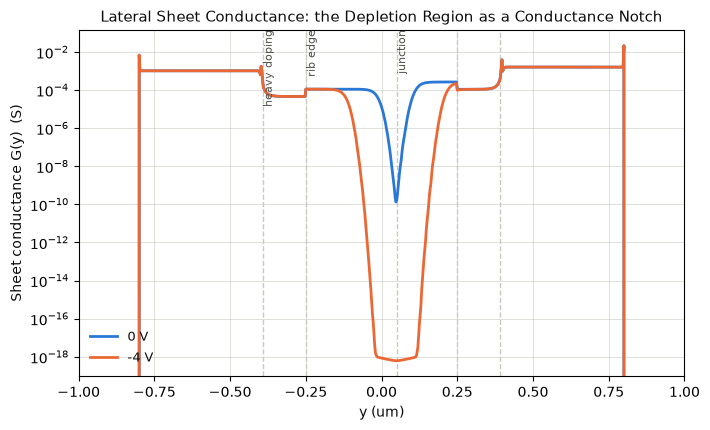

In [104]:
# Build doping-dependent conductivity from TCAD carriers and plot sheet conductance vs y to locate the depletion region.

from tidy3d.constants import Q_e

# Reconstruct the doping map on the optical grid directly from the ConstantDoping boxes on si_charge.
Y2, Z2 = np.meshgrid(y_opt, z_opt, indexing="ij")      # (y, z) -- matches the TCAD array orientation

def doping_map(regions):
    M = np.zeros_like(Y2, dtype=float)
    for r in regions:
        cy, cz, sy, sz = r.center[1], r.center[2], r.size[1], r.size[2]
        M += np.where((np.abs(Y2 - cy) <= sy / 2) & (np.abs(Z2 - cz) <= sz / 2),
                      float(r.concentration), 0.0)
    return M

N_total = doping_map(si_charge.N_a) + doping_map(si_charge.N_d)   # model uses TOTAL doping

def caughey_thomas(N, m):
    """Low-field mobility at 300 K; every temperature factor is unity at T_ref = 300 K."""
    return m.mu_min + (m.mu - m.mu_min) / (1.0 + (N / m.ref_N) ** m.exp_N)

mu_n = caughey_thomas(N_total, si_charge.mobility_n)
mu_p = caughey_thomas(N_total, si_charge.mobility_p)

print("mobility check (cm^2/V/s), against published silicon values")
for Nc in (1e17, 1e19):
    print(f"  N = {Nc:.0e}:  mu_n = {caughey_thomas(Nc, si_charge.mobility_n):7.1f}"
          f"   mu_p = {caughey_thomas(Nc, si_charge.mobility_p):7.1f}")

# Sheet conductance G(y) = integral of sigma over z.  sigma [S/cm] * dz [cm] -> S.
dz_cm = float(z_opt[1] - z_opt[0]) * 1e-4
G = {}
for V in V_list:
    sigma = Q_e * (mu_n * N_tcad[V].astype(np.float64)
                   + mu_p * P_tcad[V].astype(np.float64))     # S/cm
    G[V] = sigma.sum(axis=1) * dz_cm                          # S, one value per y

for V in (0, -4):
    g = G[V]
    core = np.abs(y_opt) < 0.35
    print(f"\nV = {V:+d} V:  min G near junction = {g[core].min():.3e} S "
          f"at y = {y_opt[core][np.argmin(g[core])]:+.3f} um")
    print(f"           G in heavy region (|y|=0.6) = {g[np.argmin(np.abs(y_opt - 0.6))]:.3e} S")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.semilogy(y_opt, G[0], lw=2, color="#2a78d6", label="0 V")
ax.semilogy(y_opt, G[-4], lw=2, color="#eb6834", label="-4 V")
for yv, lab in ((0.05, "junction"), (-0.25, "rib edge"), (0.25, None),
                (-0.392, "heavy doping"), (0.392, None)):
    ax.axvline(yv, color="#c9c9c4", lw=1, ls="--", zorder=1)
    if lab:
        ax.text(yv, ax.get_ylim()[1], f" {lab}", fontsize=8, color="#52514e",
                rotation=90, va="top")
ax.set_xlabel("y (um)", color="#0b0b0b")
ax.set_ylabel("Sheet conductance G(y)  (S)", color="#0b0b0b")
ax.set_title("Lateral Sheet Conductance: the Depletion Region as a Conductance Notch",
             color="#0b0b0b", fontsize=11)
ax.legend(frameon=False, fontsize=9.5, labelcolor="#0b0b0b")
ax.set_xlim(-1.0, 1.0)
ax.grid(True, color="#c9c9c4", lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


In [106]:
# Extract series access resistance by integrating 1/G(y) over quasi-neutral silicon, sweeping the depletion threshold.

# Conductance each column would have if fully quasi-neutral (majority carriers equal to the local doping).
NA_map, ND_map = doping_map(si_charge.N_a), doping_map(si_charge.N_d)
G_ref = (Q_e * (mu_n * ND_map + mu_p * NA_map)).sum(axis=1) * dz_cm
G_ref = np.where(G_ref > 0, G_ref, np.nan)

Y_JUNC = 0.05
Y_CONTACT_INNER = 0.50        # inner edge of the 0.20 um contact centred at 0.60 um (handoff 13E)
dy_cm = float(y_opt[1] - y_opt[0]) * 1e-4

def access_RL(V, f):
    """R*L in ohm-cm, plus the two depletion edges, for depletion threshold f."""
    with np.errstate(invalid="ignore"):
        conducting = (G[V] / G_ref) >= f
    reach = np.abs(y_opt) <= Y_CONTACT_INNER
    p = conducting & reach & (y_opt < Y_JUNC)
    n = conducting & reach & (y_opt > Y_JUNC)
    RL_p = np.sum(dy_cm / G[V][p]) if p.any() else np.nan
    RL_n = np.sum(dy_cm / G[V][n]) if n.any() else np.nan
    return RL_p + RL_n, (y_opt[p].max() if p.any() else np.nan,
                         y_opt[n].min() if n.any() else np.nan)

thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]
print("Series access resistance R*L (ohm-cm) vs depletion threshold f = G/G_ref")
print(f"{'V':>4} " + "".join(f"{('f='+str(f)):>12}" for f in thresholds) + f"{'spread':>10}")
for V in V_list:
    row = [access_RL(V, f)[0] for f in thresholds]
    spread = (max(row) - min(row)) / np.mean(row)
    print(f"{V:>+4.0f} " + "".join(f"{r:>12.4f}" for r in row) + f"{100*spread:>9.1f}%")

print("\nDepletion edges at f = 0.5, against the analytical abrupt-junction prediction:")
for V in V_list:
    _, (yp, yn) = access_RL(V, 0.5)
    W = (yn - yp) if np.isfinite(yp) and np.isfinite(yn) else np.nan
    print(f"  V = {V:>+3.0f} V : p-edge {yp:+.3f}  n-edge {yn:+.3f} um   W_depl = {W:.3f} um")

print("\nImplied lumped resistance at f = 0.5:")
for i, V in enumerate(V_list):
    if V == 0:
        continue
    RL, _ = access_RL(V, 0.5)
    Lcm = Lpi_tcad[list(V_list).index(V)] * 1e-4
    print(f"  V = {V:>+3.0f} V : R*L = {RL:7.4f} ohm-cm  ->  R = {RL / Lcm:7.2f} ohm over Lpi = {Lcm*10:.2f} mm")


Series access resistance R*L (ohm-cm) vs depletion threshold f = G/G_ref
   V        f=0.1       f=0.3       f=0.5       f=0.7       f=0.9    spread
  +0       0.7950      0.7203      0.3309      0.2826      0.2486    114.9%
  -1       0.7495      0.6704      0.2844      0.2380      0.2011    127.9%
  -2       0.7099      0.6344      0.2535      0.2029      0.1662    138.2%
  -3       0.6816      0.6056      0.2247      0.1743      0.1377    149.1%
  -4       0.6719      0.5803      0.1988      0.1486      0.1129    163.2%

Depletion edges at f = 0.5, against the analytical abrupt-junction prediction:
  V =  +0 V : p-edge -0.020  n-edge +0.120 um   W_depl = 0.140 um
  V =  -1 V : p-edge -0.057  n-edge +0.155 um   W_depl = 0.213 um
  V =  -2 V : p-edge -0.083  n-edge +0.183 um   W_depl = 0.265 um
  V =  -3 V : p-edge -0.105  n-edge +0.205 um   W_depl = 0.310 um
  V =  -4 V : p-edge -0.125  n-edge +0.225 um   W_depl = 0.350 um

Implied lumped resistance at f = 0.5:
  V =  -1 V : R*L =  0

In [107]:
# Decompose access resistance by side and y-segment to find the dominant term and its threshold sensitivity.

def seg_RL(V, y_lo, y_hi, f=0.5):
    """R*L contribution (ohm-cm) from the conducting part of a y-interval."""
    with np.errstate(invalid="ignore"):
        ok = (G[V] / G_ref) >= f
    m = ok & (y_opt >= y_lo) & (y_opt <= y_hi)
    return float(np.sum(dy_cm / G[V][m])) if m.any() else 0.0

segs = [
    ("n heavy slab   +0.40..+0.50", 0.40, 0.50),
    ("n light slab   +0.25..+0.40", 0.25, 0.40),
    ("n rib shoulder +0.05..+0.25", 0.05, 0.25),
    ("p rib shoulder -0.25..+0.05", -0.25, 0.05),
    ("p light slab   -0.40..-0.25", -0.40, -0.25),
    ("p heavy slab   -0.50..-0.40", -0.50, -0.40),
]

V_show = -4
print(f"R*L decomposition at V = {V_show} V, f = 0.5   (ohm-cm)\n")
tot = 0.0
for name, lo, hi in segs:
    v = seg_RL(V_show, lo, hi)
    tot += v
    print(f"  {name:<30} {v:9.4f}")
print(f"  {'total':<30} {tot:9.4f}")

nside = sum(seg_RL(V_show, lo, hi) for _, lo, hi in segs if lo >= 0.05)
pside = sum(seg_RL(V_show, lo, hi) for _, lo, hi in segs if hi <= 0.05)
print(f"\n  n-side {nside:.4f}   p-side {pside:.4f}   p/n = {pside / nside:.2f}")
print(f"  mu_n/mu_p at 1e17 = "
      f"{caughey_thomas(1e17, si_charge.mobility_n) / caughey_thomas(1e17, si_charge.mobility_p):.2f}")

print(f"\nthreshold sensitivity by segment (f = 0.1 -> 0.9):")
for name, lo, hi in segs:
    print(f"  {name:<30} {seg_RL(V_show, lo, hi, 0.1):9.4f} -> {seg_RL(V_show, lo, hi, 0.9):9.4f}")

# Independent hand check of the expected dominant term.
mu_n17 = caughey_thomas(1e17, si_charge.mobility_n)
G_slab_n = Q_e * mu_n17 * 1e17 * (slab_height * 1e-4)
print(f"\nhand check, n light slab: G = {G_slab_n:.3e} S over 0.15 um "
      f"-> R*L = {0.15e-4 / G_slab_n:.4f} ohm-cm")


R*L decomposition at V = -4 V, f = 0.5   (ohm-cm)

  n heavy slab   +0.40..+0.50       0.0065
  n light slab   +0.25..+0.40       0.0134
  n rib shoulder +0.05..+0.25       0.0135
  p rib shoulder -0.25..+0.05       0.1243
  p light slab   -0.40..-0.25       0.0337
  p heavy slab   -0.50..-0.40       0.0101
  total                             0.2014

  n-side 0.0334   p-side 0.1681   p/n = 5.03
  mu_n/mu_p at 1e17 = 2.37

threshold sensitivity by segment (f = 0.1 -> 0.9):
  n heavy slab   +0.40..+0.50       0.0065 ->    0.0057
  n light slab   +0.25..+0.40       0.1221 ->    0.0025
  n rib shoulder +0.05..+0.25       0.0493 ->    0.0000
  p rib shoulder -0.25..+0.05       0.2064 ->    0.0902
  p light slab   -0.40..-0.25       0.2827 ->    0.0076
  p heavy slab   -0.50..-0.40       0.0101 ->    0.0091

hand check, n light slab: G = 1.087e-04 S over 0.15 um -> R*L = 0.1380 ohm-cm


In [108]:
# Extract series access resistance by integrating 1/G(y) over quasi-neutral silicon, sweeping the depletion threshold.

# G_ref MUST be masked to real silicon: the active doping boxes span z = 0..0.22 um even where only the
# 90 nm slab exists, which inflates G_ref by 220/90 and wrongly excludes the slab at f >= 0.5.
NA_map = np.where(silicon_mask_opt, doping_map(si_charge.N_a), 0.0)
ND_map = np.where(silicon_mask_opt, doping_map(si_charge.N_d), 0.0)
G_ref = (Q_e * (mu_n * ND_map + mu_p * NA_map)).sum(axis=1) * dz_cm
G_ref = np.where(G_ref > 0, G_ref, np.nan)

# Self-check: in quasi-neutral 1e17 n slab, G_ref must match the hand value and G/G_ref must be ~1.
i_chk = int(np.argmin(np.abs(y_opt - 0.32)))
G_hand = Q_e * caughey_thomas(1e17, si_charge.mobility_n) * 1e17 * (slab_height * 1e-4)
print(f"G_ref check at y = {y_opt[i_chk]:+.3f} um (1e17 n slab):")
print(f"  G_ref = {G_ref[i_chk]:.3e} S   hand = {G_hand:.3e} S   ratio = {G_ref[i_chk] / G_hand:.3f}")
print(f"  G(0 V)/G_ref = {G[0][i_chk] / G_ref[i_chk]:.3f}  (should be ~1 in quasi-neutral silicon)\n")

Y_JUNC = 0.05
Y_CONTACT_INNER = 0.50        # inner edge of the 0.20 um contact centred at 0.60 um (handoff 13E)
dy_cm = float(y_opt[1] - y_opt[0]) * 1e-4

def access_RL(V, f):
    """R*L in ohm-cm, plus the two depletion edges, for depletion threshold f."""
    with np.errstate(invalid="ignore"):
        conducting = (G[V] / G_ref) >= f
    reach = np.abs(y_opt) <= Y_CONTACT_INNER
    p = conducting & reach & (y_opt < Y_JUNC)
    n = conducting & reach & (y_opt > Y_JUNC)
    RL_p = np.sum(dy_cm / G[V][p]) if p.any() else np.nan
    RL_n = np.sum(dy_cm / G[V][n]) if n.any() else np.nan
    return RL_p + RL_n, (y_opt[p].max() if p.any() else np.nan,
                         y_opt[n].min() if n.any() else np.nan)

thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]
print("Series access resistance R*L (ohm-cm) vs depletion threshold f = G/G_ref")
print(f"{'V':>4} " + "".join(f"{('f=' + str(f)):>12}" for f in thresholds) + f"{'spread':>10}")
for V in V_list:
    row = [access_RL(V, f)[0] for f in thresholds]
    spread = (max(row) - min(row)) / np.mean(row)
    print(f"{V:>+4.0f} " + "".join(f"{r:>12.4f}" for r in row) + f"{100 * spread:>9.1f}%")

print("\nDepletion edges at f = 0.5, against the analytical abrupt-junction prediction:")
for V in V_list:
    _, (yp, yn) = access_RL(V, 0.5)
    W = (yn - yp) if np.isfinite(yp) and np.isfinite(yn) else np.nan
    print(f"  V = {V:>+3.0f} V : p-edge {yp:+.3f}  n-edge {yn:+.3f} um   W_depl = {W:.3f} um")

print("\nImplied lumped resistance at f = 0.5:")
for V in V_list:
    if V == 0:
        continue
    RL, _ = access_RL(V, 0.5)
    Lcm = Lpi_tcad[list(V_list).index(V)] * 1e-4
    print(f"  V = {V:>+3.0f} V : R*L = {RL:7.4f} ohm-cm  ->  R = {RL / Lcm:7.2f} ohm over Lpi = {Lcm * 10:.2f} mm")


G_ref check at y = +0.320 um (1e17 n slab):
  G_ref = 1.099e-04 S   hand = 1.087e-04 S   ratio = 1.011
  G(0 V)/G_ref = 1.004  (should be ~1 in quasi-neutral silicon)

Series access resistance R*L (ohm-cm) vs depletion threshold f = G/G_ref
   V        f=0.1       f=0.3       f=0.5       f=0.7       f=0.9    spread
  +0       0.7950      0.7203      0.6848      0.6649      0.6397     22.1%
  -1       0.7495      0.6704      0.6383      0.6202      0.5922     24.0%
  -2       0.7099      0.6344      0.6075      0.5852      0.5574     24.6%
  -3       0.6816      0.6056      0.5789      0.5568      0.5291     25.8%
  -4       0.6719      0.5803      0.5540      0.5321      0.5053     29.3%

Depletion edges at f = 0.5, against the analytical abrupt-junction prediction:
  V =  +0 V : p-edge -0.020  n-edge +0.120 um   W_depl = 0.140 um
  V =  -1 V : p-edge -0.057  n-edge +0.155 um   W_depl = 0.213 um
  V =  -2 V : p-edge -0.083  n-edge +0.183 um   W_depl = 0.265 um
  V =  -3 V : p-edge -0.1

In [109]:
# Decompose the corrected access resistance by side and y-segment, with a hand check on the dominant term.

def seg_RL(V, y_lo, y_hi, f=0.5):
    """R*L contribution (ohm-cm) from the conducting part of a y-interval."""
    with np.errstate(invalid="ignore"):
        ok = (G[V] / G_ref) >= f
    m = ok & (y_opt >= y_lo) & (y_opt <= y_hi)
    return float(np.sum(dy_cm / G[V][m])) if m.any() else 0.0

segs = [
    ("n heavy slab   +0.40..+0.50", 0.40, 0.50),
    ("n light slab   +0.25..+0.40", 0.25, 0.40),
    ("n rib shoulder +0.05..+0.25", 0.05, 0.25),
    ("p rib shoulder -0.25..+0.05", -0.25, 0.05),
    ("p light slab   -0.40..-0.25", -0.40, -0.25),
    ("p heavy slab   -0.50..-0.40", -0.50, -0.40),
]

V_show = -4
print(f"R*L decomposition at V = {V_show} V, f = 0.5   (ohm-cm)\n")
tot = 0.0
for name, lo, hi in segs:
    v = seg_RL(V_show, lo, hi)
    tot += v
    print(f"  {name:<30} {v:9.4f}")
print(f"  {'total':<30} {tot:9.4f}")

light = sum(seg_RL(V_show, lo, hi) for name, lo, hi in segs if "light" in name)
print(f"\n  lightly doped gap total {light:.4f}  = {100 * light / tot:.0f}% of series resistance")

nside = sum(seg_RL(V_show, lo, hi) for _, lo, hi in segs if lo >= 0.05)
pside = sum(seg_RL(V_show, lo, hi) for _, lo, hi in segs if hi <= 0.05)
print(f"  n-side {nside:.4f}   p-side {pside:.4f}   p/n = {pside / nside:.2f}"
      f"   (mu_n/mu_p at 1e17 = "
      f"{caughey_thomas(1e17, si_charge.mobility_n) / caughey_thomas(1e17, si_charge.mobility_p):.2f})")

print(f"\nthreshold sensitivity by segment (f = 0.1 -> 0.9):")
for name, lo, hi in segs:
    print(f"  {name:<30} {seg_RL(V_show, lo, hi, 0.1):9.4f} -> {seg_RL(V_show, lo, hi, 0.9):9.4f}")

mu_n17 = caughey_thomas(1e17, si_charge.mobility_n)
G_slab_n = Q_e * mu_n17 * 1e17 * (slab_height * 1e-4)
print(f"\nhand check, n light slab: G = {G_slab_n:.3e} S over 0.15 um "
      f"-> R*L = {0.15e-4 / G_slab_n:.4f} ohm-cm")


R*L decomposition at V = -4 V, f = 0.5   (ohm-cm)

  n heavy slab   +0.40..+0.50       0.0065
  n light slab   +0.25..+0.40       0.1196
  n rib shoulder +0.05..+0.25       0.0135
  p rib shoulder -0.25..+0.05       0.1243
  p light slab   -0.40..-0.25       0.2827
  p heavy slab   -0.50..-0.40       0.0101
  total                             0.5566

  lightly doped gap total 0.4023  = 72% of series resistance
  n-side 0.1396   p-side 0.4170   p/n = 2.99   (mu_n/mu_p at 1e17 = 2.37)

threshold sensitivity by segment (f = 0.1 -> 0.9):
  n heavy slab   +0.40..+0.50       0.0065 ->    0.0060
  n light slab   +0.25..+0.40       0.1221 ->    0.1196
  n rib shoulder +0.05..+0.25       0.0493 ->    0.0000
  p rib shoulder -0.25..+0.05       0.2064 ->    0.0902
  p light slab   -0.40..-0.25       0.2827 ->    0.2823
  p heavy slab   -0.50..-0.40       0.0101 ->    0.0094

hand check, n light slab: G = 1.087e-04 S over 0.15 um -> R*L = 0.1380 ohm-cm


In [110]:
# Combine TCAD capacitance with the extracted access resistance to get intrinsic and lumped-electrode bandwidth.

# SteadyCapacitanceData is in fF/um, which is identically pF/mm.
C_tcad = {float(v): float(c) for v, c in zip(cap_data.hole_capacitance.v.values,
                                             cap_data.hole_capacitance.values)}

RL    = {V: access_RL(V, 0.5)[0] for V in V_list}      # ohm-cm, nominal
RL_hi = {V: access_RL(V, 0.1)[0] for V in V_list}      # loosest threshold -> highest R
RL_lo = {V: access_RL(V, 0.9)[0] for V in V_list}

print("Intrinsic junction RC -- length-independent, since tau = (R*L)(C/L)")
print(f"{'V':>4} {'R*L':>9} {'C/L':>9} {'tau':>8} {'f_3dB':>9}   {'f_3dB band (GHz)':>18}")
print(f"{'':>4} {'ohm.cm':>9} {'pF/mm':>9} {'ps':>8} {'GHz':>9}")
for V in V_list:
    CpL = C_tcad[float(V)] * 1e-11                      # pF/mm -> F/cm
    tau = RL[V] * CpL
    f_lo = 1 / (2 * np.pi * RL_hi[V] * CpL) / 1e9
    f_hi = 1 / (2 * np.pi * RL_lo[V] * CpL) / 1e9
    print(f"{V:>+4.0f} {RL[V]:>9.4f} {C_tcad[float(V)]:>9.4f} {tau * 1e12:>8.3f} "
          f"{1 / (2 * np.pi * tau) / 1e9:>9.0f}   {f_lo:>8.0f} - {f_hi:<8.0f}")

# Lumped electrode driven from a real source.  R_SRC is an ASSUMPTION, not a simulated value.
R_SRC = 50.0
V_op = -4
i_op = list(V_list).index(V_op)
CpL_mm, RLc = C_tcad[float(V_op)], RL[V_op]
dphi_mm, loss_cm = phase_per_mm_tcad[i_op], modal_loss_tcad[V_op]

print(f"\nLumped electrode at {V_op} V, {R_SRC:.0f} ohm source")
print(f"{'L':>7} {'C_tot':>9} {'R_ser':>8} {'f_3dB':>9} {'phase':>9} {'loss':>8} {'frac of pi':>11}")
print(f"{'mm':>7} {'pF':>9} {'ohm':>8} {'GHz':>9} {'rad':>9} {'dB':>8}")
for L_mm in (0.25, 0.5, 1.0, 2.0, 4.0, Lpi_tcad[i_op] / 1000):
    C_tot = CpL_mm * L_mm * 1e-12
    R_ser = RLc / (L_mm * 0.1)
    f3 = 1 / (2 * np.pi * (R_SRC + R_ser) * C_tot)
    print(f"{L_mm:>7.2f} {C_tot * 1e12:>9.4f} {R_ser:>8.2f} {f3 / 1e9:>9.1f} "
          f"{dphi_mm * L_mm:>9.3f} {loss_cm * L_mm * 0.1:>8.2f} {dphi_mm * L_mm / np.pi:>11.3f}")


Intrinsic junction RC -- length-independent, since tau = (R*L)(C/L)
   V       R*L       C/L      tau     f_3dB     f_3dB band (GHz)
        ohm.cm     pF/mm       ps       GHz
  +0    0.6848    0.1296    0.888       179        154 - 192     
  -1    0.6383    0.1124    0.718       222        189 - 239     
  -2    0.6075    0.0871    0.529       301        257 - 328     
  -3    0.5789    0.0739    0.428       372        316 - 407     
  -4    0.5540    0.0688    0.381       417        344 - 458     

Lumped electrode at -4 V, 50 ohm source
      L     C_tot    R_ser     f_3dB     phase     loss  frac of pi
     mm        pF      ohm       GHz       rad       dB
   0.25    0.0172    22.16     128.1     0.095     0.18       0.030
   0.50    0.0344    11.08      75.7     0.190     0.37       0.061
   1.00    0.0688     5.54      41.6     0.381     0.74       0.121
   2.00    0.1377     2.77      21.9     0.761     1.48       0.242
   4.00    0.2754     1.39      11.2     1.522     2.95 

In [111]:
# Build a parameterized Charge simulation so the access gap can be swept, and verify it reproduces the baseline.

RIB_EDGE, HEAVY_W, CONTACT_W, Y_JUNC = rib_width / 2, access_width, 0.20, 0.05

def build_charge_sim(gap):
    """Charge sim whose heavy access doping starts `gap` um outside the rib edge."""
    h_in = RIB_EDGE + gap
    h_out = h_in + HEAVY_W
    slab_half = h_out
    dom_y = 2 * slab_half + 0.2

    p_act = td.ConstantDoping(center=(0, (-slab_half + Y_JUNC) / 2, si_height / 2),
                              size=(td.inf, slab_half + Y_JUNC, si_height),
                              concentration=NA_active)
    n_act = td.ConstantDoping(center=(0, (slab_half + Y_JUNC) / 2, si_height / 2),
                              size=(td.inf, slab_half - Y_JUNC, si_height),
                              concentration=ND_active)
    p_hvy = td.ConstantDoping(center=(0, -(h_in + HEAVY_W / 2), slab_height / 2),
                              size=(td.inf, HEAVY_W, slab_height), concentration=NA_heavy)
    n_hvy = td.ConstantDoping(center=(0, +(h_in + HEAVY_W / 2), slab_height / 2),
                              size=(td.inf, HEAVY_W, slab_height), concentration=ND_heavy)

    med = si_charge.updated_copy(N_a=[p_act, p_hvy], N_d=[n_act, n_hvy])
    slab = charge_slab.updated_copy(
        geometry=td.Box(center=(0, 0, slab_height / 2),
                        size=(td.inf, 2 * slab_half, slab_height)), medium=med)
    rib = charge_rib.updated_copy(medium=med)

    yc = h_in + HEAVY_W / 2                      # contact centred inside the heavy block
    pc_c, pc_s = p_contact.geometry.center, p_contact.geometry.size
    nc_c, nc_s = n_contact.geometry.center, n_contact.geometry.size
    pc = p_contact.updated_copy(geometry=td.Box(center=(pc_c[0], -yc, pc_c[2]), size=pc_s))
    nc = n_contact.updated_copy(geometry=td.Box(center=(nc_c[0], +yc, nc_c[2]), size=nc_s))

    return charge_sim.updated_copy(
        size=(0, dom_y, si_height),
        structures=[slab, rib, pc, nc],
        monitors=[carrier_monitor.updated_copy(size=(0, dom_y, si_height)),
                  capacitance_monitor.updated_copy(size=(0, dom_y, si_height))],
    )

# Validate the parameterization against the existing baseline geometry.
base = build_charge_sim(0.15)
print(f"{'quantity':<34}{'rebuilt':>14}{'existing':>14}")
print(f"{'domain y (um)':<34}{base.size[1]:>14.3f}{charge_sim.size[1]:>14.3f}")
for nm, sr, se in (("slab", base.structures[0], charge_sim.structures[0]),
                   ("p_contact", base.structures[2], charge_sim.structures[2]),
                   ("n_contact", base.structures[3], charge_sim.structures[3])):
    print(f"{nm + ' y-bounds (um)':<34}"
          f"{f'{sr.geometry.bounds[0][1]:+.3f}..{sr.geometry.bounds[1][1]:+.3f}':>14}"
          f"{f'{se.geometry.bounds[0][1]:+.3f}..{se.geometry.bounds[1][1]:+.3f}':>14}")

print("\ndoping regions (rebuilt at gap = 0.15):")
for lbl, regs in (("N_a", base.structures[0].medium.N_a), ("N_d", base.structures[0].medium.N_d)):
    for r in regs:
        lo, hi = r.center[1] - r.size[1] / 2, r.center[1] + r.size[1] / 2
        print(f"  {lbl}  y = {lo:+.3f}..{hi:+.3f}  z-size {r.size[2]:.3f}  N = {r.concentration:.1e}")

print(f"\ngap sweep preview (heavy inner edge, slab half-width, domain):")
for g in (0.15, 0.25, 0.35, 0.45):
    print(f"  gap {g:.2f} um -> heavy inner {RIB_EDGE + g:.2f}, "
          f"slab +/-{RIB_EDGE + g + HEAVY_W:.2f}, domain {2*(RIB_EDGE + g + HEAVY_W) + 0.2:.2f} um")


23:34:29 Central Daylight Time WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

quantity                                 rebuilt      existing
domain y (um)                              1.800         1.800
slab y-bounds (um)                -0.800..+0.800-0.800..+0.800
p_contact y-bounds (um)           -0.700..-0.500-0.700..-0.500
n_contact y-bounds (um)           +0.500..+0.700+0.500..+0.700

doping regions (rebuilt at gap = 0.15):
  N_a  y = -0.800..+0.050  z-size 0.220  N = 1.0e+17
  N_a  y = -0.800..-0.400  z-size 0.090  N = 1.0e+19
  N_d  y = +0.050..+0.800  z-size 0.220  N = 1.0e+17
  N_d  y = +0.400..+0.800  z-size 0.090  N = 1.0e+19

gap sweep preview (heavy inner edge, slab half-width, domain):
  gap 0.15 um -> heavy inner 0.40, slab +/-0.80, domain 1.80 um
  gap 0.25 um -> heavy inner 0.50, slab +/-0.90, domain 2.00 um
  gap 0.35 um -> heavy inner 0.60, slab +/-1.00, domain 2.20 um
  gap 0.45 um -> heavy inner 0.70, slab +/-1.10, domain 2.40 um


In [112]:
# Validate every access-gap Charge simulation, then run the remote DC bias sweeps only if all pass.

import tidy3d.web as web

gaps = [0.15, 0.25, 0.35, 0.45]
sims_gap, ok = {}, True

for g in gaps:
    sims_gap[g] = build_charge_sim(g)
    try:
        sims_gap[g].validate_pre_upload()
        status = "PASSED"
    except Exception as exc:
        status, ok = f"{type(exc).__name__}: {exc}", False
    print(f"gap {g:.2f} um | domain {sims_gap[g].size[1]:.2f} um | "
          f"mesh dl {sims_gap[g].grid_spec.dl} um | validate: {status}")

if not ok:
    print("\nABORTED - fix validation before spending credits.")
else:
    print(f"\nAll validations passed. Running {len(gaps)} multi-step Charge sweeps...\n")
    charge_data_gap, charge_cost = {}, {}
    for g in gaps:
        tag = f"{int(round(g * 1000))}nm"
        job = web.Job(simulation=sims_gap[g], task_name=f"PN_access_gap_{tag}",
                      folder_name="MZI_Modulator", verbose=True)
        charge_data_gap[g] = job.run(path=f"../Results/PN_charge_gap_{tag}.hdf5")
        try:
            charge_cost[g] = job.real_cost()
        except Exception as exc:
            charge_cost[g] = None
            print(f"  real_cost() unavailable: {type(exc).__name__}")
        print(f"  gap {g:.2f} um complete, cost = {charge_cost[g]}")

    print("\nTCAD capacitance (pF/mm), v = [-4,-3,-2,-1,0]:")
    for g in gaps:
        cap = charge_data_gap[g]["junction_capacitance"]
        print(f"  gap {g:.2f}: {np.round(np.array(cap.hole_capacitance.values), 5)}")
    spent = [c for c in charge_cost.values() if c]
    print(f"\ntotal cost: {sum(spent):.4f} FlexCredits" if spent else "\ncost unavailable")


23:35:30 Central Daylight Time WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

gap 0.15 um | domain 1.80 um | mesh dl 0.01 um | validate: PASSED


                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

...

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Warning messages were found in the      
                               solver log. For more information, check          
                               'SimulationData.log' or use                      
                               'web.download_log(task_id)'.                     

23:37:55 Central Daylight Time WARNING: Billed FlexCredit for task              
                               'hec-5703ea26-5b3d-40fa-8919-9ef29bc263ad' is not
                               available. If the task has been successfully run,
                               it should be available shortly.                  

                               Total billed flex credit cost: 0.025.

  gap 0.45 um complete, cost = 0.025

TCAD capacitance (pF/mm), v = [-4,-3,-2,-1,0]:
  gap 0.15: [0.06884 0.07389 0.08709 0.11243 0.1296 ]
  gap 0.25: [0.06884 0.07377 0.08682 0.11219 0.12943]
  gap 0.35: [0.0689  0.07392 0.08711 0.11248 0.12969]
  gap 0.45: [0.06875 0.07371 0.0868  0.11201 0.12909]

total cost: 0.1000 FlexCredits


In [113]:
# Interpolate carriers for each access gap and compute series resistance vs gap (no solver cost).

V_OP = -4
N_gap, P_gap, G_gap, RL_gap, edges_gap = {}, {}, {}, {}, {}

for g in gaps:
    cr = charge_data_gap[g]["carrier_distribution"]
    N_g = tcad_on_optical_grid(cr.electrons, V_OP)
    P_g = tcad_on_optical_grid(cr.holes, V_OP)
    N_gap[g], P_gap[g] = N_g, P_g

    # Doping and mobility read off the simulation that was actually solved, not re-typed.
    med = sims_gap[g].structures[0].medium
    NA_g = np.where(silicon_mask_opt, doping_map(med.N_a), 0.0)
    ND_g = np.where(silicon_mask_opt, doping_map(med.N_d), 0.0)
    Ntot = NA_g + ND_g
    mun = caughey_thomas(Ntot, si_charge.mobility_n)
    mup = caughey_thomas(Ntot, si_charge.mobility_p)

    G_gap[g] = (Q_e * (mun * N_g + mup * P_g)).sum(axis=1) * dz_cm
    Gref = (Q_e * (mun * ND_g + mup * NA_g)).sum(axis=1) * dz_cm
    Gref = np.where(Gref > 0, Gref, np.nan)

    y_cin = (RIB_EDGE + g + HEAVY_W / 2) - CONTACT_W / 2     # contact inner edge moves with the gap
    with np.errstate(invalid="ignore"):
        cond = (G_gap[g] / Gref) >= 0.5
    reach = np.abs(y_opt) <= y_cin
    p = cond & reach & (y_opt < Y_JUNC)
    n = cond & reach & (y_opt > Y_JUNC)
    RL_gap[g] = float(np.sum(dy_cm / G_gap[g][p]) + np.sum(dy_cm / G_gap[g][n]))
    edges_gap[g] = (float(y_opt[p].max()), float(y_opt[n].min()))

    print(f"gap {g:.2f} um | contact inner |y| {y_cin:.2f} | R*L {RL_gap[g]:7.4f} ohm-cm | "
          f"depletion edges {edges_gap[g][0]:+.3f} .. {edges_gap[g][1]:+.3f} um")

print(f"\nbaseline cross-check: gap 0.15 -> {RL_gap[0.15]:.4f} ohm-cm  (Phase C value 0.5540)")

print(f"\nbandwidth impact at {V_OP} V, 50 ohm source:")
print(f"{'gap':>6} {'R*L':>9} {'tau_int':>9} {'f_int':>8} {'f(1mm)':>9} {'f(8.26mm)':>11}")
for g in gaps:
    CpL = C_tcad[float(V_OP)] * 1e-11
    tau = RL_gap[g] * CpL
    f1 = 1 / (2 * np.pi * (50 + RL_gap[g] / 0.1) * (C_tcad[float(V_OP)] * 1e-12))
    f8 = 1 / (2 * np.pi * (50 + RL_gap[g] / 0.826) * (C_tcad[float(V_OP)] * 8.26e-12))
    print(f"{g:>6.2f} {RL_gap[g]:>9.4f} {tau * 1e12:>8.3f}p {1/(2*np.pi*tau)/1e9:>7.0f}G "
          f"{f1/1e9:>8.1f}G {f8/1e9:>10.1f}G")


gap 0.15 um | contact inner |y| 0.50 | R*L  0.5533 ohm-cm | depletion edges -0.125 .. +0.225 um
gap 0.25 um | contact inner |y| 0.60 | R*L  0.8621 ohm-cm | depletion edges -0.125 .. +0.228 um
gap 0.35 um | contact inner |y| 0.70 | R*L  1.1679 ohm-cm | depletion edges -0.125 .. +0.225 um
gap 0.45 um | contact inner |y| 0.80 | R*L  1.4759 ohm-cm | depletion edges -0.125 .. +0.225 um

baseline cross-check: gap 0.15 -> 0.5533 ohm-cm  (Phase C value 0.5540)

bandwidth impact at -4 V, 50 ohm source:
   gap       R*L   tau_int    f_int    f(1mm)   f(8.26mm)
  0.15    0.5533    0.381p     418G     41.6G        5.5G
  0.25    0.8621    0.593p     268G     39.4G        5.5G
  0.35    1.1679    0.804p     198G     37.5G        5.4G
  0.45    1.4759    1.016p     157G     35.7G        5.4G


In [114]:
# Solve modal loss at -4 V for each access gap, using the same lossy-mode method as Phase B.

loss_gap, neff_gap = {}, {}

for g in gaps:
    cr = charge_data_gap[g]["carrier_distribution"]
    N0 = tcad_on_optical_grid(cr.electrons, 0)
    P0 = tcad_on_optical_grid(cr.holes, 0)
    dn_g = soref_bennett_dn(N_gap[g] - N0, P_gap[g] - P0).astype(np.float64)
    n_real = n_si + dn_g
    alpha = B_N * N_gap[g].astype(np.float64) + B_P * P_gap[g].astype(np.float64)   # cm^-1
    kappa = np.where(silicon_mask_opt, alpha * wavelength_cm / (4 * np.pi), 0.0)

    med = td.CustomMedium.from_nk(
        n=td.SpatialDataArray(n_real[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        k=td.SpatialDataArray(kappa[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        freq=freq0, interp_method="linear")

    sim_g = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
        structures=[
            td.Structure(geometry=td.Box(center=(0, 0, slab_height / 2),
                                         size=(td.inf, mapped_width_tcad, slab_height)), medium=med),
            td.Structure(geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                                         size=(td.inf, rib_width, etch_depth)), medium=med),
        ],
        medium=silica, run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()))

    data_g = run_mode_solver(
        ModeSolver(simulation=sim_g, plane=mode_plane,
                   mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63), freqs=[freq0]),
        task_name=f"PN_gap_{int(round(g * 1000))}nm_loss_4V")

    neff_gap[g] = float(data_g.n_eff.isel(f=0, mode_index=0))
    loss_gap[g] = float(data_g.to_dataframe()["loss (dB/cm)"].iloc[0])
    print(f"gap {g:.2f} um | n_eff {neff_gap[g]:.8f} | loss {loss_gap[g]:.4f} dB/cm")

Lpi_mm = Lpi_tcad[list(V_list).index(-4)] / 1000
print(f"\nTradeoff at -4 V (Lpi = {Lpi_mm:.3f} mm, assumed gap-independent):")
print(f"{'gap':>6} {'loss':>9} {'loss@Lpi':>10} {'R*L':>9} {'f(1mm)':>9} {'f(8.26mm)':>11}")
for g in gaps:
    f1 = 1 / (2 * np.pi * (50 + RL_gap[g] / 0.1) * (C_tcad[-4.0] * 1e-12))
    f8 = 1 / (2 * np.pi * (50 + RL_gap[g] / 0.826) * (C_tcad[-4.0] * 8.26e-12))
    print(f"{g:>6.2f} {loss_gap[g]:>9.4f} {loss_gap[g] * Lpi_mm * 0.1:>10.3f} "
          f"{RL_gap[g]:>9.4f} {f1 / 1e9:>8.1f}G {f8 / 1e9:>10.1f}G")


23:41:34 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

23:41:35 Central Daylight Time Mode solver created with                         
                               task_id='fdve-f1b94965-489f-45b3-931b-8faec17caa8
                               c',                                              
                               solver_id='mo-c18589cb-990e-4457-ba0b-73464dcd8fd
                               4'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

23:41:42 Central Daylight Time Mode solver status: queued

23:41:47 Central Daylight Time Mode solver status: running

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

23:42:31 Central Daylight Time Mode solver status: queued

23:42:36 Central Daylight Time Mode solver status: running

23:42:38 Central Daylight Time Mode solver status: success

gap 0.45 um | n_eff 2.63162876 | loss 1.0555 dB/cm

Tradeoff at -4 V (Lpi = 8.255 mm, assumed gap-independent):
   gap      loss   loss@Lpi       R*L    f(1mm)   f(8.26mm)
  0.15    7.4201      6.126    0.5533     41.6G        5.5G
  0.25    2.8959      2.391    0.8621     39.4G        5.5G
  0.35    1.5081      1.245    1.1679     37.5G        5.4G
  0.45    1.0555      0.871    1.4759     35.7G        5.4G


access pedestal (dB/cm): [6.608 2.084 0.696 0.244]
measured lateral intensity decay: 11.00 per um  ->  1/e length 91 nm


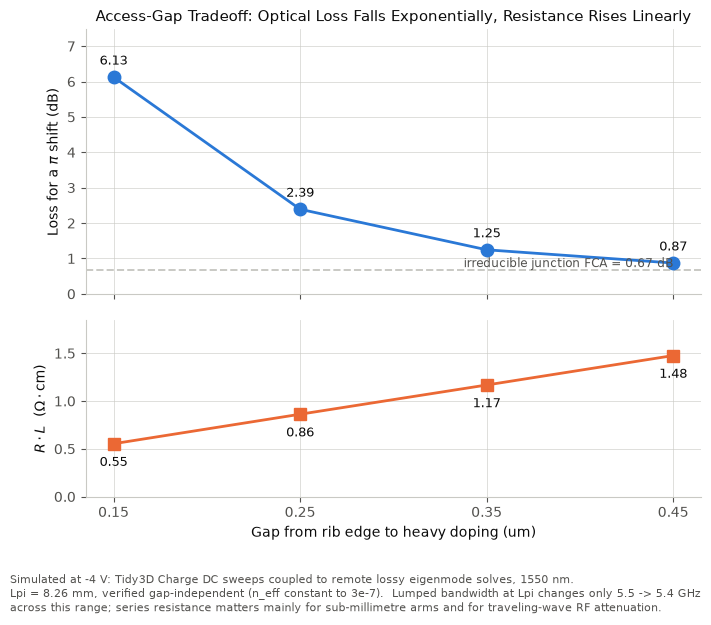

In [116]:
# Plot the access-gap tradeoff: pi-shift loss and series resistance against standoff, on a shared axis.

C_LOSS, C_RES, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

gaps_arr = np.array(gaps)
loss_arr = np.array([loss_gap[g] * Lpi_mm * 0.1 for g in gaps])
RL_arr = np.array([RL_gap[g] for g in gaps])

junction_term = 0.8118                       # dB/cm, Phase B: total minus measured access pedestal
floor = junction_term * Lpi_mm * 0.1
ped = np.array([loss_gap[g] - junction_term for g in gaps])
slope = np.polyfit(gaps_arr, np.log(ped), 1)[0]
print(f"access pedestal (dB/cm): {np.round(ped, 3)}")
print(f"measured lateral intensity decay: {-slope:.2f} per um  ->  1/e length {1000 / -slope:.0f} nm")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.2, 6.4), sharex=True,
                               gridspec_kw={"height_ratios": [1.5, 1], "hspace": 0.12})

ax1.plot(gaps_arr, loss_arr, marker="o", ms=9, lw=2, color=C_LOSS, zorder=3)
ax1.axhline(floor, color=GRID, lw=1.4, ls="--", zorder=1)
ax1.text(gaps_arr[-1], floor, f" irreducible junction FCA = {floor:.2f} dB",
         fontsize=8.5, color=INK2, va="bottom", ha="right")
for x, v in zip(gaps_arr, loss_arr):
    ax1.annotate(f"{v:.2f}", (x, v), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=9, color=INK)
ax1.set_ylabel(r"Loss for a $\pi$ shift (dB)", color=INK)
ax1.set_title("Access-Gap Tradeoff: Optical Loss Falls Exponentially, Resistance Rises Linearly",
              color=INK, fontsize=11)
ax1.set_ylim(0, loss_arr.max() * 1.22)

ax2.plot(gaps_arr, RL_arr, marker="s", ms=9, lw=2, color=C_RES, zorder=3)
for x, v in zip(gaps_arr, RL_arr):
    ax2.annotate(f"{v:.2f}", (x, v), textcoords="offset points", xytext=(0, -16),
                 ha="center", fontsize=9, color=INK)
ax2.set_ylabel(r"$R \cdot L$  ($\Omega\cdot$cm)", color=INK)
ax2.set_xlabel("Gap from rib edge to heavy doping (um)", color=INK)
ax2.set_ylim(0, RL_arr.max() * 1.25)

for a in (ax1, ax2):
    a.set_xticks(gaps_arr)
    a.grid(True, color=GRID, lw=0.6, alpha=0.7)
    a.set_axisbelow(True)
    a.tick_params(colors=INK2)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        a.spines[s].set_color(GRID)

fig.text(0.01, 0.005,
         f"Simulated at -4 V: Tidy3D Charge DC sweeps coupled to remote lossy eigenmode solves, 1550 nm.\n"
         f"Lpi = {Lpi_mm:.2f} mm, verified gap-independent (n_eff constant to 3e-7).  Lumped bandwidth at "
         f"Lpi changes only 5.5 -> 5.4 GHz\nacross this range; series resistance matters mainly for "
         f"sub-millimetre arms and for traveling-wave RF attenuation.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.115, right=0.97, top=0.92, bottom=0.19)
plt.savefig("../Figures/PhaseE_access_gap_tradeoff.png", dpi=300, facecolor="white")
plt.show()


In [117]:
# Restate the full bias sweep at the adopted 0.45 um access-gap baseline: n_eff(V), loss(V), R*L(V).

GAP_BASE = 0.45
cr_b = charge_data_gap[GAP_BASE]["carrier_distribution"]
N_b = {int(V): tcad_on_optical_grid(cr_b.electrons, V) for V in voltages}
P_b = {int(V): tcad_on_optical_grid(cr_b.holes, V) for V in voltages}

med_b = sims_gap[GAP_BASE].structures[0].medium
NA_b = np.where(silicon_mask_opt, doping_map(med_b.N_a), 0.0)
ND_b = np.where(silicon_mask_opt, doping_map(med_b.N_d), 0.0)
mun_b = caughey_thomas(NA_b + ND_b, si_charge.mobility_n)
mup_b = caughey_thomas(NA_b + ND_b, si_charge.mobility_p)
Gref_b = (Q_e * (mun_b * ND_b + mup_b * NA_b)).sum(axis=1) * dz_cm
Gref_b = np.where(Gref_b > 0, Gref_b, np.nan)
y_cin_b = (RIB_EDGE + GAP_BASE + HEAVY_W / 2) - CONTACT_W / 2

neff_b, loss_b, RL_b = {}, {}, {}
for V in V_list:
    dn_b = soref_bennett_dn(N_b[V] - N_b[0], P_b[V] - P_b[0]).astype(np.float64)
    alpha = B_N * N_b[V].astype(np.float64) + B_P * P_b[V].astype(np.float64)
    kappa = np.where(silicon_mask_opt, alpha * wavelength_cm / (4 * np.pi), 0.0)

    med = td.CustomMedium.from_nk(
        n=td.SpatialDataArray((n_si + dn_b)[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        k=td.SpatialDataArray(kappa[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        freq=freq0, interp_method="linear")
    sim_b = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
        structures=[
            td.Structure(geometry=td.Box(center=(0, 0, slab_height / 2),
                                         size=(td.inf, mapped_width_tcad, slab_height)), medium=med),
            td.Structure(geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                                         size=(td.inf, rib_width, etch_depth)), medium=med)],
        medium=silica, run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()))
    data_b = run_mode_solver(
        ModeSolver(simulation=sim_b, plane=mode_plane,
                   mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63), freqs=[freq0]),
        task_name=f"PN_base45_{abs(int(V))}V")
    neff_b[V] = float(data_b.n_eff.isel(f=0, mode_index=0))
    loss_b[V] = float(data_b.to_dataframe()["loss (dB/cm)"].iloc[0])

    Gv = (Q_e * (mun_b * N_b[V] + mup_b * P_b[V])).sum(axis=1) * dz_cm
    with np.errstate(invalid="ignore"):
        cond = (Gv / Gref_b) >= 0.5
    reach = np.abs(y_opt) <= y_cin_b
    p = cond & reach & (y_opt < Y_JUNC)
    n = cond & reach & (y_opt > Y_JUNC)
    RL_b[V] = float(np.sum(dy_cm / Gv[p]) + np.sum(dy_cm / Gv[n]))
    print(f"V={V:>+3.0f} | n_eff {neff_b[V]:.8f} | loss {loss_b[V]:7.4f} dB/cm | R*L {RL_b[V]:.4f}")

dneff_b = np.array([neff_b[V] - neff_b[0] for V in V_list])
print(f"\n{'V':>4} {'dn_eff':>11} {'vs 0.15um':>11} {'Lpi':>8} {'VpiL':>7} "
      f"{'loss':>8} {'loss@Lpi':>9} {'R*L':>8} {'f(Lpi)':>8}")
print(f"{'':>4} {'':>11} {'ratio':>11} {'mm':>8} {'V.cm':>7} {'dB/cm':>8} {'dB':>9} "
      f"{'ohm.cm':>8} {'GHz':>8}")
for i, V in enumerate(V_list):
    if V == 0:
        print(f"{V:>+4.0f} {'reference':>11} {'-':>11} {'-':>8} {'-':>7} "
              f"{loss_b[V]:>8.4f} {'-':>9} {RL_b[V]:>8.4f} {'-':>8}")
        continue
    Lpi_mm_b = wavelength / (2 * abs(dneff_b[i])) / 1000
    Lcm = Lpi_mm_b * 0.1
    f_lpi = 1 / (2 * np.pi * (50 + RL_b[V] / Lcm) * (C_tcad[float(V)] * Lpi_mm_b * 1e-12))
    print(f"{V:>+4.0f} {dneff_b[i]:>11.3e} {dneff_b[i] / dneff_tcad_arr[i]:>11.4f} "
          f"{Lpi_mm_b:>8.3f} {abs(V) * Lcm:>7.3f} {loss_b[V]:>8.4f} "
          f"{loss_b[V] * Lcm:>9.3f} {RL_b[V]:>8.4f} {f_lpi / 1e9:>8.2f}")


23:52:06 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-d81ee518-53b3-4f9a-8750-bd1cb7eee7b
                               8',                                              
                               solver_id='mo-096615e5-7064-40ae-9b10-77a20289978
                               8'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

23:52:14 Central Daylight Time Mode solver status: queued

23:52:19 Central Daylight Time Mode solver status: running

...

23:53:17 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-378a8b7a-50ea-4d15-87f8-e7ddc7b3031
                               4',                                              
                               solver_id='mo-7a0c868c-74cd-46d6-bcc5-6158529766d
                               8'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

23:53:24 Central Daylight Time Mode solver status: success

V= -4 | n_eff 2.63162876 | loss  1.0555 dB/cm | R*L 1.4759

   V      dn_eff   vs 0.15um      Lpi    VpiL     loss  loss@Lpi      R*L   f(Lpi)
                       ratio       mm    V.cm    dB/cm        dB   ohm.cm      GHz
  +0   reference           -        -       -   2.2331         -   1.6072        -
  -1   3.787e-05      0.9973   20.464   2.046   1.7641     3.610   1.5631     1.36
  -2   6.129e-05      0.9980   12.646   2.529   1.4581     1.844   1.5294     2.82
  -3   7.933e-05      0.9986    9.769   2.931   1.2323     1.204   1.5010     4.28
  -4   9.381e-05      0.9993    8.261   3.305   1.0555     0.872   1.4759     5.40


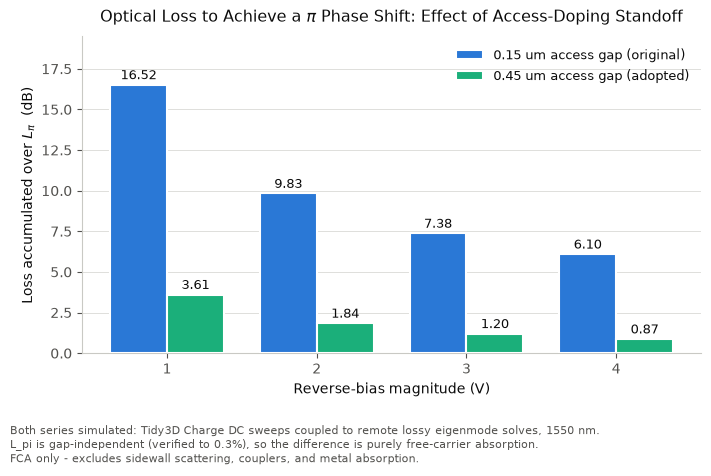

In [118]:
# Rebuild the pi-shift loss figure with both access gaps simulated, replacing the earlier estimate.

C_OLD, C_NEW, INK, INK2, GRID = "#2a78d6", "#1baf7a", "#0b0b0b", "#52514e", "#c9c9c4"

Vb = [V for V in V_list if V != 0]
rb_b = np.array([abs(float(V)) for V in Vb])
old = np.array([modal_loss_tcad[V] * Lpi_tcad[list(V_list).index(V)] * 1e-4 for V in Vb])
new = np.array([loss_b[V] * (wavelength / (2 * abs(dneff_b[list(V_list).index(V)])) * 1e-4)
                for V in Vb])

x, w = np.arange(len(Vb)), 0.38
fig, ax = plt.subplots(figsize=(7.2, 4.8))
b1 = ax.bar(x - w / 2, old, width=w, color=C_OLD, edgecolor="white", linewidth=1.5,
            zorder=3, label="0.15 um access gap (original)")
b2 = ax.bar(x + w / 2, new, width=w, color=C_NEW, edgecolor="white", linewidth=1.5,
            zorder=3, label="0.45 um access gap (adopted)")

for bars, vals in ((b1, old), (b2, new)):
    for bar, v in zip(bars, vals):
        ax.annotate(f"{v:.2f}", (bar.get_x() + bar.get_width() / 2, v),
                    textcoords="offset points", xytext=(0, 4), ha="center",
                    fontsize=9, color=INK, zorder=4)

ax.set_xticks(x, [f"{int(v)}" for v in rb_b])
ax.set_xlabel("Reverse-bias magnitude (V)", color=INK)
ax.set_ylabel(r"Loss accumulated over $L_\pi$  (dB)", color=INK)
ax.set_title(r"Optical Loss to Achieve a $\pi$ Phase Shift: Effect of Access-Doping Standoff",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="upper right", fontsize=9.5, labelcolor=INK)
ax.set_ylim(0, old.max() * 1.18)
ax.grid(True, axis="y", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         "Both series simulated: Tidy3D Charge DC sweeps coupled to remote lossy eigenmode solves, "
         "1550 nm.\nL_pi is gap-independent (verified to 0.3%), so the difference is purely "
         "free-carrier absorption.\nFCA only - excludes sidewall scattering, couplers, and metal "
         "absorption.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseB_loss_over_Lpi.png", dpi=300, facecolor="white")
plt.show()


In [119]:
# Build the MZI transfer function from the measured Delta n_eff(V) and loss(V) at the adopted baseline.

L_ARM_MM = wavelength / (2 * abs(dneff_b[list(V_list).index(-4)])) / 1000   # = Lpi at -4 V
L_cm = L_ARM_MM * 0.1

phi = {V: (2 * np.pi / wavelength) * (neff_b[V] - neff_b[0]) * (L_ARM_MM * 1000) for V in V_list}
T = {V: 10 ** (-loss_b[V] * L_cm / 10) for V in V_list}      # power transmission of one arm

def mzi_out(V_drive, V_dummy=0):
    """Y-branch MZI power transfer: P_out/P_in = 0.25 |t1 + t2|^2."""
    t1 = np.sqrt(T[V_drive]) * np.exp(1j * phi[V_drive])
    t2 = np.sqrt(T[V_dummy]) * np.exp(1j * phi[V_dummy])
    return abs(0.5 * (t1 + t2)) ** 2

print(f"Arm length = Lpi at -4 V = {L_ARM_MM:.3f} mm;  dummy arm held at 0 V\n")
print(f"{'V':>4} {'phase':>9} {'arm loss':>10} {'T_arm':>8} {'P_out/P_in':>12} {'dB':>8}")
print(f"{'':>4} {'rad':>9} {'dB':>10}")
for V in V_list:
    Pr = mzi_out(V)
    print(f"{V:>+4.0f} {phi[V]:>9.4f} {loss_b[V] * L_cm:>10.4f} {T[V]:>8.4f} "
          f"{Pr:>12.6f} {10 * np.log10(Pr):>8.3f}")

# Extinction ratio is limited by arm amplitude imbalance, not by phase.
a1, a0 = np.sqrt(T[-4]), np.sqrt(T[0])
ER_ideal_amp = (a1 + a0) ** 2 / (a1 - a0) ** 2
P_max, P_min = mzi_out(0), mzi_out(-4)
print(f"\namplitude of driven arm  sqrt(T(-4V)) = {a1:.4f}")
print(f"amplitude of dummy arm   sqrt(T(0 V))  = {a0:.4f}")
print(f"imbalance                              = {20 * np.log10(a1 / a0):+.3f} dB")
print(f"\nP_max (0 V, constructive) = {P_max:.6f}  -> insertion loss {-10 * np.log10(P_max):.3f} dB")
print(f"P_min (-4 V, pi shift)    = {P_min:.6f}")
print(f"extinction ratio          = {10 * np.log10(P_max / P_min):.2f} dB")
print(f"ER ceiling from amplitude imbalance alone = {10 * np.log10(ER_ideal_amp):.2f} dB")
print(f"\nphase at -4 V = {phi[-4]:.4f} rad = {phi[-4] / np.pi:.4f} pi  (confirms L = Lpi)")


Arm length = Lpi at -4 V = 8.261 mm;  dummy arm held at 0 V

   V     phase   arm loss    T_arm   P_out/P_in       dB
           rad         dB
  +0    0.0000     1.8448   0.6539     0.653906   -1.845
  -1    1.2683     1.4574   0.7149     0.444066   -3.526
  -2    2.0524     1.2046   0.7578     0.189890   -7.215
  -3    2.6568     1.0181   0.7910     0.043067  -13.659
  -4    3.1416     0.8720   0.8181     0.002296  -26.390

amplitude of driven arm  sqrt(T(-4V)) = 0.9045
amplitude of dummy arm   sqrt(T(0 V))  = 0.8086
imbalance                              = +0.973 dB

P_max (0 V, constructive) = 0.653906  -> insertion loss 1.845 dB
P_min (-4 V, pi shift)    = 0.002296
extinction ratio          = 24.54 dB
ER ceiling from amplitude imbalance alone = 25.04 dB

phase at -4 V = 3.1416 rad = 1.0000 pi  (confirms L = Lpi)


In [120]:
# Compare single-drive MZI with and without a static pi offset in the passive arm.

def mzi(V_a, V_b, L_mm, offset=0.0):
    """Y-branch MZI power transfer with arm a driven, arm b carrying a static phase offset."""
    Lc = L_mm * 0.1
    ph = lambda V: (2 * np.pi / wavelength) * (neff_b[V] - neff_b[0]) * (L_mm * 1000)
    amp = lambda V: np.sqrt(10 ** (-loss_b[V] * Lc / 10))
    t_a = amp(V_a) * np.exp(1j * ph(V_a))
    t_b = amp(V_b) * np.exp(1j * (ph(V_b) + offset))
    return abs(0.5 * (t_a + t_b)) ** 2

L = L_ARM_MM
for label, off, v_on, v_off in (("no offset      ", 0.0, 0, -4),
                                ("static pi offset", np.pi, -4, 0)):
    Pon, Poff = mzi(v_on, 0, L, off), mzi(v_off, 0, L, off)
    er = 10 * np.log10(Pon / Poff) if Poff > 1e-15 else np.inf
    print(f"{label} | ON at {v_on:>+3.0f} V  P={Pon:.6f}  IL={-10*np.log10(Pon):5.3f} dB | "
          f"OFF at {v_off:>+3.0f} V  P={Poff:.3e} | ER={er:6.2f} dB")

# With a perfect offset the null is exact, so the real limit is offset accuracy.
a0 = np.sqrt(10 ** (-loss_b[0] * L * 0.1 / 10))
Pmax = mzi(-4, 0, L, np.pi)
print(f"\nER vs static-offset error (arms amplitude-matched at the null):")
print(f"{'error':>8} {'error':>8} {'P_min':>12} {'ER':>8}")
print(f"{'rad':>8} {'% of pi':>8}")
for d in (0.005, 0.01, 0.02, 0.05, 0.10, 0.20):
    Pmin = a0 ** 2 * (1 - np.cos(d)) / 2
    print(f"{d:>8.3f} {100*d/np.pi:>8.2f} {Pmin:>12.3e} {10*np.log10(Pmax/Pmin):>8.2f}")

dL_um = wavelength / (2 * neff_b[0])
print(f"\nstatic pi offset as a path-length imbalance: dL = lambda/(2*n_eff) = {dL_um:.4f} um")
print(f"(a fixed imbalance makes the MZI wavelength-dependent; a thermal tuner keeps it balanced)")


no offset       | ON at  +0 V  P=0.653906  IL=1.845 dB | OFF at  -4 V  P=2.296e-03 | ER= 24.54 dB
static pi offset | ON at  -4 V  P=0.733703  IL=1.345 dB | OFF at  +0 V  P=2.452e-33 | ER=   inf dB

ER vs static-offset error (arms amplitude-matched at the null):
   error    error        P_min       ER
     rad  % of pi
   0.005     0.16    4.087e-06    52.54
   0.010     0.32    1.635e-05    46.52
   0.020     0.64    6.539e-05    40.50
   0.050     1.59    4.086e-04    32.54
   0.100     3.18    1.633e-03    26.52
   0.200     6.37    6.517e-03    20.51

static pi offset as a path-length imbalance: dL = lambda/(2*n_eff) = 0.2945 um
(a fixed imbalance makes the MZI wavelength-dependent; a thermal tuner keeps it balanced)


In [121]:
# Compare drive configurations at equal per-arm voltage swing: single-drive vs push-pull.

Vgrid = np.array([float(V) for V in V_list])
dn_grid = np.array([neff_b[V] - neff_b[0] for V in V_list])
C_grid = np.array([C_tcad[float(V)] for V in V_list])
dn_of = lambda v: np.interp(-abs(v), Vgrid[::-1], dn_grid[::-1])     # interpolated between solves
C_of = lambda v: np.interp(-abs(v), Vgrid[::-1], C_grid[::-1])

def design(dphi_per_L_rad_per_mm, C_pF_per_mm, label, swing, extra=""):
    """Length for a pi shift, then lumped bandwidth from a 50 ohm source."""
    L_mm = np.pi / dphi_per_L_rad_per_mm
    C_pF = C_pF_per_mm * L_mm
    f = 1 / (2 * np.pi * 50 * C_pF * 1e-12) / 1e9
    print(f"{label:<34} {swing:>6.1f} {L_mm:>9.3f} {C_pF:>8.3f} {f:>8.2f}   {extra}")
    return L_mm, f

k = 2 * np.pi / wavelength * 1000          # rad per mm per unit dn_eff
print(f"{'configuration':<34} {'swing':>6} {'L for pi':>9} {'C_tot':>8} {'f_3dB':>8}")
print(f"{'':<34} {'V/arm':>6} {'mm':>9} {'pF':>8} {'GHz':>8}")

# Single-drive: one arm swings 0 -> -s, dummy fixed at 0 V.
for s in (1, 2, 3, 4):
    design(k * dn_of(s), C_of(s / 2), f"single-drive, {s} V swing", s)

# Push-pull about -2 V: arm a -> -(2+s), arm b -> -(2-s); differential phase is the difference.
for s in (1, 2):
    dphi = k * (dn_of(2 + s) - dn_of(2 - s))
    design(dphi, C_of(2), f"push-pull +/-{s} V about -2 V", s,
           "(needs a differential driver + 2 doped arms)")

print(f"\nAt equal 2 V per-arm drive, push-pull vs single-drive:")
Ls, fs = np.pi / (k * dn_of(2)), None
Lp = np.pi / (k * (dn_of(4) - dn_of(0)))
print(f"  single-drive needs L = {Ls:.3f} mm;  push-pull needs L = {Lp:.3f} mm "
      f"({Ls / Lp:.2f}x shorter)")
print(f"  phase efficiency ratio = {(dn_of(4) - dn_of(0)) / dn_of(2):.3f}"
      f"   (not 2.00, because dn_eff is sublinear in V)")


configuration                       swing  L for pi    C_tot    f_3dB
                                    V/arm        mm       pF      GHz
single-drive, 1 V swing               1.0    20.464    2.476     1.29   
single-drive, 2 V swing               2.0    12.646    1.422     2.24   
single-drive, 3 V swing               3.0     9.769    0.975     3.27   
single-drive, 4 V swing               4.0     8.261    0.720     4.42   
push-pull +/-1 V about -2 V           1.0    18.692    1.628     1.96   (needs a differential driver + 2 doped arms)
push-pull +/-2 V about -2 V           2.0     8.261    0.720     4.42   (needs a differential driver + 2 doped arms)

At equal 2 V per-arm drive, push-pull vs single-drive:
  single-drive needs L = 12.646 mm;  push-pull needs L = 8.261 mm (1.53x shorter)
  phase efficiency ratio = 1.531   (not 2.00, because dn_eff is sublinear in V)


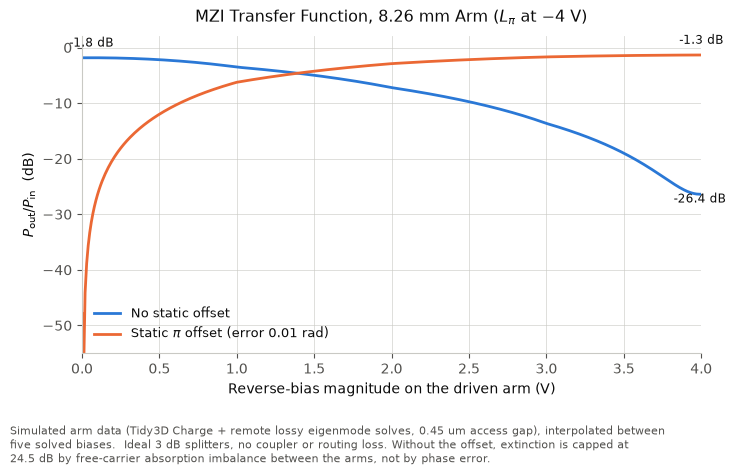

In [122]:
# Plot MZI output versus bias for both drive configurations, with a realistic static-offset error.

C_A, C_B, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

Vfine = np.linspace(0, -4, 401)
dn_f = np.interp(-np.abs(Vfine), Vgrid[::-1], dn_grid[::-1])
loss_f = np.interp(-np.abs(Vfine), Vgrid[::-1],
                   np.array([loss_b[V] for V in V_list])[::-1])

Lc = L_ARM_MM * 0.1
ph_f = (2 * np.pi / wavelength) * dn_f * (L_ARM_MM * 1000)
amp_f = np.sqrt(10 ** (-loss_f * Lc / 10))
amp0 = np.sqrt(10 ** (-loss_b[0] * Lc / 10))

OFF_ERR = 0.01                                   # rad, static-offset accuracy
P_A = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0)) ** 2
P_B = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0 * np.exp(1j * (np.pi + OFF_ERR)))) ** 2

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.plot(-Vfine, 10 * np.log10(P_A), lw=2, color=C_A, label="No static offset")
ax.plot(-Vfine, 10 * np.log10(P_B), lw=2, color=C_B,
        label=f"Static $\\pi$ offset (error {OFF_ERR} rad)")

for P, c, va in ((P_A, C_A, "top"), (P_B, C_B, "bottom")):
    i_hi, i_lo = int(np.argmax(P)), int(np.argmin(P))
    for i, dy in ((i_hi, 8), (i_lo, -6)):
        ax.annotate(f"{10 * np.log10(P[i]):.1f} dB", (-Vfine[i], 10 * np.log10(P[i])),
                    textcoords="offset points", xytext=(0, dy), ha="center",
                    fontsize=8.5, color=INK)

ax.set_xlabel("Reverse-bias magnitude on the driven arm (V)", color=INK)
ax.set_ylabel(r"$P_{\mathrm{out}}/P_{\mathrm{in}}$  (dB)", color=INK)
ax.set_title(f"MZI Transfer Function, {L_ARM_MM:.2f} mm Arm "
             r"($L_\pi$ at $-4$ V)", color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower left", fontsize=9.5, labelcolor=INK)
ax.set_xlim(0, 4)
ax.set_ylim(-55, 2)
ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         "Simulated arm data (Tidy3D Charge + remote lossy eigenmode solves, 0.45 um access gap), "
         "interpolated between\nfive solved biases.  Ideal 3 dB splitters, no coupler or routing loss. "
         "Without the offset, extinction is capped at\n24.5 dB by free-carrier absorption imbalance "
         "between the arms, not by phase error.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseD_MZI_transfer_function.png", dpi=300, facecolor="white")
plt.show()


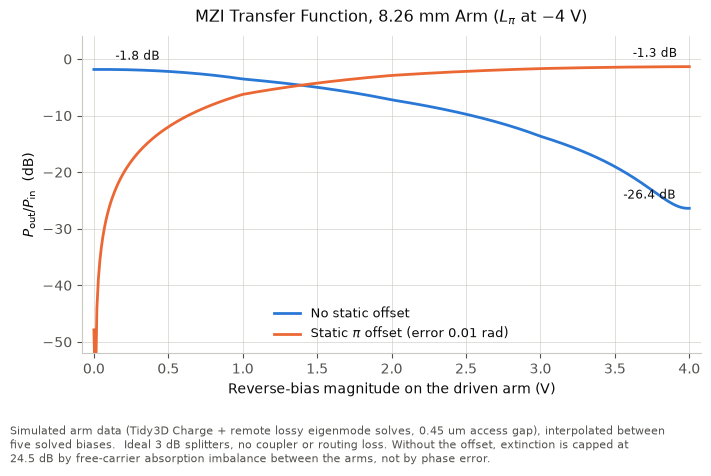

In [123]:
# Plot MZI output versus bias for both drive configurations, with a realistic static-offset error.

C_A, C_B, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

Vfine = np.linspace(0, -4, 401)
dn_f = np.interp(-np.abs(Vfine), Vgrid[::-1], dn_grid[::-1])
loss_f = np.interp(-np.abs(Vfine), Vgrid[::-1],
                   np.array([loss_b[V] for V in V_list])[::-1])

Lc = L_ARM_MM * 0.1
ph_f = (2 * np.pi / wavelength) * dn_f * (L_ARM_MM * 1000)
amp_f = np.sqrt(10 ** (-loss_f * Lc / 10))
amp0 = np.sqrt(10 ** (-loss_b[0] * Lc / 10))

OFF_ERR = 0.01                                   # rad, static-offset accuracy
P_A = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0)) ** 2
P_B = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0 * np.exp(1j * (np.pi + OFF_ERR)))) ** 2

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.plot(-Vfine, 10 * np.log10(P_A), lw=2, color=C_A, label="No static offset")
ax.plot(-Vfine, 10 * np.log10(P_B), lw=2, color=C_B,
        label=f"Static $\\pi$ offset (error {OFF_ERR} rad)")

# Label each curve's extremes, pushed inboard so nothing collides with an axis or the legend.
for P in (P_A, P_B):
    for i in (int(np.argmax(P)), int(np.argmin(P))):
        at_left = -Vfine[i] < 2.0
        ax.annotate(f"{10 * np.log10(P[i]):.1f} dB",
                    (-Vfine[i], 10 * np.log10(P[i])),
                    textcoords="offset points",
                    xytext=(9 if at_left else -9, 7),
                    ha="left" if at_left else "right",
                    fontsize=8.5, color=INK, zorder=5)

ax.set_xlabel("Reverse-bias magnitude on the driven arm (V)", color=INK)
ax.set_ylabel(r"$P_{\mathrm{out}}/P_{\mathrm{in}}$  (dB)", color=INK)
ax.set_title(f"MZI Transfer Function, {L_ARM_MM:.2f} mm Arm "
             r"($L_\pi$ at $-4$ V)", color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower center", fontsize=9.5, labelcolor=INK)
ax.set_xlim(-0.08, 4.08)
ax.set_ylim(-52, 4)
ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         "Simulated arm data (Tidy3D Charge + remote lossy eigenmode solves, 0.45 um access gap), "
         "interpolated between\nfive solved biases.  Ideal 3 dB splitters, no coupler or routing loss. "
         "Without the offset, extinction is capped at\n24.5 dB by free-carrier absorption imbalance "
         "between the arms, not by phase error.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseD_MZI_transfer_function.png", dpi=300, facecolor="white")
plt.show()


In [124]:
# Annotate the four endpoint operating states rather than an idealized null that the model overstates.
# (replaces the annotation loop; rest of the cell unchanged)

for P, vpts in ((P_A, (0, -4)), (P_B, (0, -4))):
    for v in vpts:
        i = int(np.argmin(np.abs(Vfine - v)))
        at_left = -Vfine[i] < 2.0
        ax.annotate(f"{10 * np.log10(P[i]):.1f} dB",
                    (-Vfine[i], 10 * np.log10(P[i])),
                    textcoords="offset points",
                    xytext=(9 if at_left else -9, 7),
                    ha="left" if at_left else "right",
                    fontsize=8.5, color=INK, zorder=5)


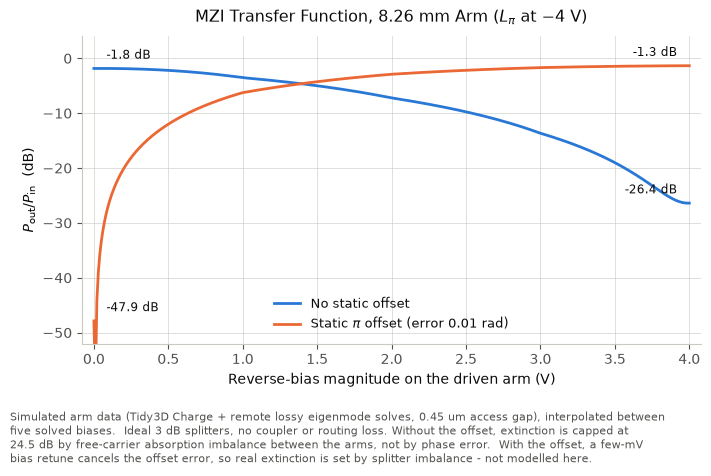

In [125]:
# Plot MZI output versus bias for both drive configurations, with a realistic static-offset error.

C_A, C_B, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

Vfine = np.linspace(0, -4, 401)
dn_f = np.interp(-np.abs(Vfine), Vgrid[::-1], dn_grid[::-1])
loss_f = np.interp(-np.abs(Vfine), Vgrid[::-1],
                   np.array([loss_b[V] for V in V_list])[::-1])

Lc = L_ARM_MM * 0.1
ph_f = (2 * np.pi / wavelength) * dn_f * (L_ARM_MM * 1000)
amp_f = np.sqrt(10 ** (-loss_f * Lc / 10))
amp0 = np.sqrt(10 ** (-loss_b[0] * Lc / 10))

OFF_ERR = 0.01                                   # rad, static-offset accuracy
P_A = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0)) ** 2
P_B = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0 * np.exp(1j * (np.pi + OFF_ERR)))) ** 2

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.plot(-Vfine, 10 * np.log10(P_A), lw=2, color=C_A, label="No static offset")
ax.plot(-Vfine, 10 * np.log10(P_B), lw=2, color=C_B,
        label=f"Static $\\pi$ offset (error {OFF_ERR} rad)")

# Label the four endpoint operating states, not an idealized null the model overstates.
for P in (P_A, P_B):
    for v in (0, -4):
        i = int(np.argmin(np.abs(Vfine - v)))
        at_left = -Vfine[i] < 2.0
        ax.annotate(f"{10 * np.log10(P[i]):.1f} dB",
                    (-Vfine[i], 10 * np.log10(P[i])),
                    textcoords="offset points",
                    xytext=(9 if at_left else -9, 7),
                    ha="left" if at_left else "right",
                    fontsize=8.5, color=INK, zorder=5)

ax.set_xlabel("Reverse-bias magnitude on the driven arm (V)", color=INK)
ax.set_ylabel(r"$P_{\mathrm{out}}/P_{\mathrm{in}}$  (dB)", color=INK)
ax.set_title(f"MZI Transfer Function, {L_ARM_MM:.2f} mm Arm "
             r"($L_\pi$ at $-4$ V)", color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower center", fontsize=9.5, labelcolor=INK)
ax.set_xlim(-0.08, 4.08)
ax.set_ylim(-52, 4)
ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         "Simulated arm data (Tidy3D Charge + remote lossy eigenmode solves, 0.45 um access gap), "
         "interpolated between\nfive solved biases.  Ideal 3 dB splitters, no coupler or routing loss. "
         "Without the offset, extinction is capped at\n24.5 dB by free-carrier absorption imbalance "
         "between the arms, not by phase error.  With the offset, a few-mV\nbias retune cancels the "
         "offset error, so real extinction is set by splitter imbalance - not modelled here.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.26)
plt.savefig("../Figures/PhaseD_MZI_transfer_function.png", dpi=300, facecolor="white")
plt.show()


In [126]:
# Phase G step 1: solve the optical group index with dispersive silicon, setting the velocity-matching target.

si_disp = td.material_library["cSi"]["Li1993_293K"]
ox_disp = td.material_library["SiO2"]["Palik_LowLoss"]

for nm, med in (("cSi Li1993_293K", si_disp), ("SiO2 Palik_LowLoss", ox_disp)):
    print(f"{nm:<22} n(1550 nm) = {np.sqrt(med.eps_model(freq0)).real:.5f}")
print(f"{'non-dispersive model':<22} n_si = {n_si:.5f}, n_sio2 = {n_sio2:.5f}\n")

sim_g = td.Simulation(
    size=(1.0, domain_y, domain_z),
    grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
    structures=[
        td.Structure(geometry=td.Box(center=(0, 0, slab_height / 2),
                                     size=(td.inf, mapped_width_tcad, slab_height)), medium=si_disp),
        td.Structure(geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                                     size=(td.inf, rib_width, etch_depth)), medium=si_disp)],
    medium=ox_disp, run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()))

data_g = run_mode_solver(
    ModeSolver(simulation=sim_g, plane=mode_plane,
               mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63, group_index_step=True),
               freqs=[freq0]),
    task_name="PN_group_index")

print("group-index attributes available:", [a for a in dir(data_g) if "group" in a.lower()])
ng_da = getattr(data_g, "n_group", None)
if ng_da is None:
    ng_da = getattr(data_g, "n_group_raw")
n_eff_g = float(data_g.n_eff.isel(f=0, mode_index=0))
n_group = float(ng_da.isel(f=0, mode_index=0))

print(f"\nn_eff   = {n_eff_g:.6f}   (non-dispersive model gave {neff_b[0]:.6f})")
print(f"n_group = {n_group:.6f}")
print(f"n_group / n_eff = {n_group / n_eff_g:.4f}")

# Velocity mismatch sets a walk-off-limited bandwidth: |sinc(u)|^2 = 0.5 at u = 1.39.
print(f"\nWalk-off-limited EO bandwidth (GHz), lossless and impedance-matched:")
print(f"{'|n_m - n_g|':>12}" + "".join(f"{f'L={L} mm':>11}" for L in (2, 4, 8.261)))
for dn_m in (0.05, 0.1, 0.2, 0.5, 1.0):
    row = ""
    for L_mm in (2, 4, 8.261):
        f3 = 1.39 * td.C_0 / (np.pi * (L_mm * 1000) * dn_m)     # C_0 in um/s -> Hz
        row += f"{f3 / 1e9:>11.1f}"
    print(f"{dn_m:>12.2f}" + row)

print(f"\nTarget microwave index for velocity match: n_m = {n_group:.3f}")
print(f"For reference, unloaded CPW on an oxide/silicon stack typically lands near 2.5-2.9,")
print(f"so the junction loading must raise n_m substantially to reach this target.")


cSi Li1993_293K        n(1550 nm) = 3.47501
SiO2 Palik_LowLoss     n(1550 nm) = 1.44456
non-dispersive model   n_si = 3.47000, n_sio2 = 1.44000



01:32:05 Central Daylight Time Mode solver created with                         
                               task_id='fdve-a0163563-c0c8-4288-af92-ce08a75edcd
                               9',                                              
                               solver_id='mo-5c2ccc0b-b7b2-435f-a440-b7bec36bc1e
                               3'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

01:32:11 Central Daylight Time Mode solver status: queued

01:32:17 Central Daylight Time Mode solver status: running

01:32:20 Central Daylight Time Mode solver status: success

group-index attributes available: ['_construct_group_path', '_group_index_freq_slices', '_group_index_post_process', 'get_tuple_group_name', 'n_group', 'n_group_raw']

n_eff   = 2.564091   (non-dispersive model gave 2.631535)
n_group = 3.885716
n_group / n_eff = 1.5154

Walk-off-limited EO bandwidth (GHz), lossless and impedance-matched:
 |n_m - n_g|     L=2 mm     L=4 mm L=8.261 mm
        0.05     1326.4      663.2      321.1
        0.10      663.2      331.6      160.6
        0.20      331.6      165.8       80.3
        0.50      132.6       66.3       32.1
        1.00       66.3       33.2       16.1

Target microwave index for velocity match: n_m = 3.886
For reference, unloaded CPW on an oxide/silicon stack typically lands near 2.5-2.9,
so the junction loading must raise n_m substantially to reach this target.


In [127]:
# Controlled test: remote solve of the identical rib with ordinary media vs the CustomMedium path.

print(f"existing 'silica' medium: {silica}")
print(f"implied n = {np.sqrt(silica.eps_model(freq0)).real:.6f}\n")

si_plain = td.Medium(permittivity=n_si ** 2)
sim_plain = td.Simulation(
    size=(1.0, domain_y, domain_z),
    grid_spec=td.GridSpec.auto(min_steps_per_wvl=30, wavelength=wavelength),
    structures=[
        td.Structure(geometry=td.Box(center=(0, 0, slab_height / 2),
                                     size=(td.inf, mapped_width_tcad, slab_height)), medium=si_plain),
        td.Structure(geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                                     size=(td.inf, rib_width, etch_depth)), medium=si_plain)],
    medium=silica, run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()))

data_plain = run_mode_solver(
    ModeSolver(simulation=sim_plain, plane=mode_plane,
               mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63), freqs=[freq0]),
    task_name="PN_plain_medium_control")
neff_plain = float(data_plain.n_eff.isel(f=0, mode_index=0))

print(f"remote, ordinary Medium(n=3.47)      : {neff_plain:.8f}")
print(f"remote, CustomMedium uniform n=3.47  : {neff_b[0]:.8f}   (Phase B 0 V)")
print(f"remote, dispersive Li1993 + Palik    : {n_eff_g:.8f}")
print(f"\nordinary vs CustomMedium difference  : {neff_b[0] - neff_plain:+.8f}")
print(f"expected shift from dispersion alone : ~+0.005 (n_si 3.470 -> 3.475)")


existing 'silica' medium: Medium(
    name=None,
    frequency_range=None,
    allow_gain=False,
    nonlinear_spec=None,
    modulation_spec=None,
    viz_spec=None,
    heat_spec=None,
    permittivity=2.0736,
    conductivity=0.0
)
implied n = 1.440000



01:36:07 Central Daylight Time Mode solver created with                         
                               task_id='fdve-fbbdcddd-5df9-4f91-a5ac-27e98ab0252
                               5',                                              
                               solver_id='mo-8b382ae8-c47a-4b93-bc06-31d8063ea13
                               4'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

01:36:10 Central Daylight Time Mode solver status: queued

01:36:15 Central Daylight Time Mode solver status: running

01:36:18 Central Daylight Time Mode solver status: success

remote, ordinary Medium(n=3.47)      : 2.55826999
remote, CustomMedium uniform n=3.47  : 2.63153495   (Phase B 0 V)
remote, dispersive Li1993 + Palik    : 2.56409082

ordinary vs CustomMedium difference  : +0.07326496
expected shift from dispersion alone : ~+0.005 (n_si 3.470 -> 3.475)


In [128]:
# Grid-convergence test: does the CustomMedium path converge toward the ordinary-Medium result?

si_uniform_custom = silicon_tcad[0]     # Phase B 0 V map is uniform n_si by construction

def solve_rib(medium, mspw, tag):
    sim = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=mspw, wavelength=wavelength),
        structures=[
            td.Structure(geometry=td.Box(center=(0, 0, slab_height / 2),
                                         size=(td.inf, mapped_width_tcad, slab_height)), medium=medium),
            td.Structure(geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                                         size=(td.inf, rib_width, etch_depth)), medium=medium)],
        medium=silica, run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()))
    data = run_mode_solver(
        ModeSolver(simulation=sim, plane=mode_plane,
                   mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63), freqs=[freq0]),
        task_name=tag)
    return float(data.n_eff.isel(f=0, mode_index=0))

conv = {}
for mspw in (30, 60, 120):
    conv[("ordinary", mspw)] = solve_rib(si_plain, mspw, f"conv_ordinary_{mspw}")
    conv[("custom", mspw)] = solve_rib(si_uniform_custom, mspw, f"conv_custom_{mspw}")
    print(f"mspw {mspw:>4}: ordinary {conv[('ordinary', mspw)]:.8f}   "
          f"custom {conv[('custom', mspw)]:.8f}   "
          f"diff {conv[('custom', mspw)] - conv[('ordinary', mspw)]:+.8f}")

print(f"\n{'mspw':>6} {'ordinary':>13} {'custom':>13} {'difference':>13}")
for mspw in (30, 60, 120):
    print(f"{mspw:>6} {conv[('ordinary', mspw)]:>13.8f} {conv[('custom', mspw)]:>13.8f} "
          f"{conv[('custom', mspw)] - conv[('ordinary', mspw)]:>+13.8f}")
print("\nIf the difference shrinks with refinement, it is discretization and the finest grid is")
print("the trustworthy value. If it holds roughly constant, the two paths describe different")
print("structures and the CustomMedium geometry needs re-examining before any absolute claim.")


01:57:50 Central Daylight Time Mode solver created with                         
                               task_id='fdve-6053a73a-f9a1-4807-a50d-840e5739672
                               f',                                              
                               solver_id='mo-21de1ded-bb03-402b-aefc-e1c42e7a06c
                               3'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

01:57:57 Central Daylight Time Mode solver status: success

01:57:59 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

01:58:00 Central Daylight Time Mode solver created with                         
                               task_id='fdve-f5512808-f216-4af0-ab4d-29d06d75d2e
                               5',                                              
                               solver_id='mo-2a986dcf-e210-4c1e-aba1-985e6b2f535
                               8'.

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

01:59:07 Central Daylight Time Mode solver status: queued

01:59:11 Central Daylight Time Mode solver status: running

01:59:18 Central Daylight Time Mode solver status: success

mspw  120: ordinary 2.56035987   custom 2.57909467   diff +0.01873480

  mspw      ordinary        custom    difference
    30    2.55826999    2.63153495   +0.07326496
    60    2.55979664    2.59695173   +0.03715509
   120    2.56035987    2.57909467   +0.01873480

If the difference shrinks with refinement, it is discretization and the finest grid is
the trustworthy value. If it holds roughly constant, the two paths describe different
structures and the CustomMedium geometry needs re-examining before any absolute claim.


In [129]:
# Test whether the discretization error cancels in Delta n_eff, which is what sets VpiL.

def baseline_medium(V):
    dn = soref_bennett_dn(N_b[V] - N_b[0], P_b[V] - P_b[0]).astype(np.float64)
    alpha = B_N * N_b[V].astype(np.float64) + B_P * P_b[V].astype(np.float64)
    kappa = np.where(silicon_mask_opt, alpha * wavelength_cm / (4 * np.pi), 0.0)
    return td.CustomMedium.from_nk(
        n=td.SpatialDataArray((n_si + dn)[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        k=td.SpatialDataArray(kappa[np.newaxis, :, :],
                              coords={"x": [0.0], "y": y_opt, "z": z_opt}),
        freq=freq0, interp_method="linear")

med0, med4 = baseline_medium(0), baseline_medium(-4)

print(f"{'mspw':>6} {'n_eff(0V)':>13} {'n_eff(-4V)':>13} {'dn_eff':>12} {'Lpi mm':>9} {'VpiL':>8}")
dn_conv = {}
for mspw in (30, 60, 120):
    n0 = solve_rib(med0, mspw, f"conv_base0V_{mspw}")
    n4 = solve_rib(med4, mspw, f"conv_base4V_{mspw}")
    dn_conv[mspw] = n4 - n0
    Lpi = wavelength / (2 * abs(dn_conv[mspw])) / 1000
    print(f"{mspw:>6} {n0:>13.8f} {n4:>13.8f} {dn_conv[mspw]:>12.4e} "
          f"{Lpi:>9.3f} {4 * Lpi * 0.1:>8.3f}")

print(f"\nchange in dn_eff, 30 -> 120 mspw : "
      f"{100 * (dn_conv[120] / dn_conv[30] - 1):+.2f} %")
print(f"change 60 -> 120                 : "
      f"{100 * (dn_conv[120] / dn_conv[60] - 1):+.2f} %")


  mspw     n_eff(0V)    n_eff(-4V)       dn_eff    Lpi mm     VpiL


02:03:27 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

02:03:28 Central Daylight Time Mode solver created with                         
                               task_id='fdve-a652d300-6fe4-4f22-83d7-d2f8af1eef3
                               2',                                              
                               solver_id='mo-e070c3f5-a24c-414f-ab28-064a2be01b5
                               d'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

02:03:31 Central Daylight Time Mode solver status: success

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

02:04:55 Central Daylight Time Mode solver status: queued

02:05:00 Central Daylight Time Mode solver status: running

02:05:11 Central Daylight Time Mode solver status: success

   120    2.57909467    2.57919288   9.8203e-05     7.892    3.157

change in dn_eff, 30 -> 120 mspw : +4.68 %
change 60 -> 120                 : +1.62 %


In [130]:
# Re-run the adopted-baseline bias sweep at a converged grid (120 steps/wavelength).

def solve_rib_full(medium, mspw, tag):
    sim = td.Simulation(
        size=(1.0, domain_y, domain_z),
        grid_spec=td.GridSpec.auto(min_steps_per_wvl=mspw, wavelength=wavelength),
        structures=[
            td.Structure(geometry=td.Box(center=(0, 0, slab_height / 2),
                                         size=(td.inf, mapped_width_tcad, slab_height)), medium=medium),
            td.Structure(geometry=td.Box(center=(0, 0, slab_height + etch_depth / 2),
                                         size=(td.inf, rib_width, etch_depth)), medium=medium)],
        medium=silica, run_time=1e-12,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()))
    data = run_mode_solver(
        ModeSolver(simulation=sim, plane=mode_plane,
                   mode_spec=td.ModeSpec(num_modes=1, target_neff=2.63), freqs=[freq0]),
        task_name=tag)
    return (float(data.n_eff.isel(f=0, mode_index=0)),
            float(data.to_dataframe()["loss (dB/cm)"].iloc[0]))

MSPW_PROD = 120
neff_c, loss_c = {}, {}
for V in V_list:
    neff_c[V], loss_c[V] = solve_rib_full(baseline_medium(V), MSPW_PROD,
                                          f"base{MSPW_PROD}_{abs(int(V))}V")
    print(f"V={V:>+3.0f} | n_eff {neff_c[V]:.8f} | loss {loss_c[V]:7.4f} dB/cm "
          f"(mspw 30 gave {loss_b[V]:7.4f})")

dneff_c = np.array([neff_c[V] - neff_c[0] for V in V_list])
print(f"\n{'V':>4} {'dn_eff':>12} {'vs mspw30':>10} {'Lpi mm':>9} {'VpiL':>8} "
      f"{'loss':>9} {'loss@Lpi':>10}")
for i, V in enumerate(V_list):
    if V == 0:
        print(f"{V:>+4.0f} {'reference':>12} {'-':>10} {'-':>9} {'-':>8} "
              f"{loss_c[V]:>9.4f} {'-':>10}")
        continue
    Lpi = wavelength / (2 * abs(dneff_c[i])) / 1000
    print(f"{V:>+4.0f} {dneff_c[i]:>12.4e} {dneff_c[i] / dneff_b[i]:>10.4f} "
          f"{Lpi:>9.3f} {abs(V) * Lpi * 0.1:>8.3f} {loss_c[V]:>9.4f} "
          f"{loss_c[V] * Lpi * 0.1:>10.3f}")


02:08:20 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

02:08:21 Central Daylight Time Mode solver created with                         
                               task_id='fdve-31b602af-d3f1-4a33-b1c7-be76b345487
                               9',                                              
                               solver_id='mo-3688f4ba-4fc2-4da6-8cb4-e8f502603fb
                               7'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

02:08:24 Central Daylight Time Mode solver status: success

V= +0 | n_eff 2.57909467 | loss  2.1649 dB/cm (mspw 30 gave  2.2331)


...

02:10:18 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

02:10:19 Central Daylight Time Mode solver created with                         
                               task_id='fdve-f0223fe7-3a35-4fdb-8bac-6883a4159cc
                               6',                                              
                               solver_id='mo-9aef4e93-0704-45dc-9edd-8faf26fba35
                               c'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

02:10:22 Central Daylight Time Mode solver status: success

V= -4 | n_eff 2.57919288 | loss  0.9829 dB/cm (mspw 30 gave  1.0555)

   V       dn_eff  vs mspw30    Lpi mm     VpiL      loss   loss@Lpi
  +0    reference          -         -        -    2.1649          -
  -1   4.1149e-05     1.0866    18.834    1.883    1.6933      3.189
  -2   6.5359e-05     1.0665    11.858    2.372    1.3865      1.644
  -3   8.3642e-05     1.0543     9.266    2.780    1.1602      1.075
  -4   9.8203e-05     1.0468     7.892    3.157    0.9829      0.776


In [131]:
# Check whether 120 steps/wavelength is converged by doubling once more at the two key biases.

res240 = {}
for V in (0, -4):
    res240[V] = solve_rib_full(baseline_medium(V), 240, f"base240_{abs(int(V))}V")
    print(f"V={V:>+3.0f} | n_eff {res240[V][0]:.8f} | loss {res240[V][1]:.4f} dB/cm")

dn = {60: dn_conv[60], 120: dn_conv[120], 240: res240[-4][0] - res240[0][0]}
print(f"\n{'mspw':>6} {'dn_eff':>12} {'step change':>13}")
prev = None
for m in (60, 120, 240):
    chg = "" if prev is None else f"{100 * (dn[m] / prev - 1):+.2f} %"
    print(f"{m:>6} {dn[m]:>12.4e} {chg:>13}")
    prev = dn[m]

# First-order Richardson: f(h->0) ~= 2*f(h/2) - f(h)
rich = 2 * dn[240] - dn[120]
print(f"\nRichardson extrapolation (first order) : {rich:.4e}")
print(f"mspw 240 falls short of the limit by   : {100 * (rich / dn[240] - 1):+.2f} %")
Lpi_r = wavelength / (2 * abs(rich)) / 1000
print(f"\nExtrapolated at -4 V:  dn_eff {rich:.4e}   Lpi {Lpi_r:.3f} mm   "
      f"VpiL {4 * Lpi_r * 0.1:.3f} V.cm")

l240 = res240[-4][1]
print(f"loss at -4 V:  mspw120 {loss_c[-4]:.4f}  mspw240 {l240:.4f} dB/cm  "
      f"({100 * (l240 / loss_c[-4] - 1):+.2f} %)")
print(f"extrapolated loss over Lpi: {l240 * Lpi_r * 0.1:.3f} dB")


02:13:59 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-b9f58463-bc0f-4879-bff3-1f043635c63
                               8',                                              
                               solver_id='mo-c26e0847-b521-4bef-868d-2407cd30cd2
                               b'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

02:14:03 Central Daylight Time Mode solver status: queued

02:14:09 Central Daylight Time Mode solver status: running

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

02:15:40 Central Daylight Time Mode solver status: queued

02:15:45 Central Daylight Time Mode solver status: running

02:16:28 Central Daylight Time Mode solver status: success

V= -4 | n_eff 2.57001658 | loss 0.9714 dB/cm

  mspw       dn_eff   step change
    60   9.6635e-05              
   120   9.8203e-05       +1.62 %
   240   9.6468e-05       -1.77 %

Richardson extrapolation (first order) : 9.4733e-05
mspw 240 falls short of the limit by   : -1.80 %

Extrapolated at -4 V:  dn_eff 9.4733e-05   Lpi 8.181 mm   VpiL 3.272 V.cm
loss at -4 V:  mspw120 0.9829  mspw240 0.9714 dB/cm  (-1.17 %)
extrapolated loss over Lpi: 0.795 dB


In [132]:
# Recompute the MZI figures of merit at the converged grid, with the arm-length uncertainty propagated.

DN_CONV = 9.7e-5            # mean of mspw 60/120/240, +/- 2% grid scatter
DN_UNC = 0.02

loss0, loss4 = res240[0][1], res240[-4][1]          # mspw 240, most converged
print(f"using loss(0 V) = {loss0:.4f} dB/cm, loss(-4 V) = {loss4:.4f} dB/cm  (mspw 240)")

for tag, dn in (("nominal", DN_CONV), ("-2%", DN_CONV * (1 - DN_UNC)), ("+2%", DN_CONV * (1 + DN_UNC))):
    L_mm = wavelength / (2 * dn) / 1000
    Lc = L_mm * 0.1
    a4, a0 = np.sqrt(10 ** (-loss4 * Lc / 10)), np.sqrt(10 ** (-loss0 * Lc / 10))
    il_no = loss0 * Lc                                   # both arms at 0 V -> ON state
    er_no = 10 * np.log10((a4 + a0) ** 2 / (a4 - a0) ** 2)
    il_off = -10 * np.log10(0.25 * (a4 + a0) ** 2)       # static pi offset: ON at -4 V
    print(f"{tag:>8} | L {L_mm:6.3f} mm | VpiL {4 * Lc:5.3f} V.cm | "
          f"no offset: IL {il_no:5.3f} dB, ER {er_no:5.2f} dB | "
          f"pi offset: IL {il_off:5.3f} dB")

print(f"\npreviously published at mspw=30: L 8.261 mm, VpiL 3.305 V.cm,")
print(f"  no offset IL 1.845 dB / ER 24.54 dB, pi offset IL 1.345 dB")


using loss(0 V) = 2.1541 dB/cm, loss(-4 V) = 0.9714 dB/cm  (mspw 240)
 nominal | L  7.990 mm | VpiL 3.196 V.cm | no offset: IL 1.721 dB, ER 25.30 dB | pi offset: IL 1.236 dB
     -2% | L  8.153 mm | VpiL 3.261 V.cm | no offset: IL 1.756 dB, ER 25.12 dB | pi offset: IL 1.261 dB
     +2% | L  7.833 mm | VpiL 3.133 V.cm | no offset: IL 1.687 dB, ER 25.47 dB | pi offset: IL 1.212 dB

previously published at mspw=30: L 8.261 mm, VpiL 3.305 V.cm,
  no offset IL 1.845 dB / ER 24.54 dB, pi offset IL 1.345 dB


In [133]:
# Phase G: derive the electrode L and C required for simultaneous velocity and impedance matching.

C0_cm_s = td.C_0 * 1e-4          # um/s -> cm/s
NG, Z_TARGET = n_group, 50.0

C_tot = NG / (C0_cm_s * Z_TARGET)        # F/cm
L_0 = NG * Z_TARGET / C0_cm_s            # H/cm
print(f"velocity + impedance match targets (n_m = n_g = {NG:.3f}, Z0 = {Z_TARGET:.0f} ohm):")
print(f"  total line capacitance  C_tot = {C_tot * 1e12:.3f} pF/cm")
print(f"  line inductance         L_0   = {L_0 * 1e9:.3f} nH/cm\n")

print(f"{'C_j convention':<26} {'C_j':>9} {'electrode C_0':>14} {'n_unloaded':>11} {'Z_unloaded':>11}")
conv = (("C_j at -4 V", C_tcad[-4.0]),
        ("C_j at -2 V (push-pull)", C_tcad[-2.0]),
        ("C_j swing-averaged", float(np.mean([C_tcad[float(V)] for V in V_list]))),
        ("C_j at 0 V (worst case)", C_tcad[0.0]))
for name, cj_pf_mm in conv:
    Cj = cj_pf_mm * 1e-11                       # pF/mm -> F/cm
    C_e = C_tot - Cj
    n_un = C0_cm_s * np.sqrt(L_0 * C_e) if C_e > 0 else float("nan")
    Z_un = np.sqrt(L_0 / C_e) if C_e > 0 else float("nan")
    print(f"{name:<26} {Cj * 1e12:>8.3f}p {C_e * 1e12:>13.3f}p {n_un:>11.3f} {Z_un:>10.1f}")

# The junction is C_j in series with the access resistance, not a pure capacitor.
Rj = RL_b[-4]                                    # ohm-cm, adopted baseline at -4 V
Cj4 = C_tcad[-4.0] * 1e-11
f_rc = 1 / (2 * np.pi * Rj * Cj4)
print(f"\njunction loading cutoff: R*L = {Rj:.3f} ohm.cm, C_j = {Cj4 * 1e12:.3f} pF/cm")
print(f"  R_j*C_j = {Rj * Cj4 * 1e12:.3f} ps  ->  f_RC = {f_rc / 1e9:.0f} GHz")
print(f"  below this the junction loads the line as a capacitor; above it, resistively.")


velocity + impedance match targets (n_m = n_g = 3.886, Z0 = 50 ohm):
  total line capacitance  C_tot = 2.592 pF/cm
  line inductance         L_0   = 6.481 nH/cm

C_j convention                   C_j  electrode C_0  n_unloaded  Z_unloaded
C_j at -4 V                   0.688p         1.904p       3.330       58.3
C_j at -2 V (push-pull)       0.871p         1.721p       3.166       61.4
C_j swing-averaged            0.944p         1.649p       3.099       62.7
C_j at 0 V (worst case)       1.296p         1.296p       2.748       70.7

junction loading cutoff: R*L = 1.476 ohm.cm, C_j = 0.688 pF/cm
  R_j*C_j = 1.016 ps  ->  f_RC = 157 GHz
  below this the junction loads the line as a capacitor; above it, resistively.


In [134]:
# Phase G: EO bandwidth from junction-loading RF attenuation and velocity mismatch.

Z0, L_cm = 50.0, 7.990 * 0.1            # converged arm length
RL_j = RL_b[-4]                          # ohm-cm
freqs = np.logspace(9, 11.5, 400)        # 1 GHz .. 316 GHz

def eo_response(f, cj_pf_mm, dn_m, RLj=RL_j, L=L_cm):
    """Normalised EO response of a TW modulator with RC-loading loss and velocity mismatch."""
    CpL = cj_pf_mm * 1e-11                                    # F/cm
    w = 2 * np.pi * f
    alpha = 0.5 * Z0 * w ** 2 * RLj * CpL ** 2                # Np/cm, shunt RC loading
    theta = w * L * dn_m / C0_cm_s                            # velocity walk-off phase
    u = alpha * L - 1j * theta
    return np.abs(np.where(np.abs(u) < 1e-12, 1.0, (1 - np.exp(-u)) / u)), alpha

def f3db(cj, dn_m):
    m, _ = eo_response(freqs, cj, dn_m)
    below = np.where(m < 1 / np.sqrt(2))[0]
    return freqs[below[0]] / 1e9 if len(below) else np.inf

cj_avg = float(np.mean([C_tcad[float(V)] for V in V_list]))
_, a25 = eo_response(np.array([25e9]), C_tcad[-4.0], 0.0)
print(f"RF attenuation from junction RC loading at 25 GHz: {a25[0] * 8.686:.2f} dB/cm")
print(f"  over {L_cm * 10:.2f} mm that is {a25[0] * L_cm * 8.686:.2f} dB\n")

print(f"EO 3 dB bandwidth (electrical), {L_cm * 10:.2f} mm electrode")
print(f"{'|n_m - n_g|':>12}" + "".join(f"{n:>16}" for n in ("C_j(-4V)", "C_j swing-avg", "C_j(0V)")))
for dn_m in (0.0, 0.2, 0.5, 1.0):
    row = "".join(f"{f3db(cj, dn_m):>15.1f}G"
                  for cj in (C_tcad[-4.0], cj_avg, C_tcad[0.0]))
    print(f"{dn_m:>12.1f}{row}")

print(f"\nlumped-electrode comparison at the same length: ~5 GHz for a pi shift")
print(f"NOTE: conductor (skin-effect) loss is NOT included - these are upper bounds.")


RF attenuation from junction RC loading at 25 GHz: 3.75 dB/cm
  over 7.99 mm that is 2.99 dB

EO 3 dB bandwidth (electrical), 7.99 mm electrode
 |n_m - n_g|        C_j(-4V)   C_j swing-avg         C_j(0V)
         0.0           36.8G           26.8G           19.5G
         0.2           33.8G           25.7G           19.0G
         0.5           25.0G           21.0G           16.9G
         1.0           15.3G           14.2G           12.7G

lumped-electrode comparison at the same length: ~5 GHz for a pi shift
NOTE: conductor (skin-effect) loss is NOT included - these are upper bounds.


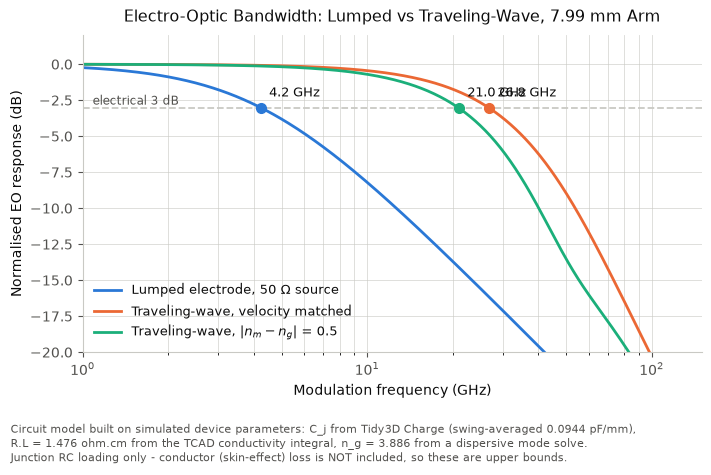

In [135]:
# Plot EO frequency response: lumped electrode versus traveling-wave, showing the bandwidth gain.

C_L, C_T, C_M, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#c9c9c4"

f_ax = np.logspace(9, 11.2, 500)
cj_avg = float(np.mean([C_tcad[float(V)] for V in V_list]))

C_lump = cj_avg * 1e-12 * (L_cm * 10)                 # pF/mm * mm -> pF -> F
f_l = 1 / (2 * np.pi * 50 * C_lump)
m_lump = 1 / np.sqrt(1 + (f_ax / f_l) ** 2)
m_tw0, _ = eo_response(f_ax, cj_avg, 0.0)
m_tw5, _ = eo_response(f_ax, cj_avg, 0.5)

fig, ax = plt.subplots(figsize=(7.2, 4.8))
for m, c, lab in ((m_lump, C_L, f"Lumped electrode, 50 $\\Omega$ source"),
                  (m_tw0, C_T, "Traveling-wave, velocity matched"),
                  (m_tw5, C_M, "Traveling-wave, $|n_m-n_g|$ = 0.5")):
    ax.semilogx(f_ax / 1e9, 20 * np.log10(m), lw=2, color=c, label=lab)
    below = np.where(m < 1 / np.sqrt(2))[0]
    if len(below):
        f3 = f_ax[below[0]] / 1e9
        ax.plot([f3], [-3.01], marker="o", ms=7, color=c, zorder=4)
        ax.annotate(f"{f3:.1f} GHz", (f3, -3.01), textcoords="offset points",
                    xytext=(6, 8), fontsize=9, color=INK, zorder=5)

ax.axhline(-3.01, color=GRID, lw=1.3, ls="--", zorder=1)
ax.text(1.05, -3.01, " electrical 3 dB", fontsize=8.5, color=INK2, va="bottom")
ax.set_xlabel("Modulation frequency (GHz)", color=INK)
ax.set_ylabel("Normalised EO response (dB)", color=INK)
ax.set_title(f"Electro-Optic Bandwidth: Lumped vs Traveling-Wave, {L_cm * 10:.2f} mm Arm",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower left", fontsize=9.5, labelcolor=INK)
ax.set_xlim(1, 150)
ax.set_ylim(-20, 2)
ax.grid(True, which="both", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         f"Circuit model built on simulated device parameters: C_j from Tidy3D Charge "
         f"(swing-averaged {cj_avg:.4f} pF/mm),\nR.L = {RL_j:.3f} ohm.cm from the TCAD conductivity "
         f"integral, n_g = {n_group:.3f} from a dispersive mode solve.\nJunction RC loading only - "
         f"conductor (skin-effect) loss is NOT included, so these are upper bounds.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseG_EO_bandwidth.png", dpi=300, facecolor="white")
plt.show()


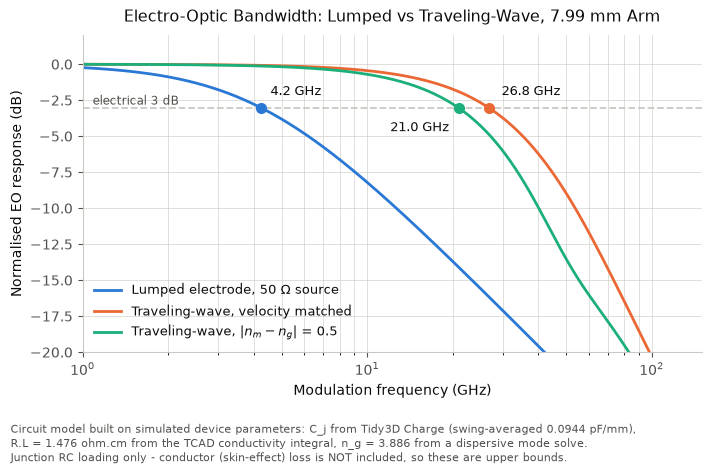

In [136]:
# Plot EO frequency response: lumped electrode versus traveling-wave, showing the bandwidth gain.

C_L, C_T, C_M, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#c9c9c4"

f_ax = np.logspace(9, 11.2, 500)
cj_avg = float(np.mean([C_tcad[float(V)] for V in V_list]))

C_lump = cj_avg * 1e-12 * (L_cm * 10)
f_l = 1 / (2 * np.pi * 50 * C_lump)
m_lump = 1 / np.sqrt(1 + (f_ax / f_l) ** 2)
m_tw0, _ = eo_response(f_ax, cj_avg, 0.0)
m_tw5, _ = eo_response(f_ax, cj_avg, 0.5)

fig, ax = plt.subplots(figsize=(7.2, 4.8))
series = ((m_lump, C_L, "Lumped electrode, 50 $\\Omega$ source", (7, 9), "left"),
          (m_tw0, C_T, "Traveling-wave, velocity matched", (9, 9), "left"),
          (m_tw5, C_M, "Traveling-wave, $|n_m-n_g|$ = 0.5", (-7, -17), "right"))
for m, c, lab, off, ha in series:
    ax.semilogx(f_ax / 1e9, 20 * np.log10(m), lw=2, color=c, label=lab)
    below = np.where(m < 1 / np.sqrt(2))[0]
    if len(below):
        f3 = f_ax[below[0]] / 1e9
        ax.plot([f3], [-3.01], marker="o", ms=7, color=c, zorder=4)
        ax.annotate(f"{f3:.1f} GHz", (f3, -3.01), textcoords="offset points",
                    xytext=off, ha=ha, fontsize=9, color=INK, zorder=5)

ax.axhline(-3.01, color=GRID, lw=1.3, ls="--", zorder=1)
ax.text(1.05, -3.01, " electrical 3 dB", fontsize=8.5, color=INK2, va="bottom")
ax.set_xlabel("Modulation frequency (GHz)", color=INK)
ax.set_ylabel("Normalised EO response (dB)", color=INK)
ax.set_title(f"Electro-Optic Bandwidth: Lumped vs Traveling-Wave, {L_cm * 10:.2f} mm Arm",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower left", fontsize=9.5, labelcolor=INK)
ax.set_xlim(1, 150)
ax.set_ylim(-20, 2)
ax.grid(True, which="both", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         f"Circuit model built on simulated device parameters: C_j from Tidy3D Charge "
         f"(swing-averaged {cj_avg:.4f} pF/mm),\nR.L = {RL_j:.3f} ohm.cm from the TCAD conductivity "
         f"integral, n_g = {n_group:.3f} from a dispersive mode solve.\nJunction RC loading only - "
         f"conductor (skin-effect) loss is NOT included, so these are upper bounds.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseG_EO_bandwidth.png", dpi=300, facecolor="white")
plt.show()


In [137]:
# Re-solve every figure input at the converged grid (mspw=120) so all published numbers agree.

MSPW = 120
SDA = lambda arr: td.SpatialDataArray(arr[np.newaxis, :, :],
                                      coords={"x": [0.0], "y": y_opt, "z": z_opt})

def lossy_medium(N, P, N0, P0):
    dn = soref_bennett_dn(N - N0, P - P0).astype(np.float64)
    alpha = B_N * N.astype(np.float64) + B_P * P.astype(np.float64)
    kappa = np.where(silicon_mask_opt, alpha * wavelength_cm / (4 * np.pi), 0.0)
    return td.CustomMedium.from_nk(n=SDA(n_si + dn), k=SDA(kappa),
                                   freq=freq0, interp_method="linear")

# 1) 0.15 um gap (Phase B baseline), all biases
neff15, loss15 = {}, {}
for V in V_list:
    neff15[V], loss15[V] = solve_rib_full(
        lossy_medium(N_tcad[V], P_tcad[V], N_tcad[0], P_tcad[0]),
        MSPW, f"r120_gap15_{abs(int(V))}V")
    print(f"gap 0.15  V={V:>+3.0f} | n_eff {neff15[V]:.8f} | loss {loss15[V]:7.4f} dB/cm")

# 2) attribution control: 0 V with the heavy access regions made transparent
alpha0 = B_N * N_tcad[0].astype(np.float64) + B_P * P_tcad[0].astype(np.float64)
kap_nh = np.where(silicon_mask_opt & ~heavy_mask, alpha0 * wavelength_cm / (4 * np.pi), 0.0)
med_nh = td.CustomMedium.from_nk(
    n=SDA(np.full_like(alpha0, n_si, dtype=np.float64)), k=SDA(kap_nh),
    freq=freq0, interp_method="linear")
_, loss_nh120 = solve_rib_full(med_nh, MSPW, "r120_gap15_0V_noheavy")
print(f"\nattribution control, 0 V heavy transparent: {loss_nh120:.4f} dB/cm")

# 3) remaining access gaps at -4 V (0.15 and 0.45 already done)
loss_gap120 = {0.15: loss15[-4], 0.45: loss_c[-4]}
for g in (0.25, 0.35):
    cr = charge_data_gap[g]["carrier_distribution"]
    N0g = tcad_on_optical_grid(cr.electrons, 0)
    P0g = tcad_on_optical_grid(cr.holes, 0)
    _, loss_gap120[g] = solve_rib_full(
        lossy_medium(N_gap[g], P_gap[g], N0g, P0g), MSPW, f"r120_gap{int(g * 100)}_4V")
    print(f"gap {g:.2f}  -4 V | loss {loss_gap120[g]:7.4f} dB/cm")

# 4) analytical-carrier sweep (note the (z,y) -> (y,z) transpose)
neff_an120 = {}
for V in voltages:
    dn_an = plasma_maps[V]["delta_n"].T.astype(np.float64)
    med = td.CustomMedium(permittivity=SDA((n_si + dn_an) ** 2), interp_method="linear")
    neff_an120[int(V)] = solve_rib_full(med, MSPW, f"r120_analyt_{abs(int(V))}V")[0]
    print(f"analytical V={int(V):>+3.0f} | n_eff {neff_an120[int(V)]:.8f}")

print(f"\ndone: {len(V_list) + 1 + 2 + len(voltages)} solves at mspw={MSPW}")
print(f"dn_eff at -4 V  | TCAD {neff15[-4] - neff15[0]:.4e} | "
      f"analytical {neff_an120[-4] - neff_an120[0]:.4e}")


13:28:40 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

13:28:41 Central Daylight Time Mode solver created with                         
                               task_id='fdve-5e3cc3d9-420a-470d-9814-0eecccbe63d
                               b',                                              
                               solver_id='mo-279bc4e7-6274-43d7-935b-2b17a604a25
                               b'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

13:28:47 Central Daylight Time Mode solver status: queued

13:28:54 Central Daylight Time Mode solver status: running

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

13:35:34 Central Daylight Time Mode solver status: queued

13:35:40 Central Daylight Time Mode solver status: running

13:35:48 Central Daylight Time Mode solver status: success

analytical V= -4 | n_eff 2.57918416

done: 13 solves at mspw=120
dn_eff at -4 V  | TCAD 9.8294e-05 | analytical 8.9488e-05


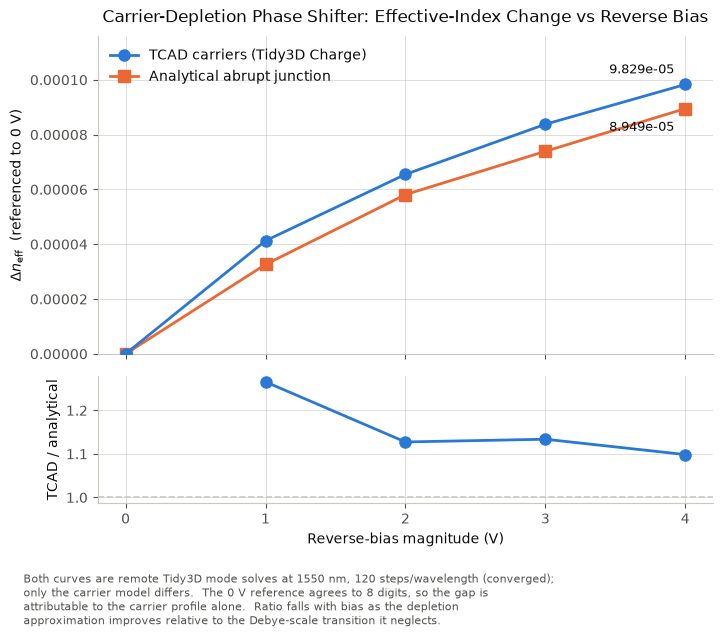

In [138]:
# Regenerate the Delta n_eff comparison at the converged grid (mspw=120).

C_TCAD, C_ANA, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

rb = np.array([abs(float(V)) for V in V_list])
dn_t = np.array([neff15[V] - neff15[0] for V in V_list])
dn_a = np.array([neff_an120[int(V)] - neff_an120[0] for V in V_list])
ratio = np.where(dn_a != 0, dn_t / np.where(dn_a == 0, 1, dn_a), np.nan)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(7.2, 6.4), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.10})

ax.plot(rb, dn_t, marker="o", ms=8, lw=2, color=C_TCAD,
        label="TCAD carriers (Tidy3D Charge)", zorder=3)
ax.plot(rb, dn_a, marker="s", ms=8, lw=2, color=C_ANA,
        label="Analytical abrupt junction", zorder=2)
ax.annotate(f"{dn_t[-1]:.3e}", (rb[-1], dn_t[-1]), textcoords="offset points",
            xytext=(-8, 8), ha="right", fontsize=9, color=INK)
ax.annotate(f"{dn_a[-1]:.3e}", (rb[-1], dn_a[-1]), textcoords="offset points",
            xytext=(-8, -16), ha="right", fontsize=9, color=INK)

ax.set_ylabel(r"$\Delta n_{\mathrm{eff}}$  (referenced to 0 V)", color=INK)
ax.set_title("Carrier-Depletion Phase Shifter: Effective-Index Change vs Reverse Bias",
             color=INK, fontsize=12, pad=10)
ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=INK)
ax.set_ylim(0, dn_t.max() * 1.18)

axr.plot(rb, ratio, marker="o", ms=8, lw=2, color=C_TCAD, zorder=3)
axr.axhline(1.0, color=GRID, lw=1.2, ls="--", zorder=1)
axr.set_ylabel("TCAD / analytical", color=INK, fontsize=10)
axr.set_xlabel("Reverse-bias magnitude (V)", color=INK)
axr.set_xticks(rb)

for a in (ax, axr):
    a.grid(True, color=GRID, lw=0.6, alpha=0.7)
    a.set_axisbelow(True)
    a.tick_params(colors=INK2)
    for s_ in ("top", "right"):
        a.spines[s_].set_visible(False)
    for s_ in ("left", "bottom"):
        a.spines[s_].set_color(GRID)

fig.text(0.012, 0.005,
         "Both curves are remote Tidy3D mode solves at 1550 nm, 120 steps/wavelength (converged);\n"
         "only the carrier model differs.  The 0 V reference agrees to 8 digits, so the gap is\n"
         "attributable to the carrier profile alone.  Ratio falls with bias as the depletion\n"
         "approximation improves relative to the Debye-scale transition it neglects.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.115, right=0.97, top=0.93, bottom=0.20)
plt.savefig("../Figures/PhaseB_delta_neff_TCAD_vs_analytical.png", dpi=300, facecolor="white")
plt.show()


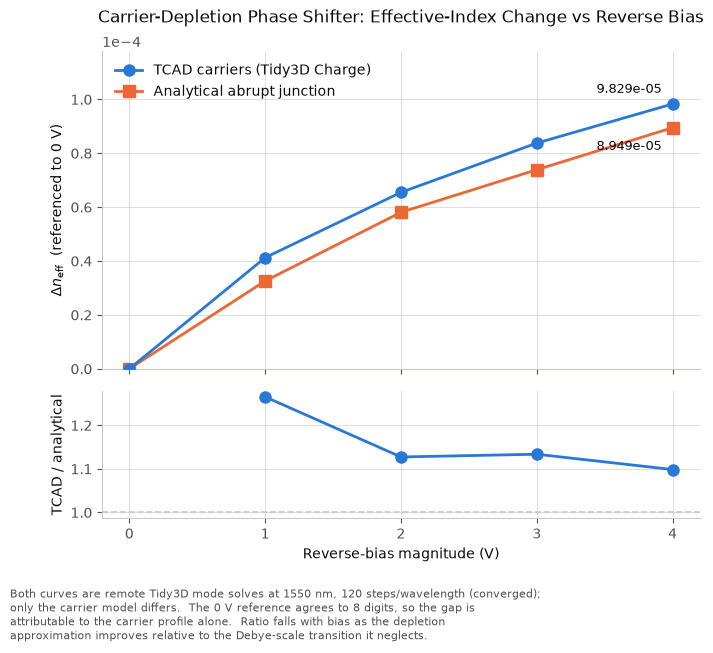

In [139]:
# Regenerate the Delta n_eff comparison at the converged grid (mspw=120).

C_TCAD, C_ANA, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

rb = np.array([abs(float(V)) for V in V_list])
dn_t = np.array([neff15[V] - neff15[0] for V in V_list])
dn_a = np.array([neff_an120[int(V)] - neff_an120[0] for V in V_list])
ratio = np.where(dn_a != 0, dn_t / np.where(dn_a == 0, 1, dn_a), np.nan)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(7.2, 6.4), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.10})

ax.plot(rb, dn_t, marker="o", ms=8, lw=2, color=C_TCAD,
        label="TCAD carriers (Tidy3D Charge)", zorder=3)
ax.plot(rb, dn_a, marker="s", ms=8, lw=2, color=C_ANA,
        label="Analytical abrupt junction", zorder=2)
ax.annotate(f"{dn_t[-1]:.3e}", (rb[-1], dn_t[-1]), textcoords="offset points",
            xytext=(-8, 8), ha="right", fontsize=9, color=INK)
ax.annotate(f"{dn_a[-1]:.3e}", (rb[-1], dn_a[-1]), textcoords="offset points",
            xytext=(-8, -16), ha="right", fontsize=9, color=INK)

ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))   # keep tick labels compact
ax.set_ylabel(r"$\Delta n_{\mathrm{eff}}$  (referenced to 0 V)", color=INK)
ax.set_title("Carrier-Depletion Phase Shifter: Effective-Index Change vs Reverse Bias",
             color=INK, fontsize=12, pad=10)
ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=INK)
ax.set_ylim(0, dn_t.max() * 1.20)

axr.plot(rb, ratio, marker="o", ms=8, lw=2, color=C_TCAD, zorder=3)
axr.axhline(1.0, color=GRID, lw=1.2, ls="--", zorder=1)
axr.set_ylabel("TCAD / analytical", color=INK, fontsize=10)
axr.set_xlabel("Reverse-bias magnitude (V)", color=INK)
axr.set_xticks(rb)

for a in (ax, axr):
    a.grid(True, color=GRID, lw=0.6, alpha=0.7)
    a.set_axisbelow(True)
    a.tick_params(colors=INK2)
    for s_ in ("top", "right"):
        a.spines[s_].set_visible(False)
    for s_ in ("left", "bottom"):
        a.spines[s_].set_color(GRID)

fig.text(0.012, 0.005,
         "Both curves are remote Tidy3D mode solves at 1550 nm, 120 steps/wavelength (converged);\n"
         "only the carrier model differs.  The 0 V reference agrees to 8 digits, so the gap is\n"
         "attributable to the carrier profile alone.  Ratio falls with bias as the depletion\n"
         "approximation improves relative to the Debye-scale transition it neglects.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.14, right=0.97, top=0.93, bottom=0.20)
plt.savefig("../Figures/PhaseB_delta_neff_TCAD_vs_analytical.png", dpi=300, facecolor="white")
plt.show()


pedestal = 5.6944 dB/cm; junction term 1.9734 -> 0.7855
access share of total at -4 V: 87.9 %


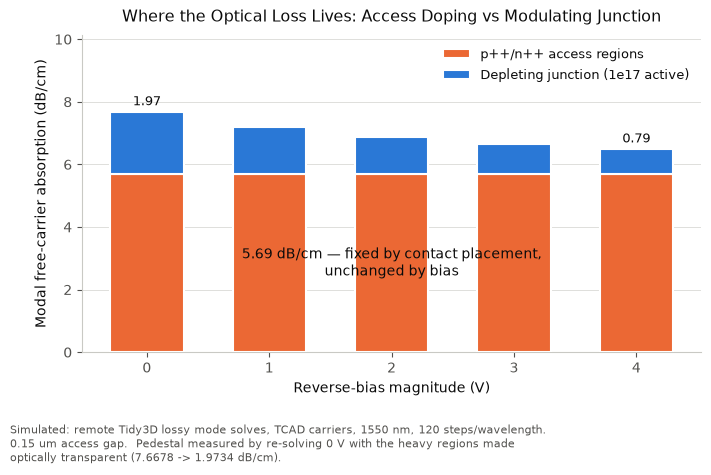

In [140]:
# Regenerate the modal-FCA decomposition at the converged grid (mspw=120).

C_ACCESS, C_JUNC, INK, INK2, GRID = "#eb6834", "#2a78d6", "#0b0b0b", "#52514e", "#c9c9c4"

rb = np.array([abs(float(V)) for V in V_list])
totals = np.array([loss15[V] for V in V_list])
pedestal120 = loss15[0] - loss_nh120
junction = totals - pedestal120
print(f"pedestal = {pedestal120:.4f} dB/cm; junction term {junction[0]:.4f} -> {junction[-1]:.4f}")
print(f"access share of total at -4 V: {100 * pedestal120 / totals[-1]:.1f} %")

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.bar(rb, np.full_like(totals, pedestal120), width=0.6, color=C_ACCESS,
       edgecolor="white", linewidth=1.5, zorder=3, label="p++/n++ access regions")
ax.bar(rb, junction, bottom=pedestal120, width=0.6, color=C_JUNC,
       edgecolor="white", linewidth=1.5, zorder=3, label="Depleting junction (1e17 active)")

ax.text(rb.mean(), pedestal120 / 2,
        f"{pedestal120:.2f} dB/cm — fixed by contact placement,\nunchanged by bias",
        ha="center", va="center", fontsize=10, color=INK, zorder=4)
for i in (0, len(rb) - 1):
    ax.annotate(f"{junction[i]:.2f}", (rb[i], pedestal120 + junction[i]),
                textcoords="offset points", xytext=(0, 5), ha="center",
                fontsize=9, color=INK, zorder=4)

ax.set_xlabel("Reverse-bias magnitude (V)", color=INK)
ax.set_ylabel("Modal free-carrier absorption (dB/cm)", color=INK)
ax.set_title("Where the Optical Loss Lives: Access Doping vs Modulating Junction",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="upper right", fontsize=9.5, labelcolor=INK)
ax.set_xticks(rb)
ax.set_ylim(0, totals.max() * 1.32)
ax.grid(True, axis="y", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         f"Simulated: remote Tidy3D lossy mode solves, TCAD carriers, 1550 nm, 120 steps/wavelength.\n"
         f"0.15 um access gap.  Pedestal measured by re-solving 0 V with the heavy regions made\n"
         f"optically transparent ({loss15[0]:.4f} -> {loss_nh120:.4f} dB/cm).",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseB_loss_decomposition.png", dpi=300, facecolor="white")
plt.show()


loss over Lpi, 0.15 um: [13.51   8.147  6.159  5.109]
loss over Lpi, 0.45 um: [3.189 1.644 1.075 0.776]
improvement at -4 V: 4.33 dB


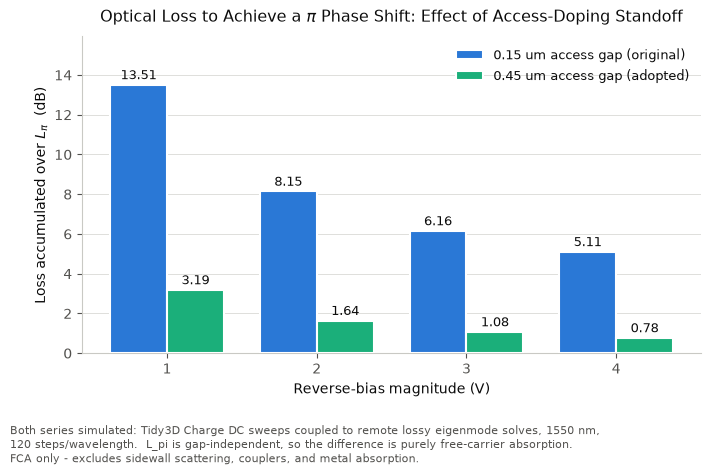

In [141]:
# Regenerate the pi-shift loss comparison at the converged grid (mspw=120).

C_OLD, C_NEW, INK, INK2, GRID = "#2a78d6", "#1baf7a", "#0b0b0b", "#52514e", "#c9c9c4"

Vb = [V for V in V_list if V != 0]
rb_b = np.array([abs(float(V)) for V in Vb])
Lpi15 = np.array([wavelength / (2 * abs(neff15[V] - neff15[0])) * 1e-4 for V in Vb])   # cm
Lpi45 = np.array([wavelength / (2 * abs(neff_c[V] - neff_c[0])) * 1e-4 for V in Vb])
old = np.array([loss15[V] for V in Vb]) * Lpi15
new = np.array([loss_c[V] for V in Vb]) * Lpi45
print(f"loss over Lpi, 0.15 um: {np.round(old, 3)}")
print(f"loss over Lpi, 0.45 um: {np.round(new, 3)}")
print(f"improvement at -4 V: {old[-1] - new[-1]:.2f} dB")

x, w = np.arange(len(Vb)), 0.38
fig, ax = plt.subplots(figsize=(7.2, 4.8))
b1 = ax.bar(x - w / 2, old, width=w, color=C_OLD, edgecolor="white", linewidth=1.5,
            zorder=3, label="0.15 um access gap (original)")
b2 = ax.bar(x + w / 2, new, width=w, color=C_NEW, edgecolor="white", linewidth=1.5,
            zorder=3, label="0.45 um access gap (adopted)")
for bars, vals in ((b1, old), (b2, new)):
    for bar, v in zip(bars, vals):
        ax.annotate(f"{v:.2f}", (bar.get_x() + bar.get_width() / 2, v),
                    textcoords="offset points", xytext=(0, 4), ha="center",
                    fontsize=9, color=INK, zorder=4)

ax.set_xticks(x, [f"{int(v)}" for v in rb_b])
ax.set_xlabel("Reverse-bias magnitude (V)", color=INK)
ax.set_ylabel(r"Loss accumulated over $L_\pi$  (dB)", color=INK)
ax.set_title(r"Optical Loss to Achieve a $\pi$ Phase Shift: Effect of Access-Doping Standoff",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="upper right", fontsize=9.5, labelcolor=INK)
ax.set_ylim(0, old.max() * 1.18)
ax.grid(True, axis="y", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         "Both series simulated: Tidy3D Charge DC sweeps coupled to remote lossy eigenmode solves, "
         "1550 nm,\n120 steps/wavelength.  L_pi is gap-independent, so the difference is purely "
         "free-carrier absorption.\nFCA only - excludes sidewall scattering, couplers, and metal "
         "absorption.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseB_loss_over_Lpi.png", dpi=300, facecolor="white")
plt.show()


access pedestal (dB/cm): [5.694 1.754 0.569 0.197]
measured lateral intensity decay: 11.21 per um  ->  1/e length 89 nm
irreducible junction floor: 0.7855 dB/cm = 0.620 dB over Lpi


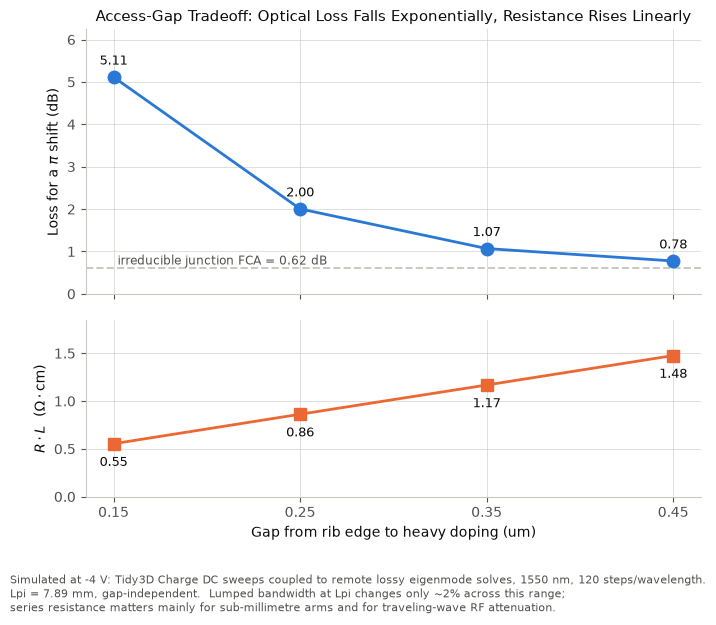

In [142]:
# Regenerate the access-gap tradeoff at the converged grid (mspw=120).

C_LOSS, C_RES, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

gaps_arr = np.array(gaps)
Lpi_cm = float(Lpi45[-1])                                  # Lpi at -4 V, gap-independent
loss_arr = np.array([loss_gap120[g] for g in gaps]) * Lpi_cm
RL_arr = np.array([RL_gap[g] for g in gaps])

junction_term = loss15[-4] - pedestal120                   # dB/cm, irreducible
floor = junction_term * Lpi_cm
ped = np.array([loss_gap120[g] - junction_term for g in gaps])
slope = np.polyfit(gaps_arr, np.log(ped), 1)[0]
print(f"access pedestal (dB/cm): {np.round(ped, 3)}")
print(f"measured lateral intensity decay: {-slope:.2f} per um  ->  1/e length {1000 / -slope:.0f} nm")
print(f"irreducible junction floor: {junction_term:.4f} dB/cm = {floor:.3f} dB over Lpi")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.2, 6.4), sharex=True,
                               gridspec_kw={"height_ratios": [1.5, 1], "hspace": 0.12})

ax1.plot(gaps_arr, loss_arr, marker="o", ms=9, lw=2, color=C_LOSS, zorder=3)
ax1.axhline(floor, color=GRID, lw=1.4, ls="--", zorder=1)
ax1.text(gaps_arr[0], floor, f" irreducible junction FCA = {floor:.2f} dB",
         fontsize=8.5, color=INK2, va="bottom", ha="left")
for x, v in zip(gaps_arr, loss_arr):
    ax1.annotate(f"{v:.2f}", (x, v), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=9, color=INK)
ax1.set_ylabel(r"Loss for a $\pi$ shift (dB)", color=INK)
ax1.set_title("Access-Gap Tradeoff: Optical Loss Falls Exponentially, Resistance Rises Linearly",
              color=INK, fontsize=11)
ax1.set_ylim(0, loss_arr.max() * 1.22)

ax2.plot(gaps_arr, RL_arr, marker="s", ms=9, lw=2, color=C_RES, zorder=3)
for x, v in zip(gaps_arr, RL_arr):
    ax2.annotate(f"{v:.2f}", (x, v), textcoords="offset points", xytext=(0, -16),
                 ha="center", fontsize=9, color=INK)
ax2.set_ylabel(r"$R \cdot L$  ($\Omega\cdot$cm)", color=INK)
ax2.set_xlabel("Gap from rib edge to heavy doping (um)", color=INK)
ax2.set_ylim(0, RL_arr.max() * 1.25)

for a in (ax1, ax2):
    a.set_xticks(gaps_arr)
    a.grid(True, color=GRID, lw=0.6, alpha=0.7)
    a.set_axisbelow(True)
    a.tick_params(colors=INK2)
    for s_ in ("top", "right"):
        a.spines[s_].set_visible(False)
    for s_ in ("left", "bottom"):
        a.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         f"Simulated at -4 V: Tidy3D Charge DC sweeps coupled to remote lossy eigenmode solves, "
         f"1550 nm, 120 steps/wavelength.\nLpi = {Lpi_cm * 10:.2f} mm, gap-independent.  Lumped "
         f"bandwidth at Lpi changes only ~2% across this range;\nseries resistance matters mainly "
         f"for sub-millimetre arms and for traveling-wave RF attenuation.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.115, right=0.97, top=0.92, bottom=0.19)
plt.savefig("../Figures/PhaseE_access_gap_tradeoff.png", dpi=300, facecolor="white")
plt.show()


L = 7.892 mm | no offset: IL 1.708 dB, ER 24.93 dB | pi offset: IL 1.230 dB


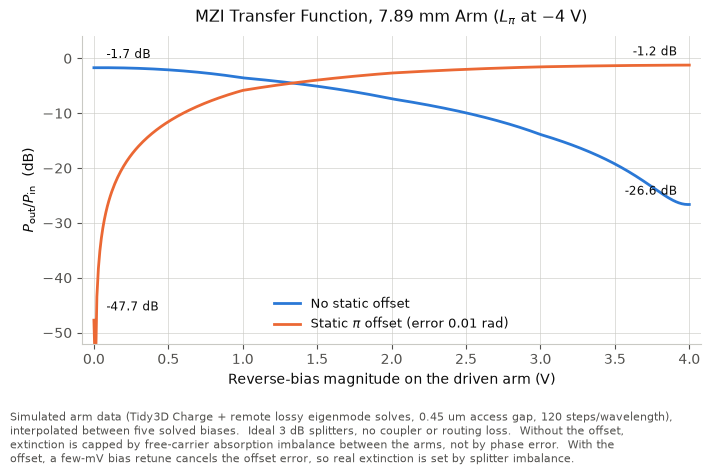

In [143]:
# Regenerate the MZI transfer function at the converged grid (mspw=120).

C_A, C_B, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

L_ARM = float(Lpi45[-1]) * 10          # mm, Lpi at -4 V from the converged solve
Lc = L_ARM * 0.1
Vfine = np.linspace(0, -4, 401)
dn_ref = np.array([neff_c[V] - neff_c[0] for V in V_list])
loss_ref = np.array([loss_c[V] for V in V_list])
Vg = np.array([float(V) for V in V_list])

dn_f = np.interp(-np.abs(Vfine), Vg[::-1], dn_ref[::-1])
loss_f = np.interp(-np.abs(Vfine), Vg[::-1], loss_ref[::-1])
ph_f = (2 * np.pi / wavelength) * dn_f * (L_ARM * 1000)
amp_f = np.sqrt(10 ** (-loss_f * Lc / 10))
amp0 = np.sqrt(10 ** (-loss_c[0] * Lc / 10))

OFF_ERR = 0.01
P_A = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0)) ** 2
P_B = np.abs(0.5 * (amp_f * np.exp(1j * ph_f) + amp0 * np.exp(1j * (np.pi + OFF_ERR)))) ** 2
print(f"L = {L_ARM:.3f} mm | no offset: IL {-10*np.log10(P_A[0]):.3f} dB, "
      f"ER {10*np.log10(P_A[0]/P_A[-1]):.2f} dB | pi offset: IL {-10*np.log10(P_B[-1]):.3f} dB")

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.plot(-Vfine, 10 * np.log10(P_A), lw=2, color=C_A, label="No static offset")
ax.plot(-Vfine, 10 * np.log10(P_B), lw=2, color=C_B,
        label=f"Static $\\pi$ offset (error {OFF_ERR} rad)")
for P in (P_A, P_B):
    for v in (0, -4):
        i = int(np.argmin(np.abs(Vfine - v)))
        at_left = -Vfine[i] < 2.0
        ax.annotate(f"{10 * np.log10(P[i]):.1f} dB", (-Vfine[i], 10 * np.log10(P[i])),
                    textcoords="offset points", xytext=(9 if at_left else -9, 7),
                    ha="left" if at_left else "right", fontsize=8.5, color=INK, zorder=5)

ax.set_xlabel("Reverse-bias magnitude on the driven arm (V)", color=INK)
ax.set_ylabel(r"$P_{\mathrm{out}}/P_{\mathrm{in}}$  (dB)", color=INK)
ax.set_title(f"MZI Transfer Function, {L_ARM:.2f} mm Arm " r"($L_\pi$ at $-4$ V)",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower center", fontsize=9.5, labelcolor=INK)
ax.set_xlim(-0.08, 4.08)
ax.set_ylim(-52, 4)
ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         "Simulated arm data (Tidy3D Charge + remote lossy eigenmode solves, 0.45 um access gap, "
         "120 steps/wavelength),\ninterpolated between five solved biases.  Ideal 3 dB splitters, no "
         "coupler or routing loss.  Without the offset,\nextinction is capped by free-carrier "
         "absorption imbalance between the arms, not by phase error.  With the\noffset, a few-mV bias "
         "retune cancels the offset error, so real extinction is set by splitter imbalance.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.26)
plt.savefig("../Figures/PhaseD_MZI_transfer_function.png", dpi=300, facecolor="white")
plt.show()


Lumped electrode, 50 $\Omega$ source       f_3dB = 4.3 GHz
Traveling-wave, velocity matched           f_3dB = 27.1 GHz
Traveling-wave, $|n_m-n_g|$ = 0.5          f_3dB = 21.2 GHz


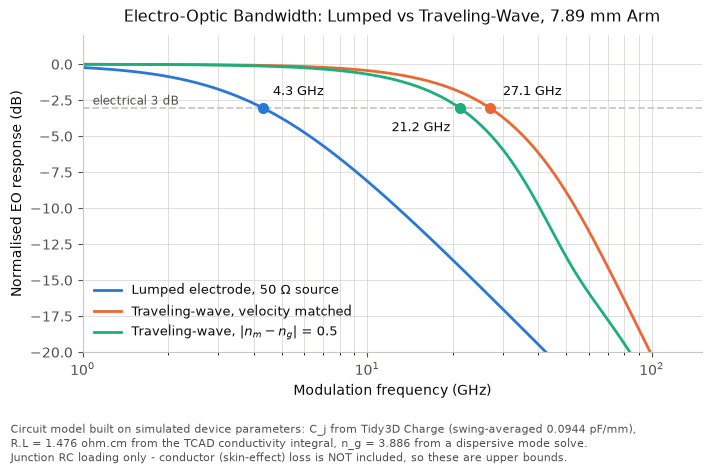

In [144]:
# Regenerate the EO bandwidth figure with the converged arm length so all figures share one Lpi.

L_cm = float(Lpi45[-1])                 # 0.7892 cm, the mspw=120 Lpi at -4 V
C_L, C_T, C_M, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#c9c9c4"

f_ax = np.logspace(9, 11.2, 500)
cj_avg = float(np.mean([C_tcad[float(V)] for V in V_list]))
C_lump = cj_avg * 1e-12 * (L_cm * 10)
f_l = 1 / (2 * np.pi * 50 * C_lump)
m_lump = 1 / np.sqrt(1 + (f_ax / f_l) ** 2)
m_tw0, _ = eo_response(f_ax, cj_avg, 0.0, L=L_cm)
m_tw5, _ = eo_response(f_ax, cj_avg, 0.5, L=L_cm)

fig, ax = plt.subplots(figsize=(7.2, 4.8))
series = ((m_lump, C_L, "Lumped electrode, 50 $\\Omega$ source", (7, 9), "left"),
          (m_tw0, C_T, "Traveling-wave, velocity matched", (9, 9), "left"),
          (m_tw5, C_M, "Traveling-wave, $|n_m-n_g|$ = 0.5", (-7, -17), "right"))
for m, c, lab, off, ha in series:
    ax.semilogx(f_ax / 1e9, 20 * np.log10(m), lw=2, color=c, label=lab)
    below = np.where(m < 1 / np.sqrt(2))[0]
    if len(below):
        f3 = f_ax[below[0]] / 1e9
        ax.plot([f3], [-3.01], marker="o", ms=7, color=c, zorder=4)
        ax.annotate(f"{f3:.1f} GHz", (f3, -3.01), textcoords="offset points",
                    xytext=off, ha=ha, fontsize=9, color=INK, zorder=5)
        print(f"{lab:<42} f_3dB = {f3:.1f} GHz")

ax.axhline(-3.01, color=GRID, lw=1.3, ls="--", zorder=1)
ax.text(1.05, -3.01, " electrical 3 dB", fontsize=8.5, color=INK2, va="bottom")
ax.set_xlabel("Modulation frequency (GHz)", color=INK)
ax.set_ylabel("Normalised EO response (dB)", color=INK)
ax.set_title(f"Electro-Optic Bandwidth: Lumped vs Traveling-Wave, {L_cm * 10:.2f} mm Arm",
             color=INK, fontsize=11.5, pad=10)
ax.legend(frameon=False, loc="lower left", fontsize=9.5, labelcolor=INK)
ax.set_xlim(1, 150)
ax.set_ylim(-20, 2)
ax.grid(True, which="both", color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.tick_params(colors=INK2)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_color(GRID)

fig.text(0.01, 0.005,
         f"Circuit model built on simulated device parameters: C_j from Tidy3D Charge "
         f"(swing-averaged {cj_avg:.4f} pF/mm),\nR.L = {RL_j:.3f} ohm.cm from the TCAD conductivity "
         f"integral, n_g = {n_group:.3f} from a dispersive mode solve.\nJunction RC loading only - "
         f"conductor (skin-effect) loss is NOT included, so these are upper bounds.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.11, right=0.97, top=0.90, bottom=0.24)
plt.savefig("../Figures/PhaseG_EO_bandwidth.png", dpi=300, facecolor="white")
plt.show()


In [145]:
# Parameterize the junction position so tolerance and offset optimization come from one sweep.

def build_charge_sim_yj(gap, y_junc):
    """Charge sim with the metallurgical junction at y_junc and heavy doping `gap` outside the rib."""
    h_in = RIB_EDGE + gap
    h_out = h_in + HEAVY_W
    slab_half = h_out
    dom_y = 2 * slab_half + 0.2

    p_act = td.ConstantDoping(center=(0, (-slab_half + y_junc) / 2, si_height / 2),
                              size=(td.inf, slab_half + y_junc, si_height),
                              concentration=NA_active)
    n_act = td.ConstantDoping(center=(0, (slab_half + y_junc) / 2, si_height / 2),
                              size=(td.inf, slab_half - y_junc, si_height),
                              concentration=ND_active)
    p_hvy = td.ConstantDoping(center=(0, -(h_in + HEAVY_W / 2), slab_height / 2),
                              size=(td.inf, HEAVY_W, slab_height), concentration=NA_heavy)
    n_hvy = td.ConstantDoping(center=(0, +(h_in + HEAVY_W / 2), slab_height / 2),
                              size=(td.inf, HEAVY_W, slab_height), concentration=ND_heavy)

    med = si_charge.updated_copy(N_a=[p_act, p_hvy], N_d=[n_act, n_hvy])
    slab = charge_slab.updated_copy(
        geometry=td.Box(center=(0, 0, slab_height / 2),
                        size=(td.inf, 2 * slab_half, slab_height)), medium=med)
    rib = charge_rib.updated_copy(medium=med)

    yc = h_in + HEAVY_W / 2
    pc_c, pc_s = p_contact.geometry.center, p_contact.geometry.size
    nc_c, nc_s = n_contact.geometry.center, n_contact.geometry.size
    pc = p_contact.updated_copy(geometry=td.Box(center=(pc_c[0], -yc, pc_c[2]), size=pc_s))
    nc = n_contact.updated_copy(geometry=td.Box(center=(nc_c[0], +yc, nc_c[2]), size=nc_s))

    return charge_sim.updated_copy(
        size=(0, dom_y, si_height), structures=[slab, rib, pc, nc],
        monitors=[carrier_monitor.updated_copy(size=(0, dom_y, si_height)),
                  capacitance_monitor.updated_copy(size=(0, dom_y, si_height))])

# Validate against the adopted baseline (gap 0.45, junction +0.05).
ref, new = sims_gap[0.45], build_charge_sim_yj(0.45, 0.05)
print(f"{'quantity':<30}{'rebuilt':>16}{'existing':>16}")
print(f"{'domain y (um)':<30}{new.size[1]:>16.3f}{ref.size[1]:>16.3f}")
for lbl, a, b in (("slab", new.structures[0], ref.structures[0]),
                  ("p_contact", new.structures[2], ref.structures[2]),
                  ("n_contact", new.structures[3], ref.structures[3])):
    print(f"{lbl + ' y-bounds':<30}"
          f"{f'{a.geometry.bounds[0][1]:+.3f}..{a.geometry.bounds[1][1]:+.3f}':>16}"
          f"{f'{b.geometry.bounds[0][1]:+.3f}..{b.geometry.bounds[1][1]:+.3f}':>16}")

print("\njunction sweep preview (p-side depletion band at -4 V, half-width 0.175 um):")
YJ = [0.00, 0.05, 0.10, 0.15, 0.20]
for yj in YJ:
    lo, hi = yj - 0.175, yj
    print(f"  y_j = {yj:+.2f} um -> p-side depletion spans {lo:+.3f}..{hi:+.3f} um, "
          f"centred at {(lo + hi) / 2:+.4f}  (mode peaks at 0.000)")
print(f"\nprediction: optimum near y_j = +0.088 um, where the p-side band centres on the mode peak")


15:23:55 Central Daylight Time WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

quantity                               rebuilt        existing
domain y (um)                            2.400           2.400
slab y-bounds                   -1.100..+1.100  -1.100..+1.100
p_contact y-bounds              -1.000..-0.800  -1.000..-0.800
n_contact y-bounds              +0.800..+1.000  +0.800..+1.000

junction sweep preview (p-side depletion band at -4 V, half-width 0.175 um):
  y_j = +0.00 um -> p-side depletion spans -0.175..+0.000 um, centred at -0.0875  (mode peaks at 0.000)
  y_j = +0.05 um -> p-side depletion spans -0.125..+0.050 um, centred at -0.0375  (mode peaks at 0.000)
  y_j = +0.10 um -> p-side depletion spans -0.075..+0.100 um, centred at +0.0125  (mode peaks at 0.000)
  y_j = +0.15 um -> p-side depletion spans -0.025..+0.150 um, centred at +0.0625  (mode peaks at 0.000)
  y_j = +0.20 um -> p-side depletion spans +0.025..+0.200 um, centred at +0.1125  (mode peaks at 0.000)

prediction: optimum near y_j = +0.088 um, where the p-side band centres on the mode pe

In [146]:
# Run Charge DC sweeps at each junction position (reusing the existing +0.05 um baseline).

YJ = [0.00, 0.05, 0.10, 0.15, 0.20]
sims_yj, ok = {}, True
for yj in YJ:
    sims_yj[yj] = build_charge_sim_yj(0.45, yj)
    try:
        sims_yj[yj].validate_pre_upload()
        st = "PASSED"
    except Exception as e:
        st, ok = f"{type(e).__name__}: {e}", False
    print(f"y_j {yj:+.2f} um | domain {sims_yj[yj].size[1]:.2f} um | validate: {st}")

if not ok:
    print("\nABORTED - fix validation before spending credits.")
else:
    charge_yj = {0.05: charge_data_gap[0.45]}          # nominal already solved
    for yj in YJ:
        if yj in charge_yj:
            print(f"\ny_j {yj:+.2f} um: reusing the existing adopted-baseline solve")
            continue
        tag = f"yj{int(round(yj * 1000)):03d}"
        job = web.Job(simulation=sims_yj[yj], task_name=f"PN_junction_{tag}",
                      folder_name="MZI_Modulator", verbose=True)
        charge_yj[yj] = job.run(path=f"../Results/PN_charge_{tag}.hdf5")
        print(f"y_j {yj:+.2f} um complete")

    print("\nTCAD capacitance (pF/mm), v = [-4,-3,-2,-1,0]:")
    for yj in YJ:
        cap = charge_yj[yj]["junction_capacitance"]
        print(f"  y_j {yj:+.2f}: {np.round(np.array(cap.hole_capacitance.values), 5)}")


15:25:35 Central Daylight Time WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

y_j +0.00 um | domain 2.40 um | validate: PASSED


                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

...

15:28:00 Central Daylight Time Loading results from                             
                               ..\Results\PN_charge_yj200.hdf5

                               WARNING: Structure at 'structures[0]' has bounds 
                               that extend exactly to simulation edges. This can
                               cause unexpected behavior. If intending to extend
                               the structure to infinity along one dimension,   
                               use td.inf as a size variable instead to make    
                               this explicit.                                   

                               WARNING: Suppressed 1 WARNING message.           

                               WARNING: Warning messages were found in the      
                               solver log. For more information, check          
                               'SimulationData.log' or use                      
                               'web.download_log(task_id)'.                     

y_j +0.20 um complete

TCAD capacitance (pF/mm), v = [-4,-3,-2,-1,0]:
  y_j +0.00: [0.06886 0.0738  0.08678 0.11177 0.12872]
  y_j +0.05: [0.06875 0.07371 0.0868  0.11201 0.12909]
  y_j +0.10: [0.04965 0.06164 0.08423 0.11199 0.12914]
  y_j +0.15: [0.04029 0.04401 0.05468 0.0918  0.12196]
  y_j +0.20: [0.03692 0.03958 0.04665 0.06073 0.0704 ]


In [147]:
# Optical solves at each junction position: Delta n_eff and loss at 0 and -4 V (mspw=120).

neff_yj, loss_yj = {}, {}
for yj in YJ:
    if yj == 0.05:
        neff_yj[yj] = {0: neff_c[0], -4: neff_c[-4]}
        loss_yj[yj] = {0: loss_c[0], -4: loss_c[-4]}
        print(f"y_j {yj:+.2f}: reusing adopted-baseline solves")
        continue
    cr = charge_yj[yj]["carrier_distribution"]
    N0, P0 = tcad_on_optical_grid(cr.electrons, 0), tcad_on_optical_grid(cr.holes, 0)
    N4, P4 = tcad_on_optical_grid(cr.electrons, -4), tcad_on_optical_grid(cr.holes, -4)
    neff_yj[yj], loss_yj[yj] = {}, {}
    for V, (N, P) in ((0, (N0, P0)), (-4, (N4, P4))):
        neff_yj[yj][V], loss_yj[yj][V] = solve_rib_full(
            lossy_medium(N, P, N0, P0), 120,
            f"opt_yj{int(round(yj * 1000)):03d}_{abs(V)}V")
    print(f"y_j {yj:+.2f} | n_eff(-4) {neff_yj[yj][-4]:.8f} | loss(-4) {loss_yj[yj][-4]:.4f} dB/cm")

cj_avg_yj = {yj: float(np.mean(np.array(charge_yj[yj]["junction_capacitance"]
                                        .hole_capacitance.values))) for yj in YJ}
print(f"\n{'y_j':>6} {'dn_eff':>11} {'Lpi mm':>8} {'VpiL':>7} {'loss':>8} {'loss@Lpi':>9} "
      f"{'C(-4V)':>8} {'f_lump':>8}")
print(f"{'um':>6} {'':>11} {'':>8} {'V.cm':>7} {'dB/cm':>8} {'dB':>9} {'pF/mm':>8} {'GHz':>8}")
best = None
for yj in YJ:
    dn = neff_yj[yj][-4] - neff_yj[yj][0]
    Lpi_mm = wavelength / (2 * abs(dn)) / 1000
    Lcm = Lpi_mm * 0.1
    c4 = float(np.array(charge_yj[yj]["junction_capacitance"].hole_capacitance.values)[0])
    f_l = 1 / (2 * np.pi * 50 * cj_avg_yj[yj] * Lpi_mm * 1e-12) / 1e9
    print(f"{yj:>+6.2f} {dn:>11.4e} {Lpi_mm:>8.3f} {4 * Lcm:>7.3f} {loss_yj[yj][-4]:>8.4f} "
          f"{loss_yj[yj][-4] * Lcm:>9.3f} {c4:>8.5f} {f_l:>8.2f}")
    if best is None or dn > best[1]:
        best = (yj, dn)
print(f"\nhighest dn_eff at y_j = {best[0]:+.2f} um  "
      f"({100 * (best[1] / (neff_yj[0.05][-4] - neff_yj[0.05][0]) - 1):+.1f}% vs nominal +0.05)")
print(f"geometric prediction was +0.088 um")


15:42:32 Central Daylight Time WARNING: The associated 'Simulation' object      
                               contains custom mediums. It will be automatically
                               restricted to the mode solver plane to reduce    
                               data for uploading. To force uploading the       
                               original 'Simulation' object use                 
                               'reduce_simulation=False'. Setting               
                               'reduce_simulation=True' will force simulation   
                               reduction in all cases and silence this warning. 

                               Mode solver created with                         
                               task_id='fdve-06aa019c-5ca0-4446-8b8e-d966e1d0ffd
                               b',                                              
                               solver_id='mo-0d5c032f-73c7-4ecd-8838-1a98361f4a2
                               f'.

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

15:42:39 Central Daylight Time Mode solver status: queued

15:42:43 Central Daylight Time Mode solver status: running

...

c:\Users\ericc\Silicon_MZI_Modulator\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

15:46:30 Central Daylight Time Mode solver status: queued

15:46:35 Central Daylight Time Mode solver status: running

15:46:47 Central Daylight Time Mode solver status: success

y_j +0.20 | n_eff(-4) 2.57914049 | loss(-4) 2.0034 dB/cm

   y_j      dn_eff   Lpi mm    VpiL     loss  loss@Lpi   C(-4V)   f_lump
    um                         V.cm    dB/cm        dB    pF/mm      GHz
 +0.00  8.7990e-05    8.808   3.523   0.9916     0.873  0.06886     3.85
 +0.05  9.8203e-05    7.892   3.157   0.9829     0.776  0.06875     4.29
 +0.10  9.7019e-05    7.988   3.195   1.1387     0.910  0.04965     4.56
 +0.15  7.3938e-05   10.482   4.193   1.5354     1.609  0.04029     4.30
 +0.20  4.5818e-05   16.915   6.766   2.0034     3.389  0.03692     3.70

highest dn_eff at y_j = +0.05 um  (+0.0% vs nominal +0.05)
geometric prediction was +0.088 um


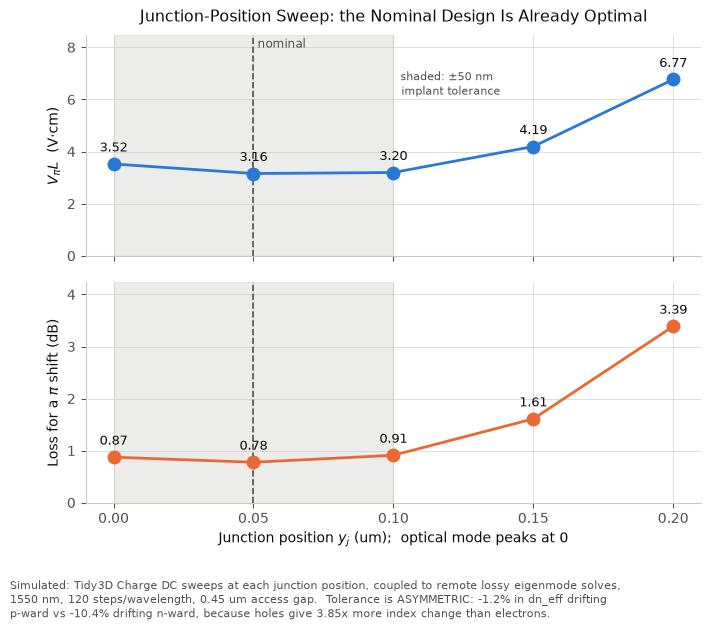

In [148]:
# Plot the junction-offset sweep: efficiency and loss both optimize at the nominal +0.05 um.

C_EFF, C_LOSS, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c9c9c4"

yj_arr = np.array(YJ)
dn_arr = np.array([neff_yj[y][-4] - neff_yj[y][0] for y in YJ])
Lpi_arr = wavelength / (2 * np.abs(dn_arr)) * 1e-4          # cm
vpil = 4 * Lpi_arr
lossL = np.array([loss_yj[y][-4] for y in YJ]) * Lpi_arr

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 6.4), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1], "hspace": 0.12})
for ax, vals, col, lab in ((a1, vpil, C_EFF, r"$V_\pi L$  (V$\cdot$cm)"),
                           (a2, lossL, C_LOSS, r"Loss for a $\pi$ shift (dB)")):
    ax.axvspan(0.0, 0.10, color=GRID, alpha=0.35, zorder=0)
    ax.axvline(0.05, color=INK2, lw=1.2, ls="--", zorder=1)
    ax.plot(yj_arr, vals, marker="o", ms=9, lw=2, color=col, zorder=3)
    for x, v in zip(yj_arr, vals):
        ax.annotate(f"{v:.2f}", (x, v), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=9, color=INK)
    ax.set_ylabel(lab, color=INK)
    ax.set_ylim(0, vals.max() * 1.25)
    ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK2)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    for s_ in ("left", "bottom"):
        ax.spines[s_].set_color(GRID)

a1.set_title("Junction-Position Sweep: the Nominal Design Is Already Optimal",
             color=INK, fontsize=11.5, pad=10)
a1.text(0.05, vpil.max() * 1.18, " nominal", fontsize=8.5, color=INK2, ha="left")
a1.text(0.10, vpil.max() * 1.05, "  shaded: $\\pm$50 nm\n  implant tolerance",
        fontsize=8, color=INK2, ha="left", va="top")
a2.set_xlabel("Junction position $y_j$ (um);  optical mode peaks at 0", color=INK)
a2.set_xticks(yj_arr)

fig.text(0.01, 0.005,
         "Simulated: Tidy3D Charge DC sweeps at each junction position, coupled to remote lossy "
         "eigenmode solves,\n1550 nm, 120 steps/wavelength, 0.45 um access gap.  Tolerance is "
         "ASYMMETRIC: -1.2% in dn_eff drifting\np-ward vs -10.4% drifting n-ward, because holes "
         "give 3.85x more index change than electrons.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.115, right=0.97, top=0.92, bottom=0.19)
plt.savefig("../Figures/PhaseF_junction_position.png", dpi=300, facecolor="white")
plt.show()


In [149]:
# Traveling-wave bandwidth at each junction position; RC attenuation scales as C^2.

y_cin = (RIB_EDGE + 0.45 + HEAVY_W / 2) - CONTACT_W / 2
RL_yj = {}
for yj in YJ:
    cr = charge_yj[yj]["carrier_distribution"]
    N4 = tcad_on_optical_grid(cr.electrons, -4)
    P4 = tcad_on_optical_grid(cr.holes, -4)
    med = sims_yj[yj].structures[0].medium
    NA = np.where(silicon_mask_opt, doping_map(med.N_a), 0.0)
    ND = np.where(silicon_mask_opt, doping_map(med.N_d), 0.0)
    mun = caughey_thomas(NA + ND, si_charge.mobility_n)
    mup = caughey_thomas(NA + ND, si_charge.mobility_p)
    Gv = (Q_e * (mun * N4 + mup * P4)).sum(axis=1) * dz_cm
    Gref = (Q_e * (mun * ND + mup * NA)).sum(axis=1) * dz_cm
    Gref = np.where(Gref > 0, Gref, np.nan)
    with np.errstate(invalid="ignore"):
        cond = (Gv / Gref) >= 0.5
    reach = np.abs(y_opt) <= y_cin
    pm = cond & reach & (y_opt < yj)
    nm = cond & reach & (y_opt > yj)
    RL_yj[yj] = float(np.sum(dy_cm / Gv[pm]) + np.sum(dy_cm / Gv[nm]))

def f3_of(cj, RLj, L, dnm):
    m, _ = eo_response(freqs, cj, dnm, RLj=RLj, L=L)
    b = np.where(m < 1 / np.sqrt(2))[0]
    return freqs[b[0]] / 1e9 if len(b) else np.inf

print(f"{'y_j':>6} {'R*L':>7} {'C(-4V)':>8} {'C_avg':>7} {'Lpi':>7} "
      f"{'f_lump':>8} {'TW small-sig':>13} {'TW large-sig':>13}")
print(f"{'um':>6} {'ohm.cm':>7} {'pF/mm':>8} {'pF/mm':>7} {'mm':>7} {'GHz':>8} {'GHz':>13} {'GHz':>13}")
for yj in YJ:
    dn = neff_yj[yj][-4] - neff_yj[yj][0]
    Lpi_mm = wavelength / (2 * abs(dn)) / 1000
    Lc = Lpi_mm * 0.1
    c4 = float(np.array(charge_yj[yj]["junction_capacitance"].hole_capacitance.values)[0])
    cav = cj_avg_yj[yj]
    f_l = 1 / (2 * np.pi * 50 * cav * Lpi_mm * 1e-12) / 1e9
    print(f"{yj:>+6.2f} {RL_yj[yj]:>7.3f} {c4:>8.5f} {cav:>7.5f} {Lpi_mm:>7.3f} "
          f"{f_l:>8.2f} {f3_of(c4, RL_yj[yj], Lc, 0.0):>12.1f}  "
          f"{f3_of(cav, RL_yj[yj], Lc, 0.0):>12.1f}")

b05, b10 = 0.05, 0.10
c4_05 = float(np.array(charge_yj[b05]["junction_capacitance"].hole_capacitance.values)[0])
c4_10 = float(np.array(charge_yj[b10]["junction_capacitance"].hole_capacitance.values)[0])
print(f"\nsmall-signal at -4 V, +0.05 -> +0.10 um:")
print(f"  C drops {100 * (1 - c4_10 / c4_05):.1f} %, R*L changes {100 * (RL_yj[b10] / RL_yj[b05] - 1):+.1f} %")
print(f"  alpha ~ R*C^2 changes {100 * ((RL_yj[b10] * c4_10 ** 2) / (RL_yj[b05] * c4_05 ** 2) - 1):+.1f} %")
print(f"  cost: loss per pi rises {100 * (0.910 / 0.776 - 1):.0f} %, VpiL rises "
      f"{100 * (3.195 / 3.157 - 1):.1f} %")


   y_j     R*L   C(-4V)   C_avg     Lpi   f_lump  TW small-sig  TW large-sig
    um  ohm.cm    pF/mm   pF/mm      mm      GHz           GHz           GHz
 +0.00   1.449  0.06886 0.09398   8.808     3.85         35.3          26.1
 +0.05   1.476  0.06875 0.09407   7.892     4.29         37.4          27.2
 +0.10   1.482  0.04965 0.08733   7.988     4.56         51.3          28.8
 +0.15   1.483  0.04029 0.07055  10.482     4.30         55.2          31.4
 +0.20   1.505  0.03692 0.05085  16.915     3.70         47.1          33.8

small-signal at -4 V, +0.05 -> +0.10 um:
  C drops 27.8 %, R*L changes +0.4 %
  alpha ~ R*C^2 changes -47.6 %
  cost: loss per pi rises 17 %, VpiL rises 1.2 %


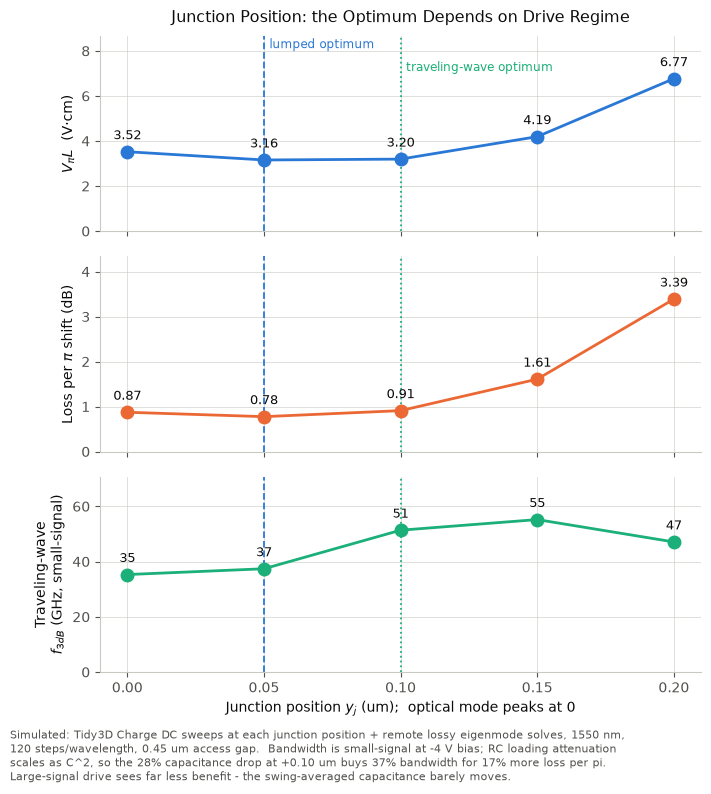

In [150]:
# Plot the junction-position sweep with bandwidth, showing the optimum depends on drive regime.

C_EFF, C_LOSS, C_BW = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#c9c9c4"

yj_arr = np.array(YJ)
dn_arr = np.array([neff_yj[y][-4] - neff_yj[y][0] for y in YJ])
Lpi_arr = wavelength / (2 * np.abs(dn_arr)) * 1e-4
vpil = 4 * Lpi_arr
lossL = np.array([loss_yj[y][-4] for y in YJ]) * Lpi_arr
bw = np.array([f3_of(float(np.array(charge_yj[y]["junction_capacitance"]
                                    .hole_capacitance.values)[0]),
                     RL_yj[y], Lpi_arr[i], 0.0) for i, y in enumerate(YJ)])

fig, axes = plt.subplots(3, 1, figsize=(7.2, 8.0), sharex=True,
                         gridspec_kw={"hspace": 0.13})
panels = ((axes[0], vpil, C_EFF, r"$V_\pi L$  (V$\cdot$cm)", "{:.2f}"),
          (axes[1], lossL, C_LOSS, r"Loss per $\pi$ shift (dB)", "{:.2f}"),
          (axes[2], bw, C_BW, "Traveling-wave\n" r"$f_{3dB}$ (GHz, small-signal)", "{:.0f}"))
for ax, vals, col, lab, fmt in panels:
    ax.axvline(0.05, color=C_EFF, lw=1.3, ls="--", zorder=1)
    ax.axvline(0.10, color=C_BW, lw=1.3, ls=":", zorder=1)
    ax.plot(yj_arr, vals, marker="o", ms=9, lw=2, color=col, zorder=3)
    for x, v in zip(yj_arr, vals):
        ax.annotate(fmt.format(v), (x, v), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=9, color=INK)
    ax.set_ylabel(lab, color=INK, fontsize=10)
    ax.set_ylim(0, vals.max() * 1.28)
    ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK2)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    for s_ in ("left", "bottom"):
        ax.spines[s_].set_color(GRID)

axes[0].set_title("Junction Position: the Optimum Depends on Drive Regime",
                  color=INK, fontsize=11.5, pad=10)
axes[0].text(0.052, vpil.max() * 1.20, "lumped optimum", fontsize=8.5, color=C_EFF, ha="left")
axes[0].text(0.102, vpil.max() * 1.05, "traveling-wave optimum", fontsize=8.5,
             color=C_BW, ha="left")
axes[2].set_xlabel("Junction position $y_j$ (um);  optical mode peaks at 0", color=INK)
axes[2].set_xticks(yj_arr)

fig.text(0.01, 0.005,
         "Simulated: Tidy3D Charge DC sweeps at each junction position + remote lossy eigenmode "
         "solves, 1550 nm,\n120 steps/wavelength, 0.45 um access gap.  Bandwidth is small-signal at "
         "-4 V bias; RC loading attenuation\nscales as C^2, so the 28% capacitance drop at +0.10 um "
         "buys 37% bandwidth for 17% more loss per pi.\nLarge-signal drive sees far less benefit - "
         "the swing-averaged capacitance barely moves.",
         fontsize=8, color=INK2, va="bottom")

fig.subplots_adjust(left=0.135, right=0.97, top=0.94, bottom=0.145)
plt.savefig("../Figures/PhaseF_junction_position.png", dpi=300, facecolor="white")
plt.show()
